# Library

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, RandomizedSearchCV
import missingno as msno
from pyampute.exploration.mcar_statistical_tests import MCARTest
import plotly.express as px
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_regression, SelectFromModel
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

import warnings 
warnings.filterwarnings('ignore')

# Load Data

In [2]:
df = pd.read_csv('/Users/admin/Documents/ML Engineer/ML Project/ML Project with AI/Final Workflow/regression_1/data/greenhouse_crop_yields.csv')

In [3]:
df.head()

,greenhouse_id,crop_type,variety,planting_date,harvest_date,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
0,1.0,Tomato,Beefsteak,2023-11-02,2024-01-08,67.0,27.6,25.8,30.6,73.6,917.0,16821.0,10.0,9.8,167.0,74.0,154.0,1.3,6.1,9.19
1,3.0,Cucumber,English,2023-11-01,2024-01-03,63.0,24.4,21.0,27.3,80.8,782.0,27483.0,10.0,9.2,174.0,82.0,126.0,3.2,6.3,7.42
2,5.0,Tomato,Beefsteak,2023-02-02,2023-04-19,76.0,23.9,20.6,26.0,76.6,821.0,30516.0,10.0,7.0,234.0,64.0,243.0,1.2,6.0,20.86
3,5.0,Tomato,Heirloom,2023-07-29,2023-10-21,84.0,26.7,25.5,29.6,76.1,710.0,43580.0,15.1,5.4,167.0,63.0,234.0,0.8,6.0,22.09
4,4.0,Cucumber,Slicing,2023-02-07,2023-04-15,67.0,24.1,22.4,26.5,69.8,921.0,22283.0,10.0,8.4,102.0,98.0,173.0,1.1,7.4,6.42


## Quick Check (Simple EDA)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10400 entries, 0 to 10399
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        10400 non-null  float64
 1   crop_type            10400 non-null  object 
 2   variety              10400 non-null  object 
 3   planting_date        10400 non-null  object 
 4   harvest_date         10400 non-null  object 
 5   days_to_maturity     10400 non-null  float64
 6   avg_temperature_C    9858 non-null   float64
 7   min_temperature_C    9858 non-null   float64
 8   max_temperature_C    9858 non-null   float64
 9   humidity_percent     9858 non-null   float64
 10  co2_ppm              9827 non-null   float64
 11  light_intensity_lux  9858 non-null   float64
 12  photoperiod_hours    10400 non-null  float64
 13  irrigation_mm        10400 non-null  float64
 14  fertilizer_N_kg_ha   9342 non-null   float64
 15  fertilizer_P_kg_ha   9342 non-null  

In [5]:
df.shape

(10400, 20)

In [6]:
df.describe()

,greenhouse_id,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
count,10400.000000,10400.000000,9858.000000,9858.000000,9858.000000,9858.000000,9827.000000,9858.000000,10400.000000,10400.000000,9342.000000,9342.000000,9342.000000,10276.000000,10098.000000,10400.000000
mean,3.013077,64.519327,23.421627,21.529580,25.306868,74.972327,799.832095,30045.450193,12.457529,7.003212,163.441661,71.442518,166.801006,1.831666,6.505070,12.381656
std,1.417617,16.392426,3.401036,3.473755,3.455992,8.582842,148.809930,8086.985394,2.308943,1.982951,42.012956,21.597035,39.775813,1.448331,0.500929,4.961302
min,1.000000,29.000000,10.600000,8.400000,12.000000,47.200000,348.000000,5000.000000,9.800000,1.000000,80.000000,30.000000,80.000000,-0.200000,5.000000,0.100000
25%,2.000000,53.000000,21.700000,19.700000,23.500000,68.900000,698.000000,24016.750000,10.000000,5.600000,130.000000,55.000000,137.000000,0.600000,6.200000,8.567500
50%,3.000000,65.000000,24.100000,22.200000,25.900000,75.000000,800.000000,30106.500000,12.100000,7.000000,163.000000,69.000000,167.000000,1.600000,6.500000,11.905000
75%,4.000000,77.000000,25.800000,24.000000,27.700000,81.200000,903.000000,36075.750000,14.800000,8.400000,194.000000,87.000000,194.000000,2.800000,6.800000,15.750000
max,5.000000,100.000000,32.000000,30.400000,34.200000,100.000000,1200.000000,57094.000000,16.200000,13.500000,250.000000,121.000000,250.000000,6.700000,8.000000,30.640000


array([[<Axes: title={'center': 'greenhouse_id'}>,
        <Axes: title={'center': 'days_to_maturity'}>,
        <Axes: title={'center': 'avg_temperature_C'}>,
        <Axes: title={'center': 'min_temperature_C'}>],
       [<Axes: title={'center': 'max_temperature_C'}>,
        <Axes: title={'center': 'humidity_percent'}>,
        <Axes: title={'center': 'co2_ppm'}>,
        <Axes: title={'center': 'light_intensity_lux'}>],
       [<Axes: title={'center': 'photoperiod_hours'}>,
        <Axes: title={'center': 'irrigation_mm'}>,
        <Axes: title={'center': 'fertilizer_N_kg_ha'}>,
        <Axes: title={'center': 'fertilizer_P_kg_ha'}>],
       [<Axes: title={'center': 'fertilizer_K_kg_ha'}>,
        <Axes: title={'center': 'pest_severity'}>,
        <Axes: title={'center': 'soil_pH'}>,
        <Axes: title={'center': 'yield_kg_per_m2'}>]], dtype=object)

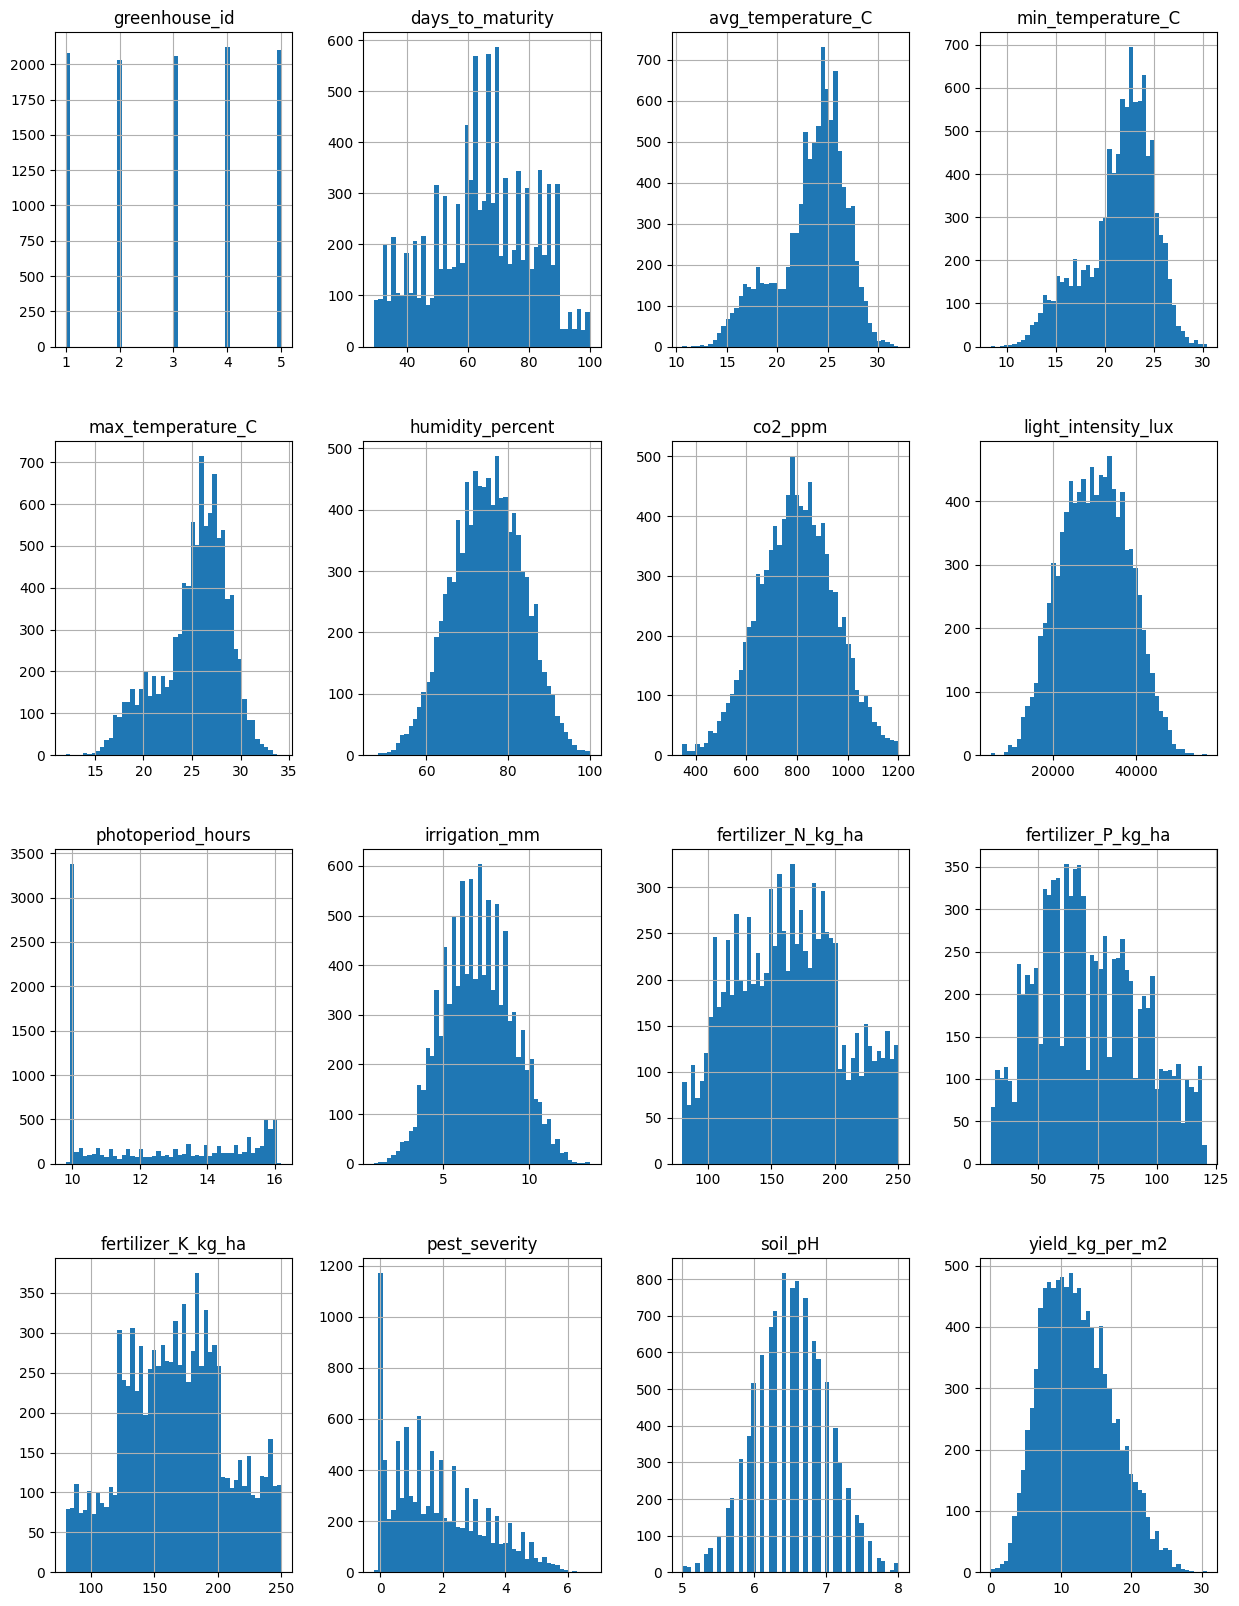

In [7]:
df.hist(bins=50, figsize=(15, 20))

## Changes Data Type

In [8]:
df['greenhouse_id'] = df['greenhouse_id'].astype('object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10400 entries, 0 to 10399
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        10400 non-null  object 
 1   crop_type            10400 non-null  object 
 2   variety              10400 non-null  object 
 3   planting_date        10400 non-null  object 
 4   harvest_date         10400 non-null  object 
 5   days_to_maturity     10400 non-null  float64
 6   avg_temperature_C    9858 non-null   float64
 7   min_temperature_C    9858 non-null   float64
 8   max_temperature_C    9858 non-null   float64
 9   humidity_percent     9858 non-null   float64
 10  co2_ppm              9827 non-null   float64
 11  light_intensity_lux  9858 non-null   float64
 12  photoperiod_hours    10400 non-null  float64
 13  irrigation_mm        10400 non-null  float64
 14  fertilizer_N_kg_ha   9342 non-null   float64
 15  fertilizer_P_kg_ha   9342 non-null  

## Drop Unecessary Column

In [10]:
df = df.drop(['planting_date', 'harvest_date'], axis=1)

In [11]:
df.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
0,1.0,Tomato,Beefsteak,67.0,27.6,25.8,30.6,73.6,917.0,16821.0,10.0,9.8,167.0,74.0,154.0,1.3,6.1,9.19
1,3.0,Cucumber,English,63.0,24.4,21.0,27.3,80.8,782.0,27483.0,10.0,9.2,174.0,82.0,126.0,3.2,6.3,7.42
2,5.0,Tomato,Beefsteak,76.0,23.9,20.6,26.0,76.6,821.0,30516.0,10.0,7.0,234.0,64.0,243.0,1.2,6.0,20.86
3,5.0,Tomato,Heirloom,84.0,26.7,25.5,29.6,76.1,710.0,43580.0,15.1,5.4,167.0,63.0,234.0,0.8,6.0,22.09
4,4.0,Cucumber,Slicing,67.0,24.1,22.4,26.5,69.8,921.0,22283.0,10.0,8.4,102.0,98.0,173.0,1.1,7.4,6.42


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10400 entries, 0 to 10399
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        10400 non-null  object 
 1   crop_type            10400 non-null  object 
 2   variety              10400 non-null  object 
 3   days_to_maturity     10400 non-null  float64
 4   avg_temperature_C    9858 non-null   float64
 5   min_temperature_C    9858 non-null   float64
 6   max_temperature_C    9858 non-null   float64
 7   humidity_percent     9858 non-null   float64
 8   co2_ppm              9827 non-null   float64
 9   light_intensity_lux  9858 non-null   float64
 10  photoperiod_hours    10400 non-null  float64
 11  irrigation_mm        10400 non-null  float64
 12  fertilizer_N_kg_ha   9342 non-null   float64
 13  fertilizer_P_kg_ha   9342 non-null   float64
 14  fertilizer_K_kg_ha   9342 non-null   float64
 15  pest_severity        10276 non-null 

# Split Train-Test

In [13]:
train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

In [14]:
train_set.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
561,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,11.9,7.7,167.0,92.0,175.0,1.6,5.9,12.42
1162,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,15.2,4.6,228.0,98.0,208.0,4.0,6.2,20.27
9573,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,11.5,3.8,124.0,37.0,146.0,0.5,6.2,11.51
9045,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,10.6,6.9,168.0,83.0,221.0,2.6,7.1,13.24
3209,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,31260.0,14.3,8.5,NaN,NaN,NaN,2.9,5.8,9.56


In [15]:
train_set.shape

(8320, 18)

In [16]:
train_set.describe()

,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
count,8320.000000,7896.000000,7896.000000,7896.000000,7896.000000,7870.000000,7896.000000,8320.000000,8320.000000,7469.000000,7469.000000,7469.000000,8221.000000,8081.000000,8320.000000
mean,64.717668,23.454027,21.556864,25.339906,74.917427,800.230114,30030.201494,12.451755,7.007440,163.746820,71.492435,166.879636,1.830848,6.505531,12.402939
std,16.386257,3.388636,3.465412,3.442503,8.568983,148.264159,8084.598545,2.309676,1.983244,42.217282,21.602959,39.626062,1.452566,0.497161,4.979355
min,29.000000,10.600000,8.400000,12.000000,47.200000,348.000000,5000.000000,9.800000,1.200000,80.000000,30.000000,80.000000,-0.200000,5.000000,0.100000
25%,53.000000,21.800000,19.800000,23.500000,68.900000,699.000000,24039.750000,10.000000,5.600000,129.000000,55.000000,137.000000,0.600000,6.200000,8.550000
50%,65.000000,24.100000,22.200000,26.000000,75.000000,800.000000,30107.500000,12.100000,7.000000,163.000000,69.000000,167.000000,1.600000,6.500000,11.950000
75%,77.000000,25.800000,24.000000,27.700000,81.025000,902.000000,36053.250000,14.800000,8.400000,194.000000,87.000000,194.000000,2.800000,6.800000,15.740000
max,100.000000,32.000000,30.400000,34.200000,100.000000,1200.000000,56075.000000,16.200000,13.500000,250.000000,121.000000,250.000000,6.700000,8.000000,30.640000


array([[<Axes: title={'center': 'days_to_maturity'}>,
        <Axes: title={'center': 'avg_temperature_C'}>,
        <Axes: title={'center': 'min_temperature_C'}>,
        <Axes: title={'center': 'max_temperature_C'}>],
       [<Axes: title={'center': 'humidity_percent'}>,
        <Axes: title={'center': 'co2_ppm'}>,
        <Axes: title={'center': 'light_intensity_lux'}>,
        <Axes: title={'center': 'photoperiod_hours'}>],
       [<Axes: title={'center': 'irrigation_mm'}>,
        <Axes: title={'center': 'fertilizer_N_kg_ha'}>,
        <Axes: title={'center': 'fertilizer_P_kg_ha'}>,
        <Axes: title={'center': 'fertilizer_K_kg_ha'}>],
       [<Axes: title={'center': 'pest_severity'}>,
        <Axes: title={'center': 'soil_pH'}>,
        <Axes: title={'center': 'yield_kg_per_m2'}>, <Axes: >]],
      dtype=object)

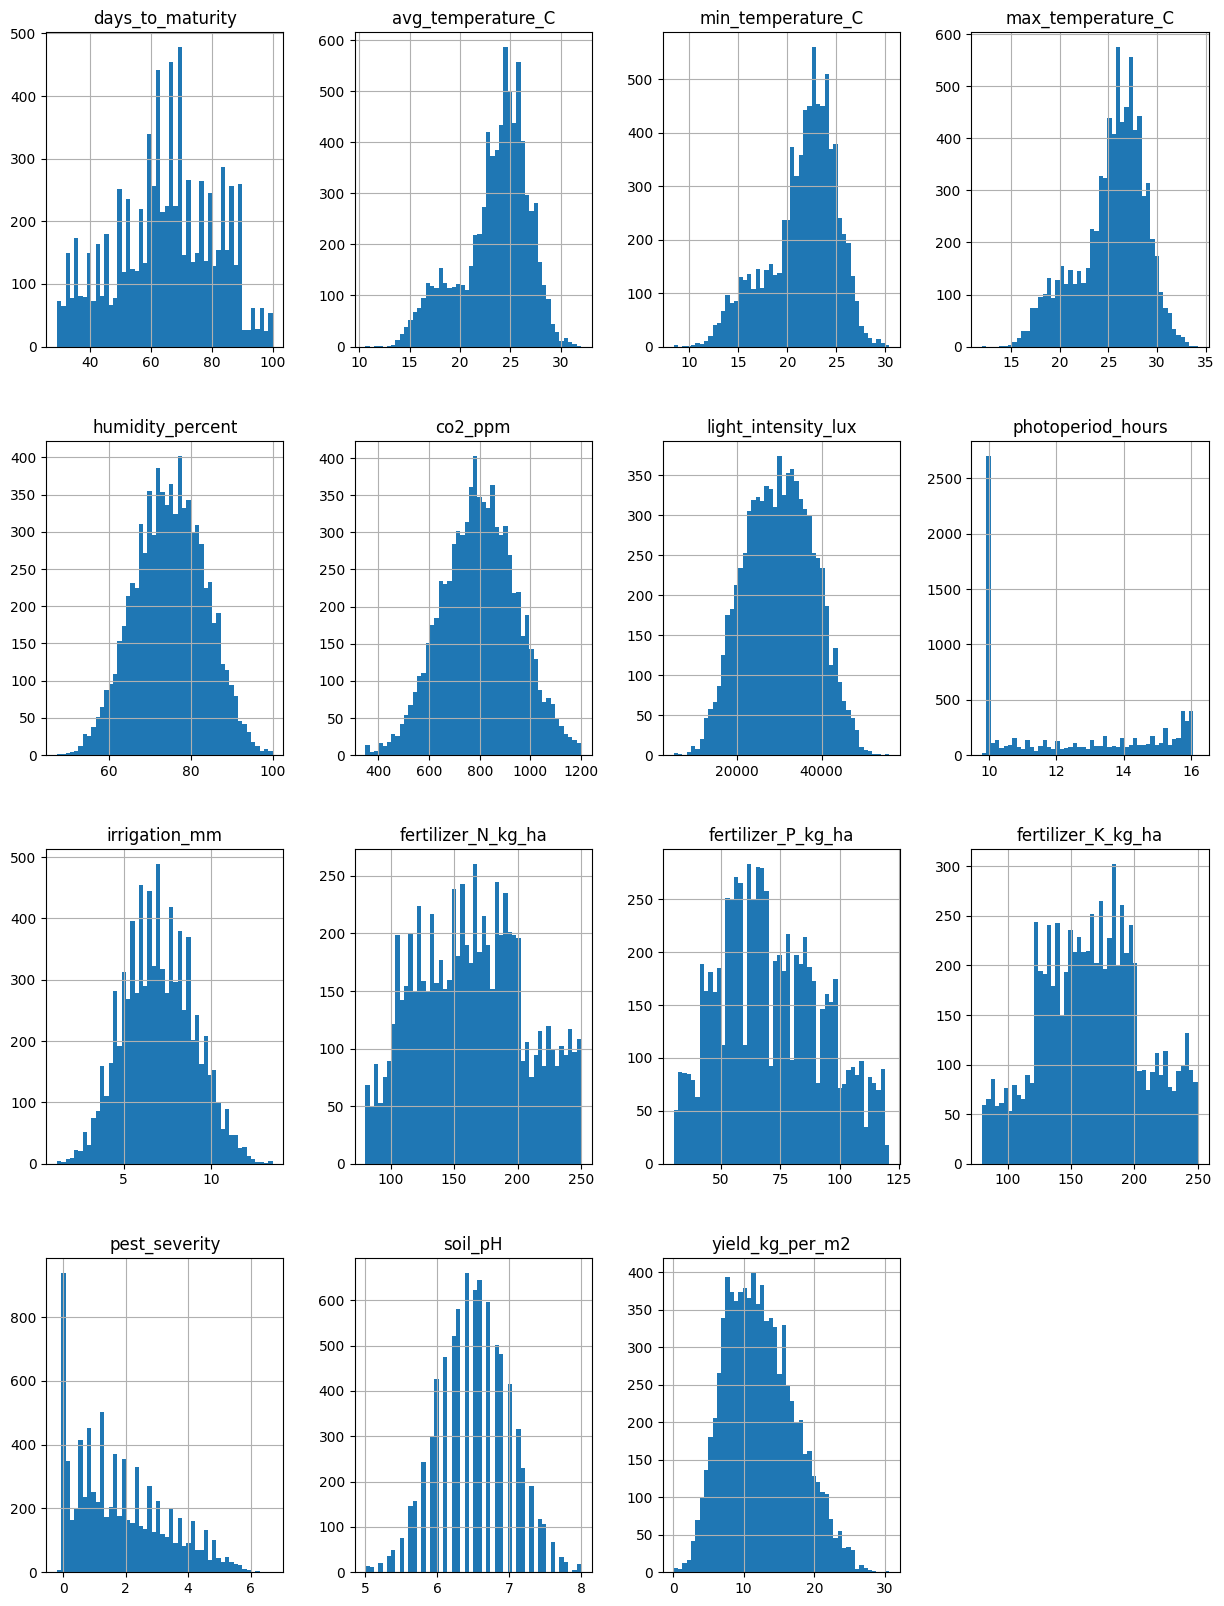

In [17]:
train_set.hist(bins=50, figsize=(15, 20))

# EDA for Train Set

## Univariate EDA

In [18]:
train_set.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8320 entries, 561 to 7270
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        8320 non-null   object 
 1   crop_type            8320 non-null   object 
 2   variety              8320 non-null   object 
 3   days_to_maturity     8320 non-null   float64
 4   avg_temperature_C    7896 non-null   float64
 5   min_temperature_C    7896 non-null   float64
 6   max_temperature_C    7896 non-null   float64
 7   humidity_percent     7896 non-null   float64
 8   co2_ppm              7870 non-null   float64
 9   light_intensity_lux  7896 non-null   float64
 10  photoperiod_hours    8320 non-null   float64
 11  irrigation_mm        8320 non-null   float64
 12  fertilizer_N_kg_ha   7469 non-null   float64
 13  fertilizer_P_kg_ha   7469 non-null   float64
 14  fertilizer_K_kg_ha   7469 non-null   float64
 15  pest_severity        8221 non-null   floa

In [19]:
train_set.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
561,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,11.9,7.7,167.0,92.0,175.0,1.6,5.9,12.42
1162,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,15.2,4.6,228.0,98.0,208.0,4.0,6.2,20.27
9573,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,11.5,3.8,124.0,37.0,146.0,0.5,6.2,11.51
9045,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,10.6,6.9,168.0,83.0,221.0,2.6,7.1,13.24
3209,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,31260.0,14.3,8.5,NaN,NaN,NaN,2.9,5.8,9.56


In [20]:
train_set.sample(10)

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
4972,1.0,Tomato,Heirloom,78.0,23.6,22.0,25.3,87.1,777.0,31650.0,14.1,5.4,NaN,NaN,NaN,1.0,6.3,24.20
7370,3.0,Tomato,Cherry,74.0,24.2,21.5,26.0,73.1,722.0,30469.0,13.9,7.1,178.0,109.0,248.0,0.0,6.2,15.78
818,2.0,Cucumber,Slicing,60.0,22.4,20.0,23.7,82.2,806.0,33882.0,13.9,7.5,122.0,97.0,160.0,1.3,5.8,11.74
3310,5.0,Cucumber,Pickling,66.0,24.3,21.4,27.3,75.8,878.0,38019.0,14.3,8.4,112.0,68.0,156.0,0.0,6.2,11.19
8258,1.0,Lettuce,Butterhead,33.0,18.3,17.2,20.8,73.7,809.0,34259.0,10.0,4.5,136.0,36.0,103.0,0.0,6.3,9.91
6406,1.0,Cucumber,Slicing,64.0,22.8,21.3,24.6,81.3,941.0,38953.0,13.2,7.6,194.0,87.0,184.0,1.2,6.7,13.87
607,2.0,Lettuce,Iceberg,49.0,14.2,10.4,17.3,63.6,908.0,42974.0,15.0,4.0,89.0,45.0,127.0,0.0,7.4,7.07
3295,3.0,Tomato,Beefsteak,90.0,24.9,21.8,28.1,80.1,871.0,37657.0,11.5,7.1,242.0,72.0,186.0,2.9,NaN,22.79
9531,4.0,Lettuce,Iceberg,45.0,16.9,15.3,19.5,63.4,837.0,20699.0,10.0,7.4,144.0,36.0,142.0,2.6,6.7,3.99
9901,1.0,Tomato,Heirloom,66.0,25.9,24.3,27.3,71.9,763.0,21359.0,10.0,8.2,NaN,NaN,NaN,1.7,7.3,17.12


In [21]:
#cols_to_exclude = ['planting_date_day', 'planting_date_month', 'planting_date_year', 'harvest_date_day', 'harvest_date_month', 'harvest_date_year']

num_data = train_set.select_dtypes(include=['number']).columns
cat_data = train_set.select_dtypes(include=['object']).columns

### Numerical

#### Distribution Plot

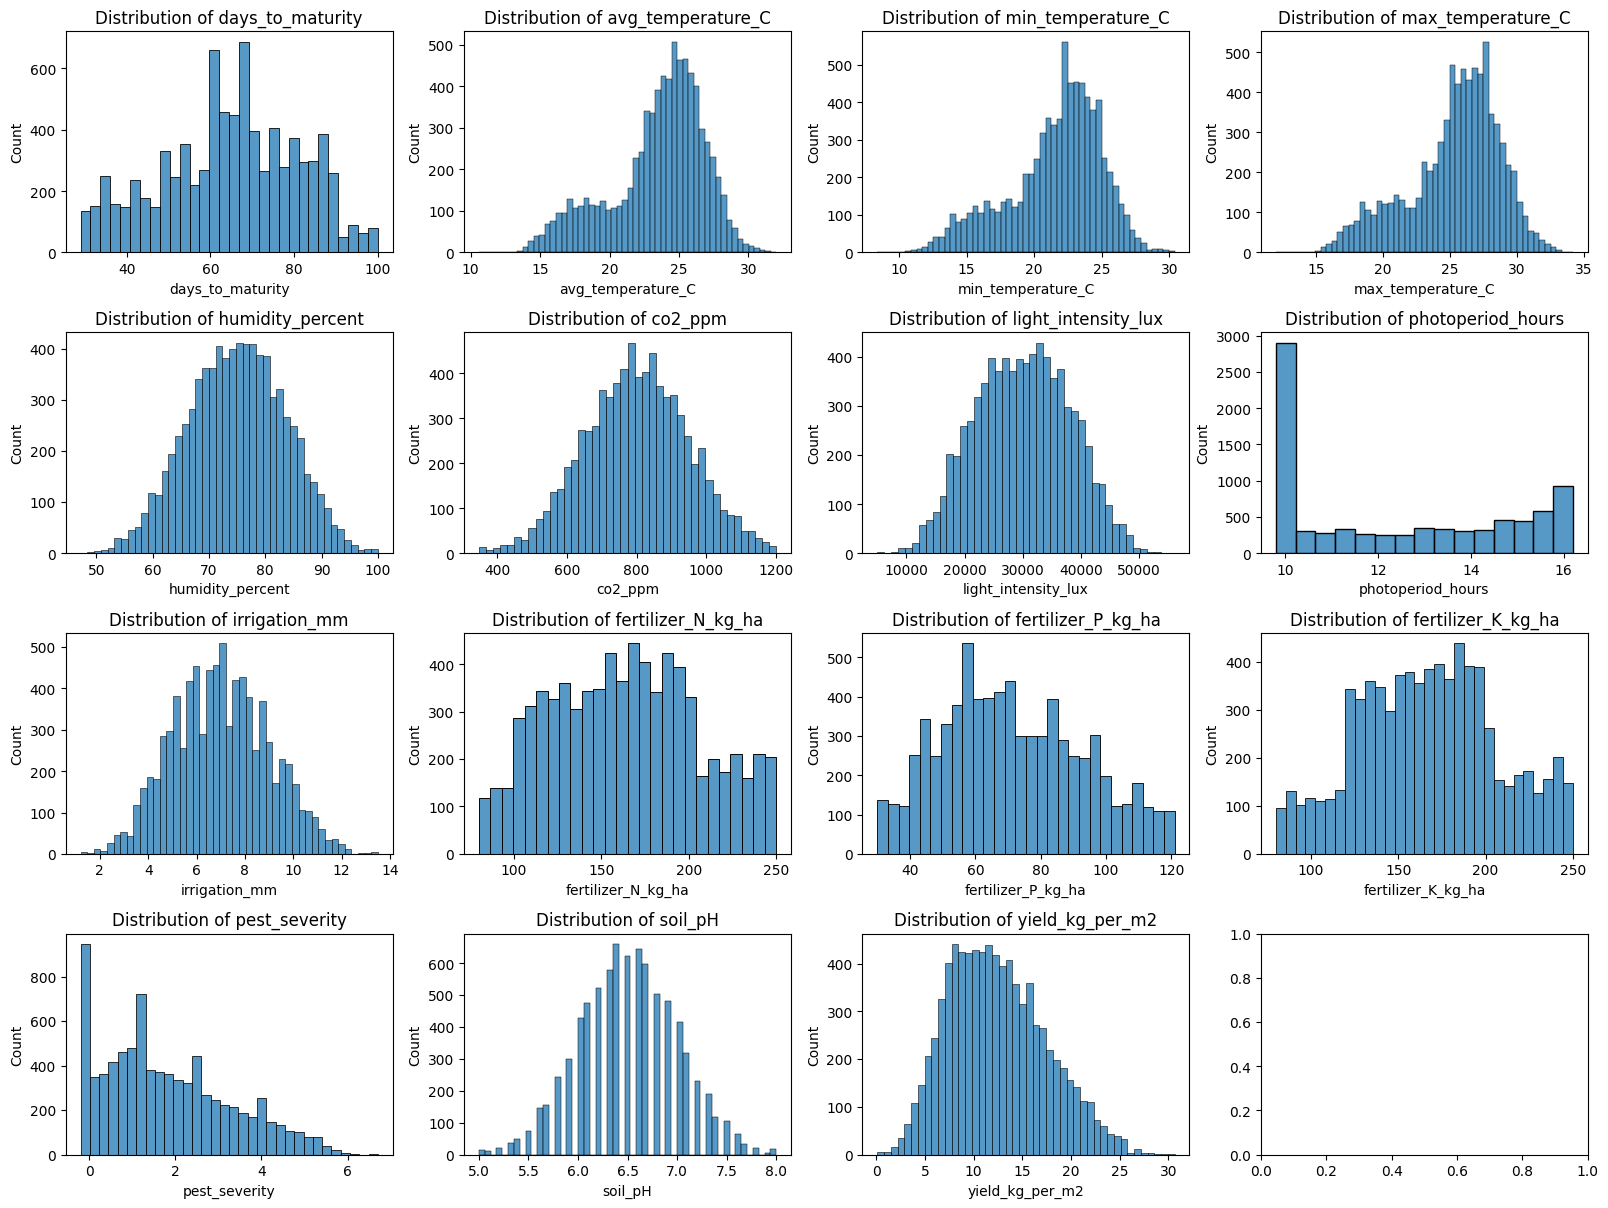

In [22]:
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(16, 12))
axs = axs.flatten()

for i, column in enumerate(num_data):
    sns.histplot(train_set[column], ax=axs[i])
    axs[i].set_title(f'Distribution of {column}')

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
plt.show()

In [23]:
""" 
- greenhouse_id
Distribusi uniform/seragam — semua nilai 1 sampai 5 memiliki frekuensi yang hampir sama (~1600 baris). Wajar karena ini ID kategorikal yang direpresentasikan sebagai angka.

- days_to_maturity
Distribusi multimodal — ada beberapa puncak di sekitar nilai 40, 65, dan 80. Ini mencerminkan perbedaan jenis tanaman (crop_type) yang masing-masing memiliki masa panen berbeda.

- avg_temperature_C, min_temperature_C, max_temperature_C
Ketiganya membentuk distribusi mendekati normal (bell-shaped) dengan sedikit skew ke kiri. Puncak berada di sekitar 23-25°C. Wajar karena pengukuran suhu greenhouse cenderung terkontrol.

- humidity_percent
Distribusi mendekati normal, puncak di sekitar 70-80%. Sedikit skew ke kiri karena ada ekor di sisi kanan mendekati 100%.

- co2_ppm
Distribusi mendekati normal dan simetris, puncak di sekitar 800 ppm. Ini distribusi yang paling "bersih" di antara semua kolom.

- light_intensity_lux
Distribusi mendekati normal, puncak di sekitar 28.000-32.000 lux. Relatif simetris dengan sedikit ekor di kanan.

- photoperiod_hours
Distribusi trimodal dengan spike besar di nilai ~10 jam — jauh lebih tinggi dari nilai lainnya. Kemudian ada dua puncak kecil di sekitar 12 dan 14-16 jam. Ini kemungkinan mencerminkan pengaturan pencahayaan yang memang diset pada nilai-nilai tertentu secara sengaja.

- irrigation_mm
Distribusi mendekati normal, puncak di sekitar 6-8 mm. Sedikit skew ke kanan.

- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha
Ketiganya memiliki distribusi relatif uniform/datar dengan sedikit variasi antar bin. Tidak ada puncak yang dominan — artinya penggunaan pupuk bervariasi cukup merata di semua rentang nilai.

- pest_severity
Distribusi right-skewed (positif) — mayoritas data menumpuk di nilai rendah (0-2) dan ekor memanjang ke kanan hingga ~6. Artinya sebagian besar tanaman mengalami serangan hama yang ringan hingga sedang.

- soil_pH
Distribusi mendekati normal, puncak di sekitar 6.5-7.0. Rentang cukup sempit (5.0-8.0) yang mencerminkan kondisi pH tanah yang dikontrol dalam greenhouse.

- yield_kg_per_m2 (target variable)
Distribusi right-skewed — puncak di sekitar 10-15 kg/m², dengan ekor memanjang ke kanan hingga ~30. Artinya sebagian besar hasil panen berada di kisaran menengah, dengan sedikit tanaman yang menghasilkan sangat tinggi.
"""

' \n- greenhouse_id\nDistribusi uniform/seragam — semua nilai 1 sampai 5 memiliki frekuensi yang hampir sama (~1600 baris). Wajar karena ini ID kategorikal yang direpresentasikan sebagai angka.\n\n- days_to_maturity\nDistribusi multimodal — ada beberapa puncak di sekitar nilai 40, 65, dan 80. Ini mencerminkan perbedaan jenis tanaman (crop_type) yang masing-masing memiliki masa panen berbeda.\n\n- avg_temperature_C, min_temperature_C, max_temperature_C\nKetiganya membentuk distribusi mendekati normal (bell-shaped) dengan sedikit skew ke kiri. Puncak berada di sekitar 23-25°C. Wajar karena pengukuran suhu greenhouse cenderung terkontrol.\n\n- humidity_percent\nDistribusi mendekati normal, puncak di sekitar 70-80%. Sedikit skew ke kiri karena ada ekor di sisi kanan mendekati 100%.\n\n- co2_ppm\nDistribusi mendekati normal dan simetris, puncak di sekitar 800 ppm. Ini distribusi yang paling "bersih" di antara semua kolom.\n\n- light_intensity_lux\nDistribusi mendekati normal, puncak di seki

#### Missing Values

In [24]:
missing_values = train_set.isnull().sum()
percentage_missing = round((missing_values / len(train_set)) * 100, 3)

missing_data_info = pd.DataFrame({
    'missing_value': missing_values,
    'percentage_missing': percentage_missing
})

missing_data_info

,missing_value,percentage_missing
greenhouse_id,0,0.000
crop_type,0,0.000
variety,0,0.000
days_to_maturity,0,0.000
avg_temperature_C,424,5.096
min_temperature_C,424,5.096
max_temperature_C,424,5.096
humidity_percent,424,5.096
co2_ppm,450,5.409
light_intensity_lux,424,5.096


<Axes: >

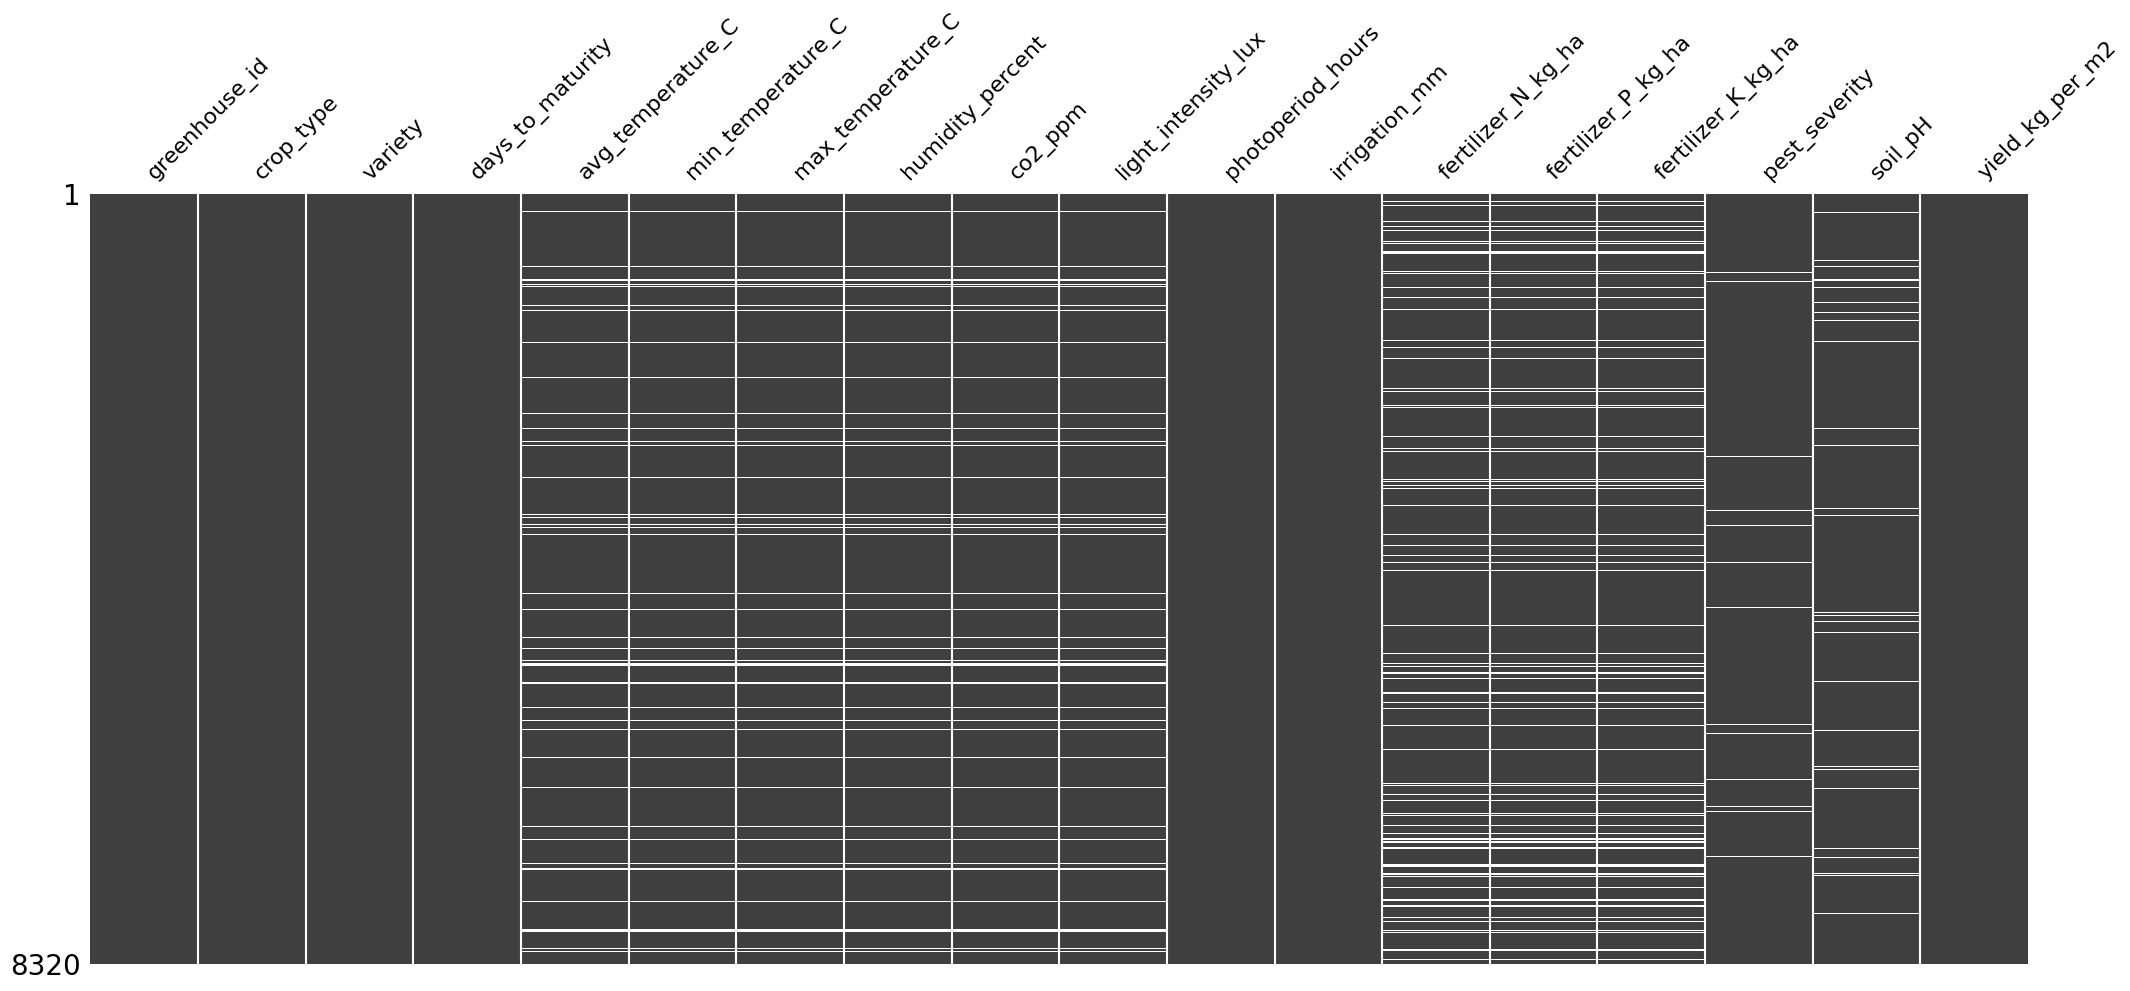

In [25]:
msno.matrix(train_set, sparkline=False)

In [26]:
"""
greenhouse_id, crop_type, variety, days_to_maturity, semua kolom tanggal, photoperiod_hours, irrigation_mm, yield_kg_per_m2	Solid gelap -> tidak ada missing sama sekali
avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm	-> Garis putih yang muncul bersamaan di baris yang sama — missing secara serentak
fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha	-> Garis putih lebih banyak dan tebal — missing paling besar (~10%). Menunjukkan garis putih yang muncul bersamaan di baris yang sama
pest_severity -> Garis putih sangat sedikit — missing kecil (~1.2%)
soil_pH	-> Garis putih sedang — missing ~2.9%
"""

'\ngreenhouse_id, crop_type, variety, days_to_maturity, semua kolom tanggal, photoperiod_hours, irrigation_mm, yield_kg_per_m2\tSolid gelap -> tidak ada missing sama sekali\navg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm\t-> Garis putih yang muncul bersamaan di baris yang sama — missing secara serentak\nfertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha\t-> Garis putih lebih banyak dan tebal — missing paling besar (~10%). Menunjukkan garis putih yang muncul bersamaan di baris yang sama\npest_severity -> Garis putih sangat sedikit — missing kecil (~1.2%)\nsoil_pH\t-> Garis putih sedang — missing ~2.9%\n'

<Axes: >

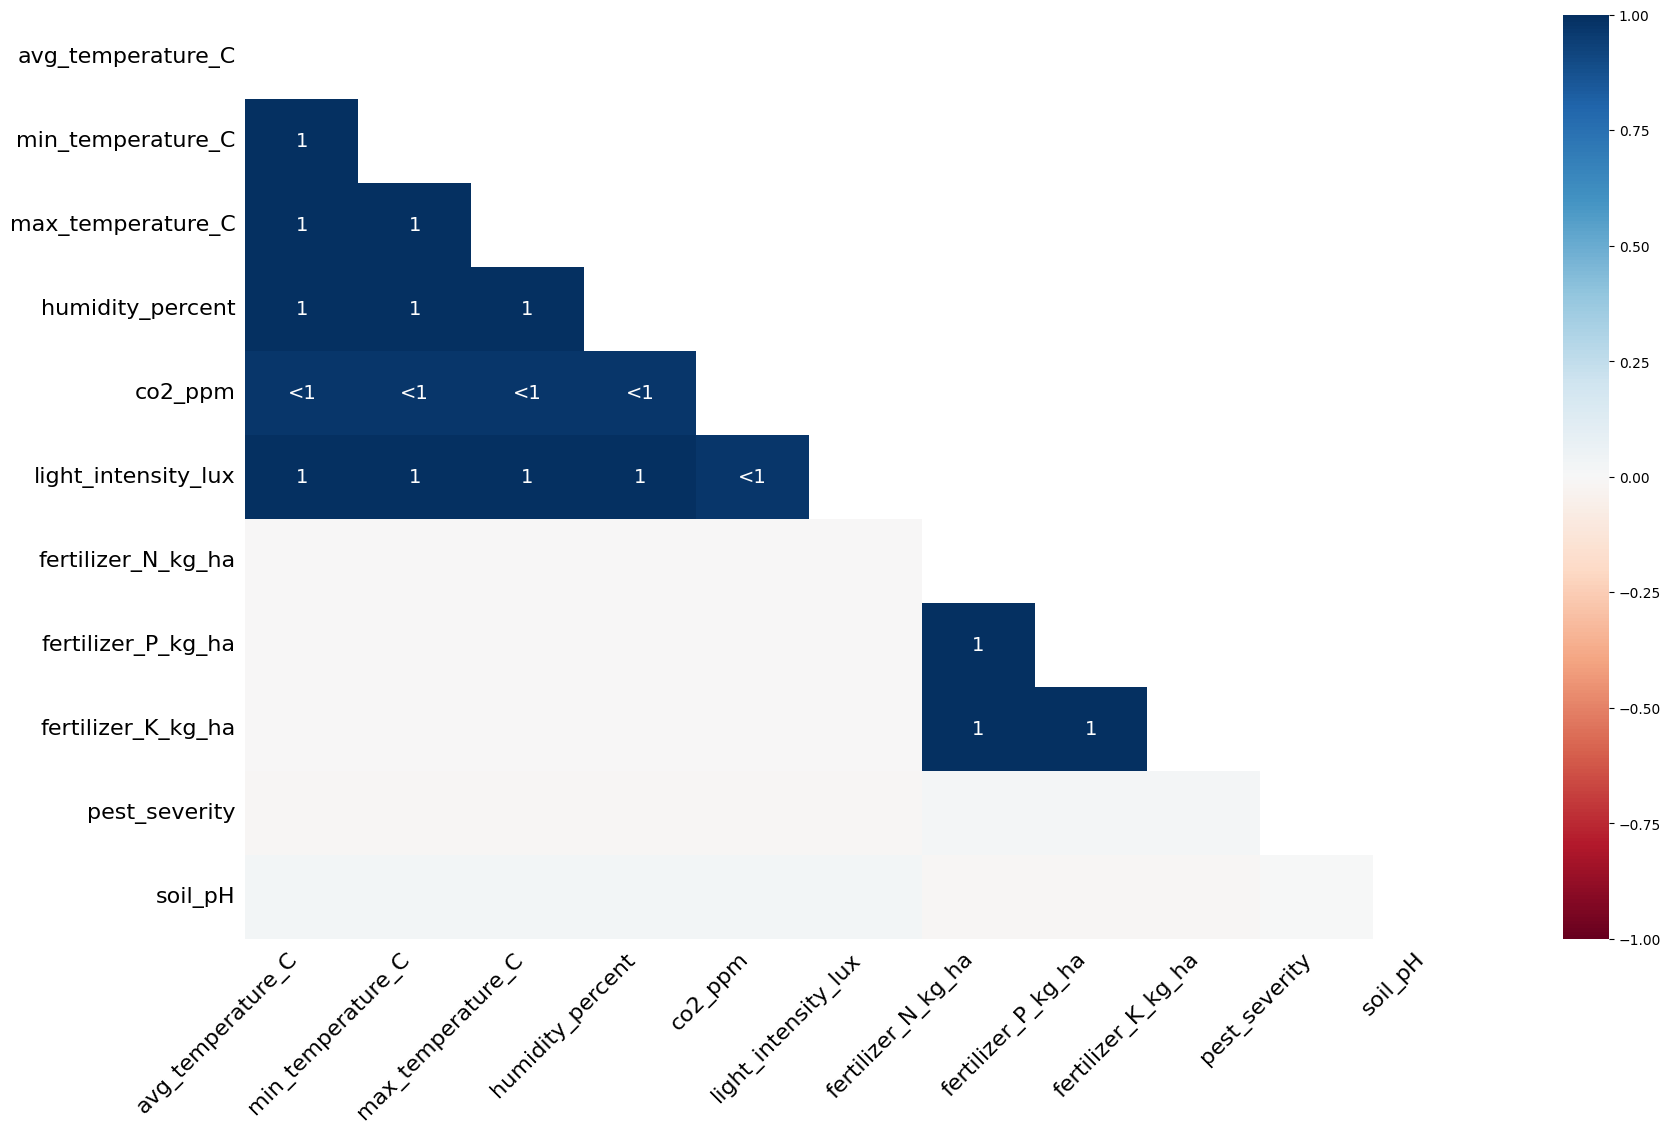

In [27]:
msno.heatmap(train_set)

In [28]:
""" 
- Kelompok 1 — Korelasi sempurna (nilai = 1):
avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux → semuanya bernilai 1 satu sama lain
Artinya: jika satu kolom ini missing, maka keempat kolom lainnya pasti juga missing di baris yang sama — kemungkinan besar karena satu sumber sensor yang sama mati/tidak mencatat

- Kelompok 2 — Korelasi hampir sempurna (nilai = <1):
co2_ppm terhadap kelompok suhu → bernilai <1 (sedikit di bawah sempurna)
Artinya: co2_ppm sebagian besar missing bersamaan dengan kelompok suhu, tapi ada beberapa baris tambahan yang hanya co2_ppm yang missing

- Kelompok 3 — Korelasi sempurna (nilai = 1):
fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha → nilai 1 satu sama lain
Artinya: data pupuk selalu hilang secara bersamaan 

- Kolom tanpa korelasi (area abu-abu):
pest_severity dan soil_pH tidak memiliki korelasi missing dengan kolom lain

Kesimpulan utama: Ada 3 kelompok missing yang berpola (temperature group, fertilizer group, dan co2 yang semi-terkait), dan 2 kolom yang missing secara acak (pest_severity, soil_pH). Ini penting untuk menentukan strategi imputasi — kelompok yang berkorelasi bisa diimputasi secara bersama-sama.
"""

' \n- Kelompok 1 — Korelasi sempurna (nilai = 1):\navg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux → semuanya bernilai 1 satu sama lain\nArtinya: jika satu kolom ini missing, maka keempat kolom lainnya pasti juga missing di baris yang sama — kemungkinan besar karena satu sumber sensor yang sama mati/tidak mencatat\n\n- Kelompok 2 — Korelasi hampir sempurna (nilai = <1):\nco2_ppm terhadap kelompok suhu → bernilai <1 (sedikit di bawah sempurna)\nArtinya: co2_ppm sebagian besar missing bersamaan dengan kelompok suhu, tapi ada beberapa baris tambahan yang hanya co2_ppm yang missing\n\n- Kelompok 3 — Korelasi sempurna (nilai = 1):\nfertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha → nilai 1 satu sama lain\nArtinya: data pupuk selalu hilang secara bersamaan \n\n- Kolom tanpa korelasi (area abu-abu):\npest_severity dan soil_pH tidak memiliki korelasi missing dengan kolom lain\n\nKesimpulan utama: Ada 3 kelompok missing yang berpola (temp

In [29]:
""" 
Bisa disimpulkan bahwa kolom yang terdeteksi missing values memiliki KEMUNGKINAN seperti berikut:
- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm -> MAR
- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR 
- pest_severity, soil_pH -> MCAR

∴ Perlu dilakukan test statistik lebih lanjut seperti:
- MCAR -> Little's MCAR
- MAR -> 
"""

" \nBisa disimpulkan bahwa kolom yang terdeteksi missing values memiliki KEMUNGKINAN seperti berikut:\n- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm -> MAR\n- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR \n- pest_severity, soil_pH -> MCAR\n\n∴ Perlu dilakukan test statistik lebih lanjut seperti:\n- MCAR -> Little's MCAR\n- MAR -> \n"

In [30]:
# Uji Statistik untuk missing values

cols_test = df[['pest_severity', 'soil_pH']]

mt = MCARTest(method='little')

p_value = mt.little_mcar_test(cols_test)

alpha = 0.05 

print(f"P-value: {p_value}")

if p_value > alpha:
    print('Fail to reject the null hypothesis: The missing data is likely MCAR')
else:
    print('Reject the null hypothesis: The missing data is NOT MCAR (it may be MAR or MNAR)')

P-value: 0.7006077443995312
Fail to reject the null hypothesis: The missing data is likely MCAR


In [31]:
# Uji Statistik untuk missing values

cols_test = df[['avg_temperature_C', 'min_temperature_C', 'max_temperature_C', 'humidity_percent', 'light_intensity_lux', 'co2_ppm']]
mt = MCARTest(method='little')

p_value = mt.little_mcar_test(cols_test)

alpha = 0.05 

print(f"P-value: {p_value}")

if p_value > alpha:
    print('Fail to reject the null hypothesis: The missing data is likely MCAR')
else:
    print('Reject the null hypothesis: The missing data is NOT MCAR (it may be MAR or MNAR)')

P-value: 0.42161704879491424
Fail to reject the null hypothesis: The missing data is likely MCAR


In [32]:
# Uji Statistik untuk missing values

cols_test = df[['fertilizer_N_kg_ha', 'fertilizer_P_kg_ha', 'fertilizer_K_kg_ha']]

mt = MCARTest(method='little')

p_value = mt.little_mcar_test(cols_test)

alpha = 0.05 

print(f"P-value: {p_value}")

if p_value > alpha:
    print('Fail to reject the null hypothesis: The missing data is likely MCAR')
else:
    print('Reject the null hypothesis: The missing data is NOT MCAR (it may be MAR or MNAR)')

P-value: nan
Reject the null hypothesis: The missing data is NOT MCAR (it may be MAR or MNAR)


In [33]:
""" 
Kenapa P-value = NaN
Little's MCAR test membutuhkan variasi antar pola missing untuk bisa menghitung statistiknya. Karena dari heatmap missingno kita sudah tahu bahwa fertilizer_N, fertilizer_P, fertilizer_K missing-nya sempurna bersamaan (korelasi = 1), artinya:
- Setiap baris yang missing, ketiganya missing sekaligus
- Setiap baris yang tidak missing, ketiganya ada sekaligus
∴ Hanya ada 2 pola missing (semua ada vs semua hilang), tidak ada variasi pola antar kolom. Little's MCAR test tidak bisa menghitung dengan kondisi seperti ini → hasilnya nan.

Implikasinya
Karena p-value = nan, maka hasil Reject the null hypothesis yang muncul itu tidak bisa dipercaya — itu hanya efek dari kondisi nan > 0.05 yang dievaluasi sebagai False oleh Python.
"""

" \nKenapa P-value = NaN\nLittle's MCAR test membutuhkan variasi antar pola missing untuk bisa menghitung statistiknya. Karena dari heatmap missingno kita sudah tahu bahwa fertilizer_N, fertilizer_P, fertilizer_K missing-nya sempurna bersamaan (korelasi = 1), artinya:\n- Setiap baris yang missing, ketiganya missing sekaligus\n- Setiap baris yang tidak missing, ketiganya ada sekaligus\n∴ Hanya ada 2 pola missing (semua ada vs semua hilang), tidak ada variasi pola antar kolom. Little's MCAR test tidak bisa menghitung dengan kondisi seperti ini → hasilnya nan.\n\nImplikasinya\nKarena p-value = nan, maka hasil Reject the null hypothesis yang muncul itu tidak bisa dipercaya — itu hanya efek dari kondisi nan > 0.05 yang dievaluasi sebagai False oleh Python.\n"

In [34]:
""" 
Bisa disimpulkan dari hasil statistik bahwa kolom yang terdeteksi missing values memiliki KEMUNGKINAN seperti berikut:
- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm -> MCAR
- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR or MNAR
- pest_severity, soil_pH -> MCAR

Tetapi jika dilihat dari visualisasi missing value, kolom yang terdeteksi missing value memiliki KEMUNGKINAN seperti berikut:
- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux -> MAR
- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR
- co2_ppm -> MCAR / MAR
- pest_severity, soil_pH -> MCAR (sesuai dari hasil uji statistik)

Cara handle missing values mungkin di sesuaikan dengan dari hasil visualisasi
"""

' \nBisa disimpulkan dari hasil statistik bahwa kolom yang terdeteksi missing values memiliki KEMUNGKINAN seperti berikut:\n- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm -> MCAR\n- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR or MNAR\n- pest_severity, soil_pH -> MCAR\n\nTetapi jika dilihat dari visualisasi missing value, kolom yang terdeteksi missing value memiliki KEMUNGKINAN seperti berikut:\n- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux -> MAR\n- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR\n- co2_ppm -> MCAR / MAR\n- pest_severity, soil_pH -> MCAR (sesuai dari hasil uji statistik)\n\nCara handle missing values mungkin di sesuaikan dengan dari hasil visualisasi\n'

#### Outliers

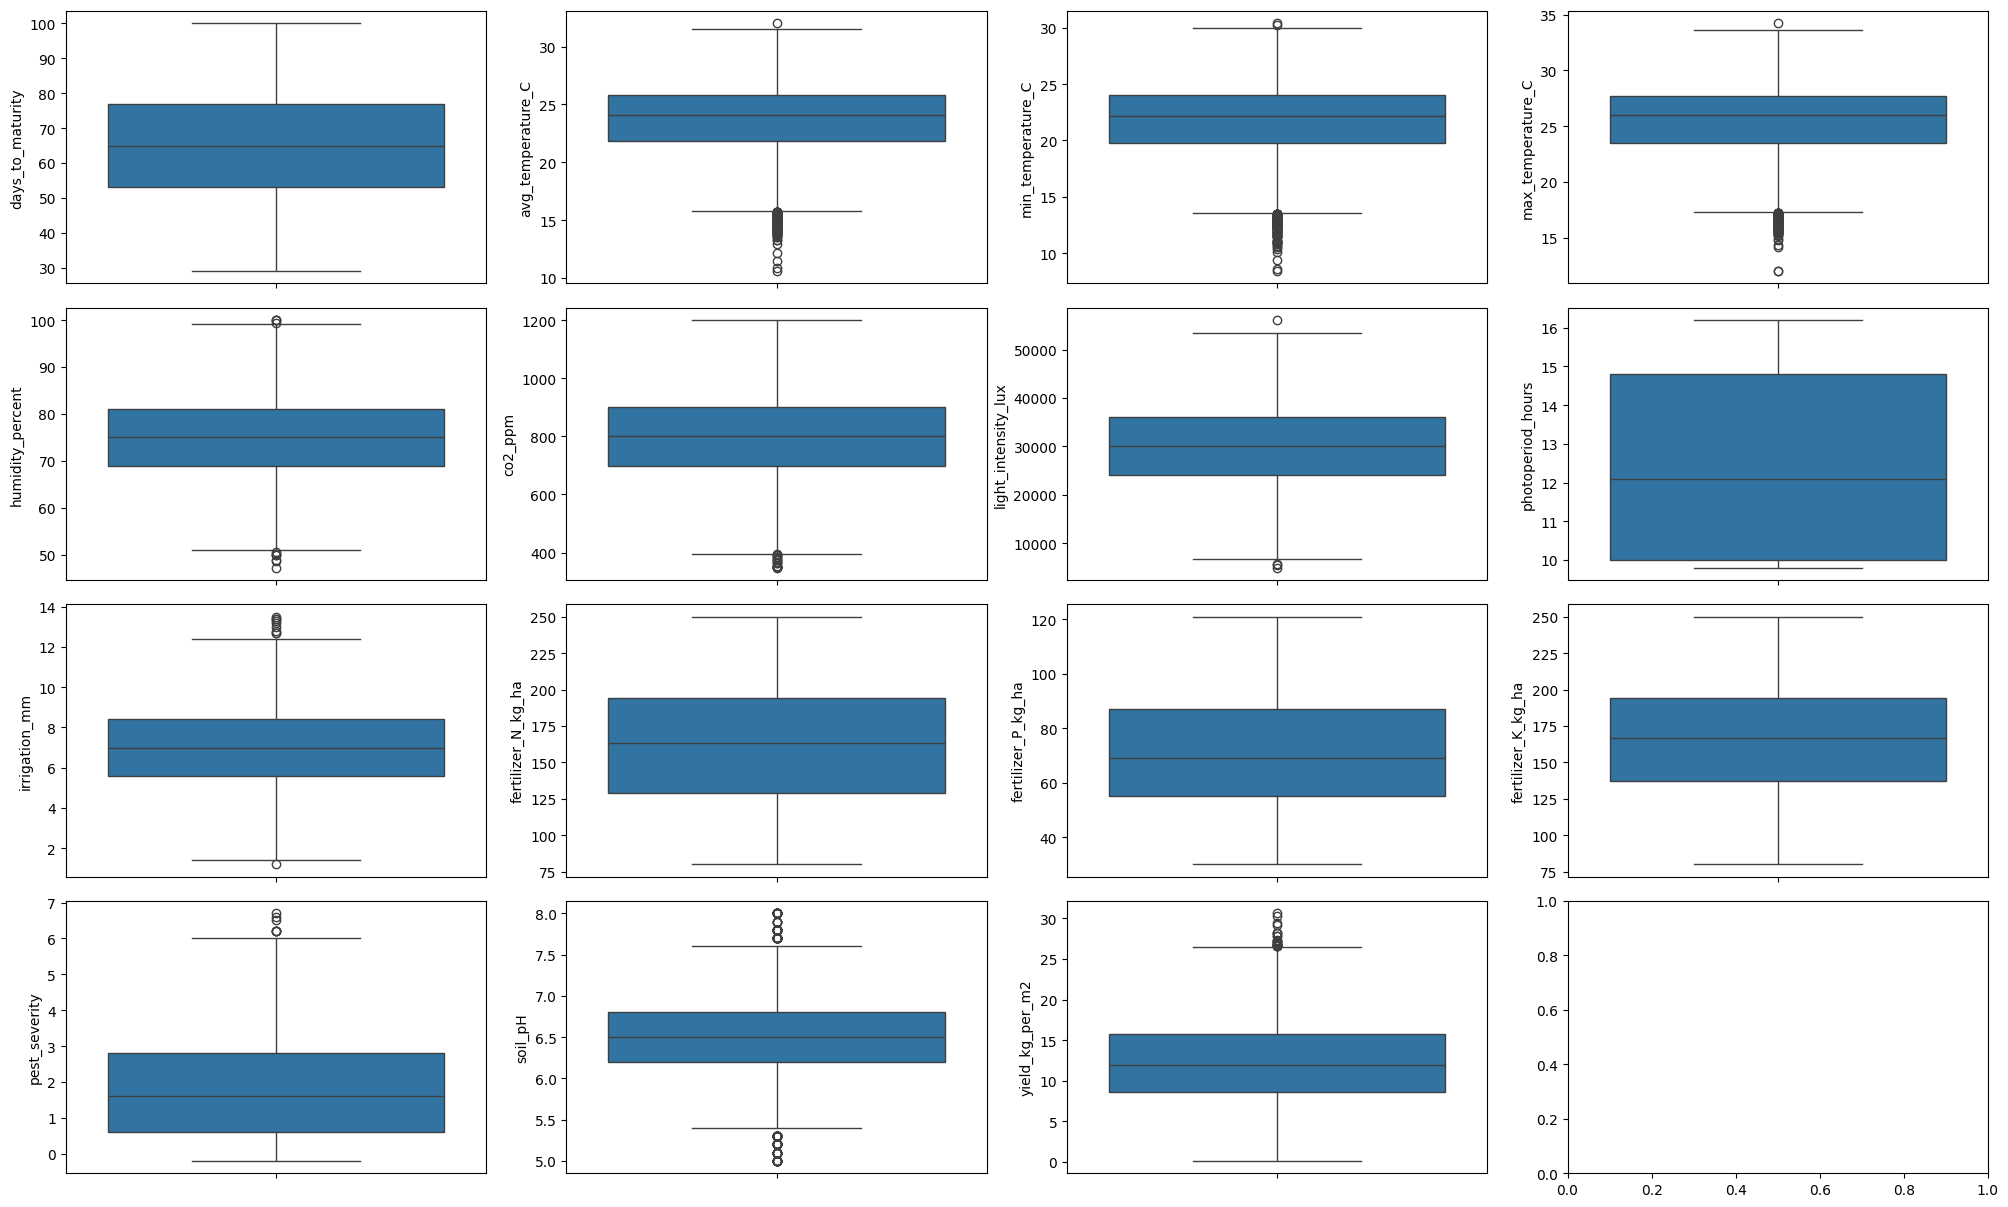

In [35]:
def vis_outliers(data):
    fig, axs = plt.subplots(ncols=4, nrows=4, figsize=(20,12))
    axs = axs.flatten()

    for i, column in enumerate(data):
        sns.boxplot(y=data[column], data=data, ax=axs[i], whis=1.5)

    plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
    plt.show()

vis_outliers(train_set[num_data])

In [36]:
""" 
Ada Outlier (titik bulat di luar whisker)
- avg_temperature_C — outlier di bawah (~12°C) & atas (~32°C), beberapa titik ekstrem di kedua sisi
- min_temperature_C — outlier di bawah (~8-9°C) & atas (~29°C), outlier sisi bawah lebih banyak
- max_temperature_C — outlier di bawah (~15°C) & atas (~34°C), beberapa titik di kedua sisi
- humidity_percent — outlier di bawah (~48%), sedikit titik ekstrem rendah
- co2_ppm — outlier di bawah (~350-400 ppm), beberapa titik sangat rendah
- light_intensity_lux — outlier di bawah (~7.000) & atas (~54.000), outlier di kedua sisi
- irrigation_mm — outlier di atas (~13 mm), beberapa titik tinggi
- pest_severity — outlier di atas (~6-7), beberapa titik serangan hama ekstrem tinggi
- soil_pH — outlier di bawah (~5.0) & atas (~7.8-8.0), sedikit titik di kedua sisi
- yield_kg_per_m2 — outlier di atas (~26-30 kg/m²), beberapa titik hasil panen sangat tinggi
"""

' \nAda Outlier (titik bulat di luar whisker)\n- avg_temperature_C — outlier di bawah (~12°C) & atas (~32°C), beberapa titik ekstrem di kedua sisi\n- min_temperature_C — outlier di bawah (~8-9°C) & atas (~29°C), outlier sisi bawah lebih banyak\n- max_temperature_C — outlier di bawah (~15°C) & atas (~34°C), beberapa titik di kedua sisi\n- humidity_percent — outlier di bawah (~48%), sedikit titik ekstrem rendah\n- co2_ppm — outlier di bawah (~350-400 ppm), beberapa titik sangat rendah\n- light_intensity_lux — outlier di bawah (~7.000) & atas (~54.000), outlier di kedua sisi\n- irrigation_mm — outlier di atas (~13 mm), beberapa titik tinggi\n- pest_severity — outlier di atas (~6-7), beberapa titik serangan hama ekstrem tinggi\n- soil_pH — outlier di bawah (~5.0) & atas (~7.8-8.0), sedikit titik di kedua sisi\n- yield_kg_per_m2 — outlier di atas (~26-30 kg/m²), beberapa titik hasil panen sangat tinggi\n'

### Categorical

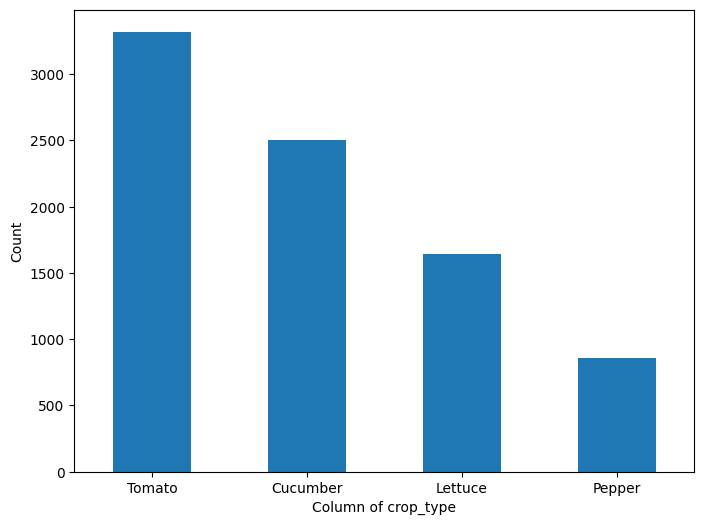

In [37]:
def uni_cat(column_name, xticks=360):
    cat_count = train_set[column_name].value_counts()

    plt.figure(figsize=(8, 6))
    cat_count.plot(kind='bar')

    plt.xlabel(f'Column of {column_name}')
    plt.ylabel('Count')
    plt.xticks(rotation=xticks)
    plt.show

uni_cat('crop_type')

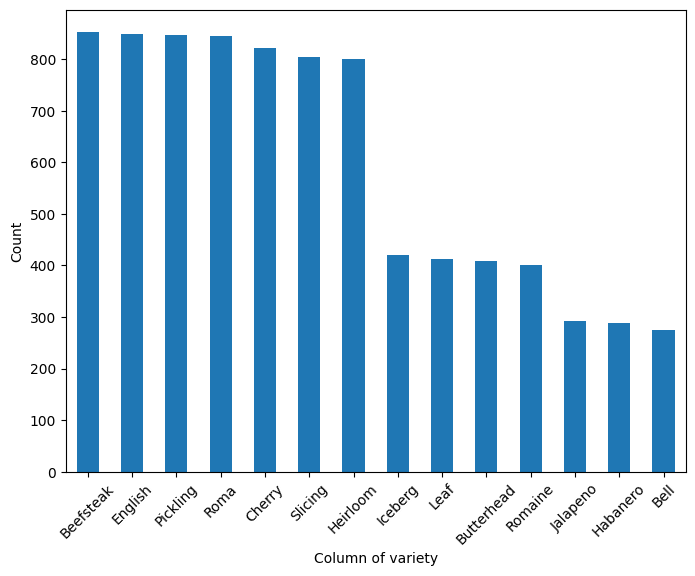

In [38]:
uni_cat('variety', 45)

## Bivariate EDA

### Numerical vs Numerical

In [39]:
train_set.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
561,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,11.9,7.7,167.0,92.0,175.0,1.6,5.9,12.42
1162,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,15.2,4.6,228.0,98.0,208.0,4.0,6.2,20.27
9573,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,11.5,3.8,124.0,37.0,146.0,0.5,6.2,11.51
9045,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,10.6,6.9,168.0,83.0,221.0,2.6,7.1,13.24
3209,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,31260.0,14.3,8.5,NaN,NaN,NaN,2.9,5.8,9.56


In [40]:
train_set['avg_temperature_C'] == (train_set['min_temperature_C'] + train_set['max_temperature_C']) / 2


561      False
1162     False
9573     False
9045     False
3209     False
1527      True
6653     False
9861     False
58       False
2191     False
8312     False
2737     False
6571     False
2464     False
3991     False
4484     False
5662     False
4716     False
414      False
9877     False
8043     False
2982     False
7337     False
5609     False
9894     False
5736     False
6906     False
4983     False
1897     False
6973     False
7341     False
9394      True
7602      True
10034    False
1817     False
1937     False
4972     False
2072     False
1726     False
1047     False
9562     False
3946     False
8694     False
766      False
1144     False
8026     False
2425     False
4607     False
5794     False
8365     False
3047     False
8823     False
8396     False
2673      True
828      False
7078     False
1672     False
3034     False
6264     False
7872     False
2357     False
8292     False
7523     False
2045     False
10217    False
9627     False
2813     F

In [41]:
mask = train_set['avg_temperature_C'] == (train_set['min_temperature_C'] + train_set['max_temperature_C']) / 2
mask.sum()

396

In [42]:
#train_set['days_to_maturity'] == (train_set['harvest_date'] - train_set['planting_date']).dt.days

<Figure size 800x600 with 0 Axes>

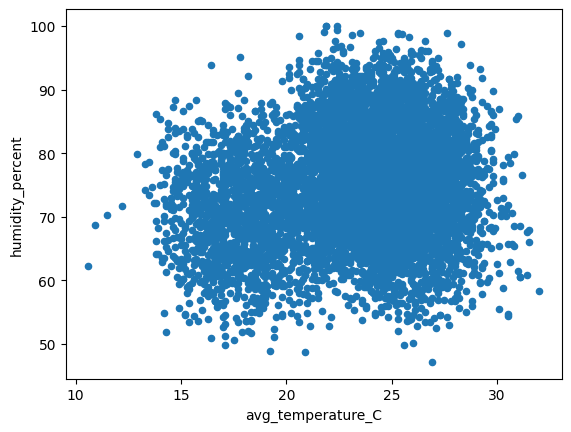

In [43]:
def plot_num_num(col_1, col_2):
    plt.figure(figsize=(8, 6))
    train_set.plot(kind='scatter', x=col_1, y=col_2)
    plt.show()

plot_num_num('avg_temperature_C', 'humidity_percent')

<Figure size 800x600 with 0 Axes>

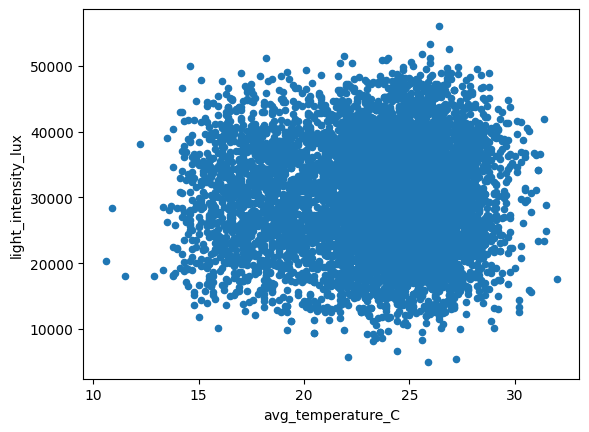

In [44]:
plot_num_num('avg_temperature_C', 'light_intensity_lux')

<Figure size 800x600 with 0 Axes>

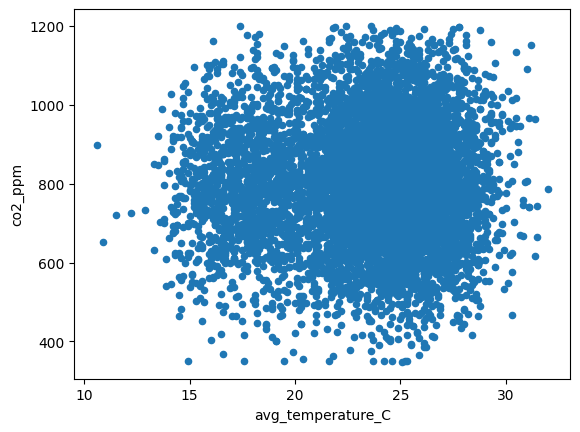

In [45]:
plot_num_num('avg_temperature_C', 'co2_ppm')

<Figure size 800x600 with 0 Axes>

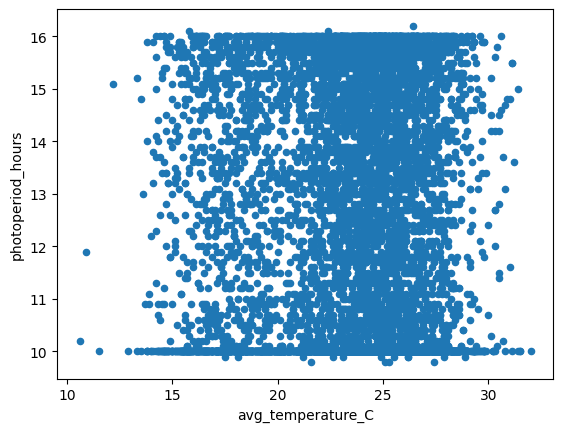

In [46]:
plot_num_num('avg_temperature_C', 'photoperiod_hours')

<Figure size 800x600 with 0 Axes>

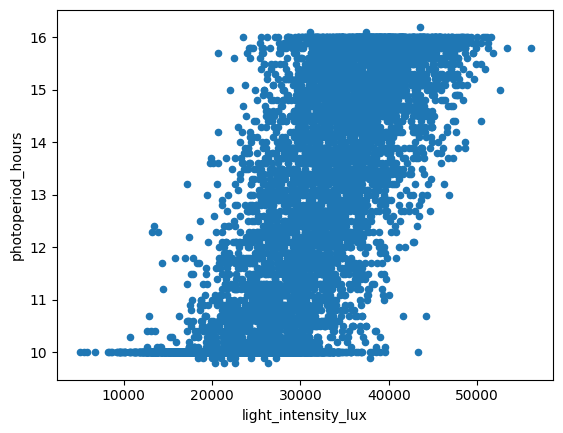

In [47]:
plot_num_num('light_intensity_lux', 'photoperiod_hours')

<Figure size 800x600 with 0 Axes>

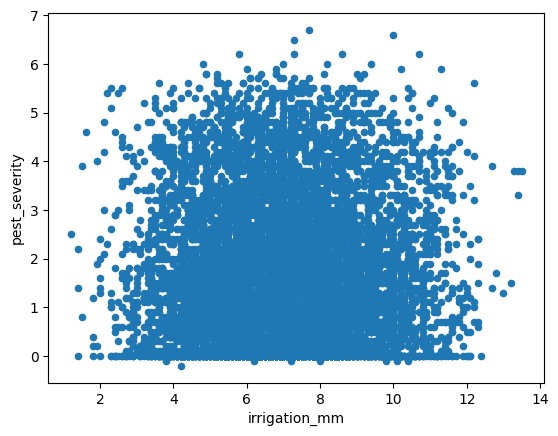

In [48]:
plot_num_num('irrigation_mm', 'pest_severity')

<Figure size 800x600 with 0 Axes>

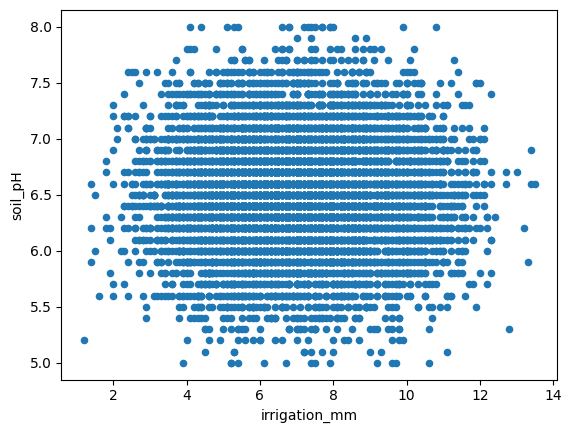

In [49]:
plot_num_num('irrigation_mm', 'soil_pH')

<Figure size 800x600 with 0 Axes>

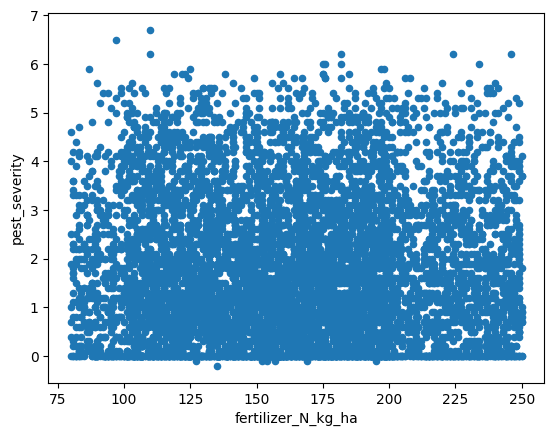

In [50]:
plot_num_num('fertilizer_N_kg_ha', 'pest_severity')

<Figure size 800x600 with 0 Axes>

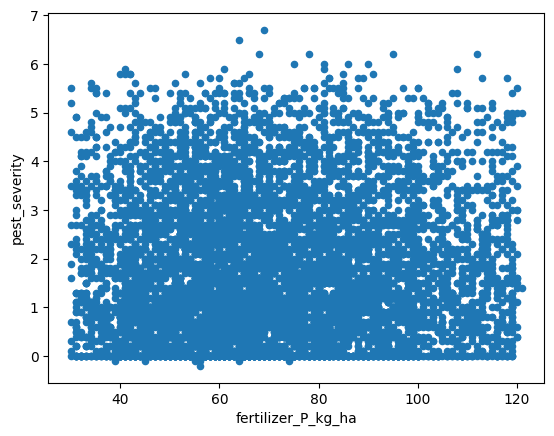

In [51]:
plot_num_num('fertilizer_P_kg_ha', 'pest_severity')

<Figure size 800x600 with 0 Axes>

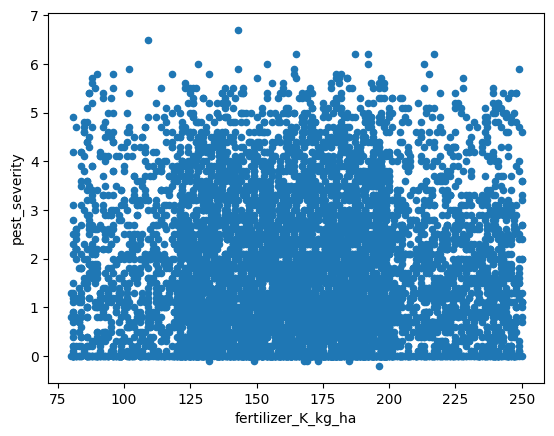

In [52]:
plot_num_num('fertilizer_K_kg_ha', 'pest_severity')

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5]),
 [Text(0.5, 0, 'days_to_maturity'),
  Text(1.5, 0, 'avg_temperature_C'),
  Text(2.5, 0, 'min_temperature_C'),
  Text(3.5, 0, 'max_temperature_C'),
  Text(4.5, 0, 'humidity_percent'),
  Text(5.5, 0, 'co2_ppm'),
  Text(6.5, 0, 'light_intensity_lux'),
  Text(7.5, 0, 'photoperiod_hours'),
  Text(8.5, 0, 'irrigation_mm'),
  Text(9.5, 0, 'fertilizer_N_kg_ha'),
  Text(10.5, 0, 'fertilizer_P_kg_ha'),
  Text(11.5, 0, 'fertilizer_K_kg_ha'),
  Text(12.5, 0, 'pest_severity'),
  Text(13.5, 0, 'soil_pH'),
  Text(14.5, 0, 'yield_kg_per_m2')])

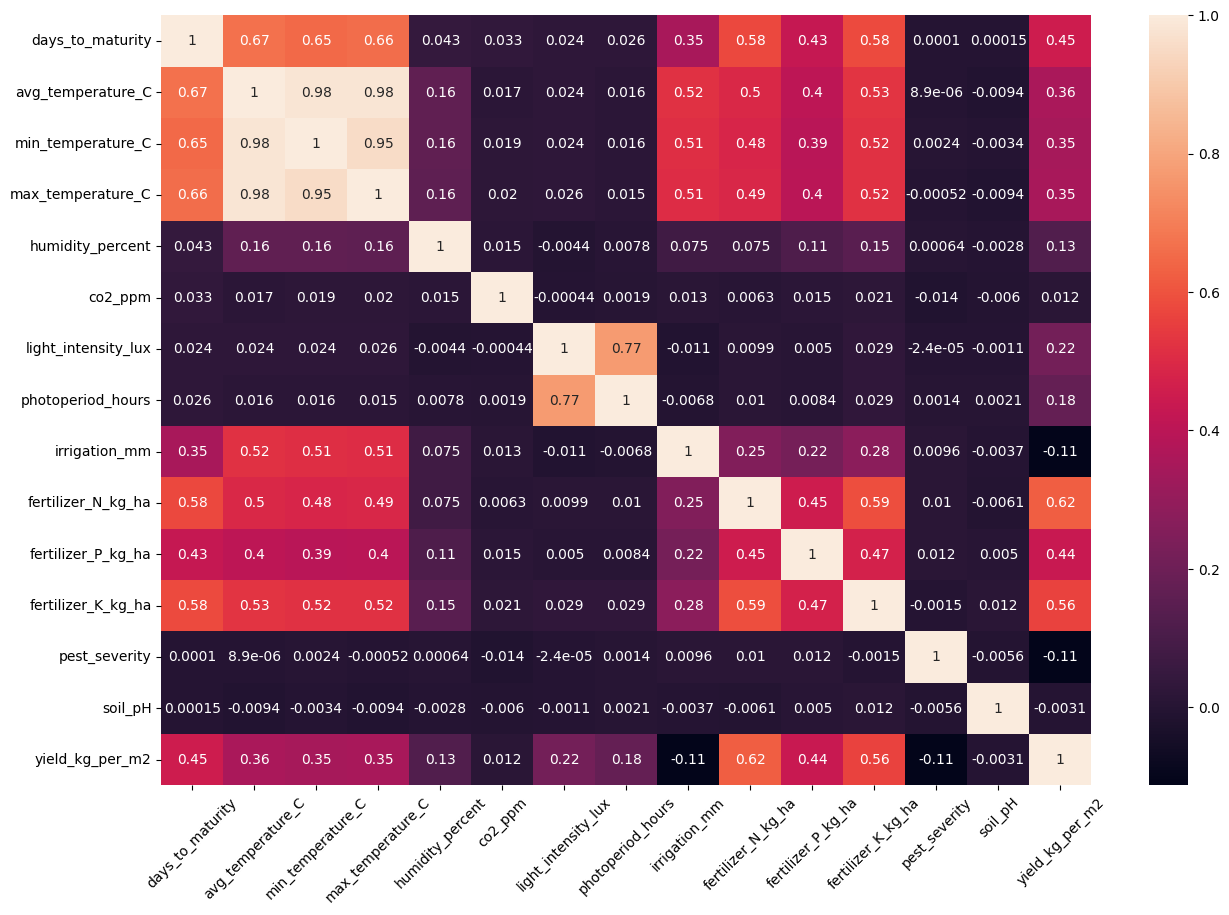

In [53]:
plt.figure(figsize=(15,10))
sns.heatmap(train_set[num_data].corr(), annot=True)
plt.xticks(rotation=45)

In [54]:
train_set[num_data].corr()

,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
days_to_maturity,1.000000,0.666564,0.651644,0.657517,0.042885,0.033392,0.024382,0.026300,0.349927,0.575114,0.427514,0.582247,0.000101,0.000147,0.452379
avg_temperature_C,0.666564,1.000000,0.981035,0.981536,0.162751,0.017189,0.024345,0.015882,0.519726,0.495055,0.404852,0.528478,0.000009,-0.009438,0.355478
min_temperature_C,0.651644,0.981035,1.000000,0.952390,0.162230,0.018541,0.023593,0.015989,0.510022,0.484331,0.393591,0.518255,0.002401,-0.003362,0.346032
max_temperature_C,0.657517,0.981536,0.952390,1.000000,0.158940,0.019714,0.026255,0.015129,0.508397,0.487586,0.398869,0.518157,-0.000516,-0.009359,0.351274
humidity_percent,0.042885,0.162751,0.162230,0.158940,1.000000,0.014717,-0.004446,0.007787,0.074618,0.074518,0.114446,0.145132,0.000641,-0.002771,0.125726
co2_ppm,0.033392,0.017189,0.018541,0.019714,0.014717,1.000000,-0.000444,0.001912,0.012915,0.006322,0.014618,0.021496,-0.013726,-0.005958,0.011754
light_intensity_lux,0.024382,0.024345,0.023593,0.026255,-0.004446,-0.000444,1.000000,0.772916,-0.011325,0.009876,0.005001,0.028626,-0.000024,-0.001084,0.215014
photoperiod_hours,0.026300,0.015882,0.015989,0.015129,0.007787,0.001912,0.772916,1.000000,-0.006766,0.010431,0.008425,0.029489,0.001426,0.002129,0.176921
irrigation_mm,0.349927,0.519726,0.510022,0.508397,0.074618,0.012915,-0.011325,-0.006766,1.000000,0.252351,0.219141,0.277570,0.009552,-0.003667,-0.112566
fertilizer_N_kg_ha,0.575114,0.495055,0.484331,0.487586,0.074518,0.006322,0.009876,0.010431,0.252351,1.000000,0.449382,0.590022,0.010223,-0.006117,0.622266


In [55]:
""" 
Analisis Korelasi Heatmap
1. Korelasi terhadap Target (yield_kg_per_m2)
Korelasi Positif:
- fertilizer_N_kg_ha → 0.62 — korelasi positif paling kuat, pupuk nitrogen sangat berpengaruh terhadap hasil panen
- fertilizer_K_kg_ha → 0.56 — korelasi positif kuat kedua
- days_to_maturity → 0.45 — semakin lama masa matang, hasil panen cenderung lebih tinggi
- fertilizer_P_kg_ha → 0.44 — korelasi positif sedang
- avg/min/max_temperature_C → 0.35–0.36 — suhu berpengaruh positif sedang
- light_intensity_lux → 0.22 — pengaruh cahaya cukup lemah
- photoperiod_hours → 0.18 — pengaruh durasi cahaya lemah
- humidity_percent → 0.13 — pengaruh sangat lemah

Korelasi Negatif:
- irrigation_mm → -0.11 — sedikit negatif, irigasi berlebih justru sedikit menurunkan yield
- pest_severity → -0.11 — serangan hama menurunkan hasil panen
- greenhouse_id → -0.03 — hampir tidak ada korelasi
- co2_ppm, soil_pH → mendekati 0 — hampir tidak berkorelasi dengan yield

2. Korelasi Tinggi Antar Fitur (Multikolinearitas)
Sangat Tinggi (>0.9):
- avg_temperature_C vs min_temperature_C → 0.98
- avg_temperature_C vs max_temperature_C → 0.98
- min_temperature_C vs max_temperature_C → 0.95
∴ Ketiga kolom suhu hampir mengukur hal yang sama — berpotensi multikolinear, salah satunya bisa dipertimbangkan untuk di-drop.

Tinggi (0.5-0.8):
- light_intensity_lux vs photoperiod_hours → 0.77
- days_to_maturity vs avg/min/max_temperature_C → 0.65-0.67
- fertilizer_N_kg_ha vs fertilizer_K_kg_ha → 0.59
- days_to_maturity vs fertilizer_N/K_kg_ha → 0.57-0.58
- avg_temperature_C vs fertilizer_K_kg_ha → 0.53
- avg_temperature_C vs irrigation_mm → 0.52

3. Korelasi Sangat Lemah / Tidak Berkorelasi
greenhouse_id, co2_ppm, soil_pH, pest_severity → hampir tidak berkorelasi dengan kolom manapun (nilai mendekati 0 di semua pasangan)

Kesimpulan Utama
∴ Fitur yang paling berpengaruh terhadap yield_kg_per_m2 adalah fertilizer (N, K, P) dan days_to_maturity. Terdapat multikolinearitas tinggi pada kelompok suhu (avg, min, max) yang perlu diperhatikan saat pemodelan.
"""

' \nAnalisis Korelasi Heatmap\n1. Korelasi terhadap Target (yield_kg_per_m2)\nKorelasi Positif:\n- fertilizer_N_kg_ha → 0.62 — korelasi positif paling kuat, pupuk nitrogen sangat berpengaruh terhadap hasil panen\n- fertilizer_K_kg_ha → 0.56 — korelasi positif kuat kedua\n- days_to_maturity → 0.45 — semakin lama masa matang, hasil panen cenderung lebih tinggi\n- fertilizer_P_kg_ha → 0.44 — korelasi positif sedang\n- avg/min/max_temperature_C → 0.35–0.36 — suhu berpengaruh positif sedang\n- light_intensity_lux → 0.22 — pengaruh cahaya cukup lemah\n- photoperiod_hours → 0.18 — pengaruh durasi cahaya lemah\n- humidity_percent → 0.13 — pengaruh sangat lemah\n\nKorelasi Negatif:\n- irrigation_mm → -0.11 — sedikit negatif, irigasi berlebih justru sedikit menurunkan yield\n- pest_severity → -0.11 — serangan hama menurunkan hasil panen\n- greenhouse_id → -0.03 — hampir tidak ada korelasi\n- co2_ppm, soil_pH → mendekati 0 — hampir tidak berkorelasi dengan yield\n\n2. Korelasi Tinggi Antar Fitur 

### Numerical vs Categorical

In [56]:
train_set.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8320 entries, 561 to 7270
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        8320 non-null   object 
 1   crop_type            8320 non-null   object 
 2   variety              8320 non-null   object 
 3   days_to_maturity     8320 non-null   float64
 4   avg_temperature_C    7896 non-null   float64
 5   min_temperature_C    7896 non-null   float64
 6   max_temperature_C    7896 non-null   float64
 7   humidity_percent     7896 non-null   float64
 8   co2_ppm              7870 non-null   float64
 9   light_intensity_lux  7896 non-null   float64
 10  photoperiod_hours    8320 non-null   float64
 11  irrigation_mm        8320 non-null   float64
 12  fertilizer_N_kg_ha   7469 non-null   float64
 13  fertilizer_P_kg_ha   7469 non-null   float64
 14  fertilizer_K_kg_ha   7469 non-null   float64
 15  pest_severity        8221 non-null   floa

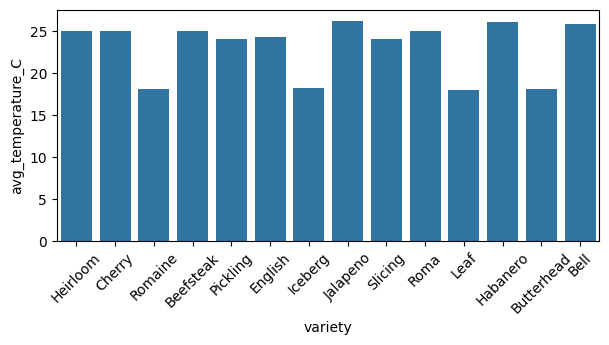

In [57]:
def num_cat(col_1, col_2):
    plt.figure(figsize=(7, 3))
    sns.barplot(data=train_set, x=col_1, y=col_2, errorbar=None)
    plt.xticks(rotation=45)
    plt.show()

num_cat('variety', 'avg_temperature_C')

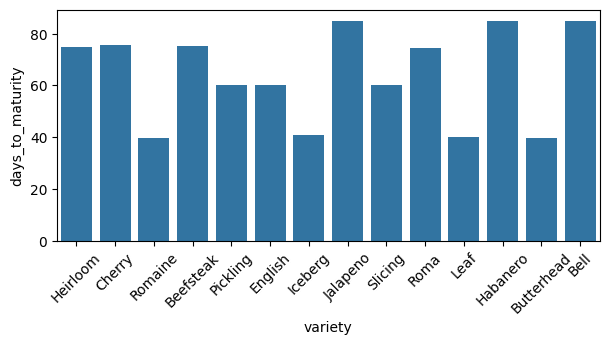

In [58]:
num_cat('variety', 'days_to_maturity')

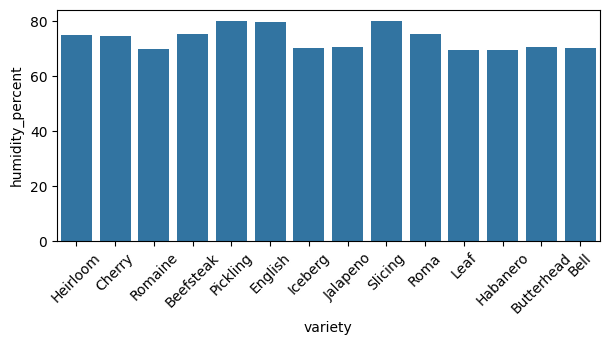

In [59]:
num_cat('variety', 'humidity_percent')

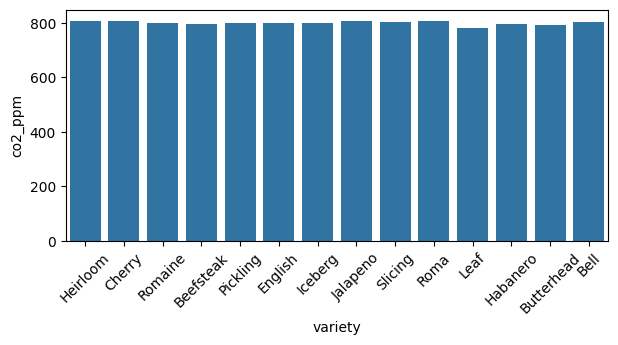

In [60]:
num_cat('variety', 'co2_ppm')

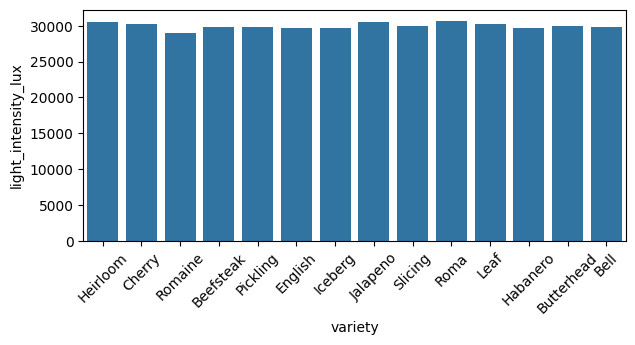

In [61]:
num_cat('variety', 'light_intensity_lux')

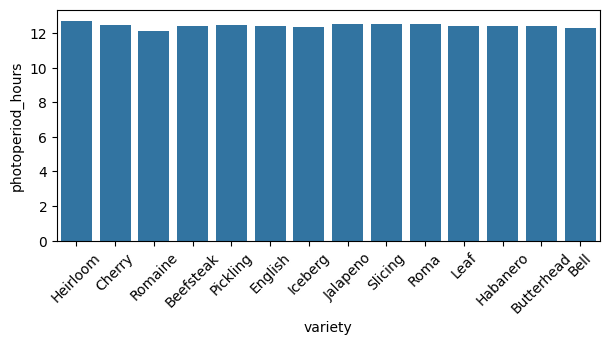

In [62]:
num_cat('variety', 'photoperiod_hours')

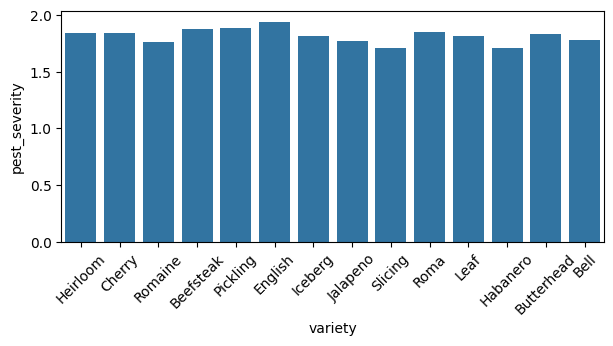

In [63]:
num_cat('variety', 'pest_severity')

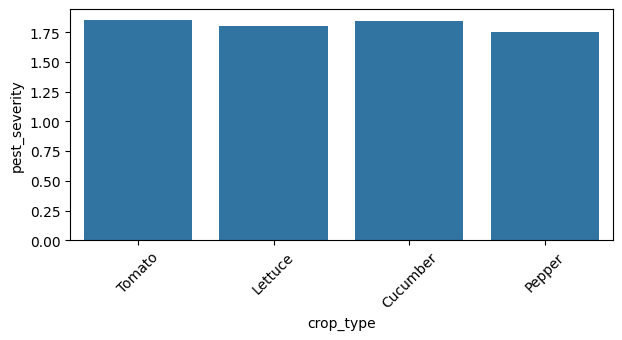

In [64]:
num_cat('crop_type', 'pest_severity')

In [65]:
""" 
Kenapa pest_severity jika dibandingkan dengan crop_type dan variety hanya memiliki angka maksimal 2 padahal secara data nilainya bisa sampai 6, coba kamu cek dengan kolom lain. 

pest_severity itu akan mencapai nilai maksimal jika dibandingkan dengan fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha
"""

' \nKenapa pest_severity jika dibandingkan dengan crop_type dan variety hanya memiliki angka maksimal 2 padahal secara data nilainya bisa sampai 6, coba kamu cek dengan kolom lain. \n\npest_severity itu akan mencapai nilai maksimal jika dibandingkan dengan fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha\n'

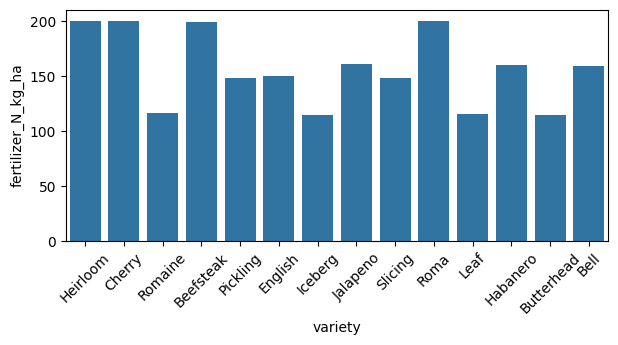

In [66]:
num_cat('variety', 'fertilizer_N_kg_ha')

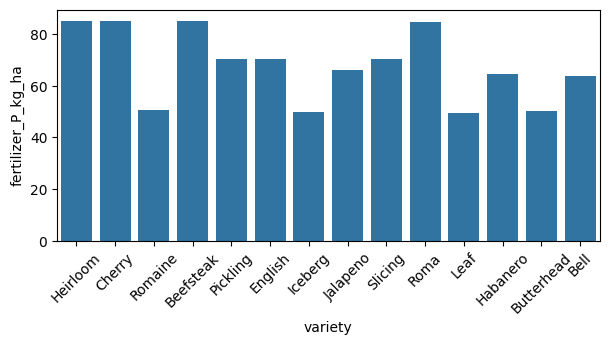

In [67]:
num_cat('variety', 'fertilizer_P_kg_ha')

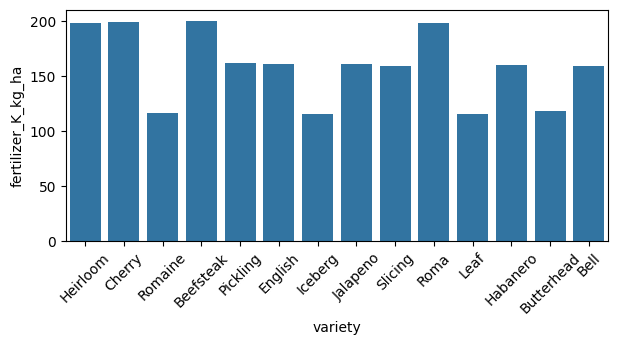

In [68]:
num_cat('variety', 'fertilizer_K_kg_ha')

### Categorical vs Categorical

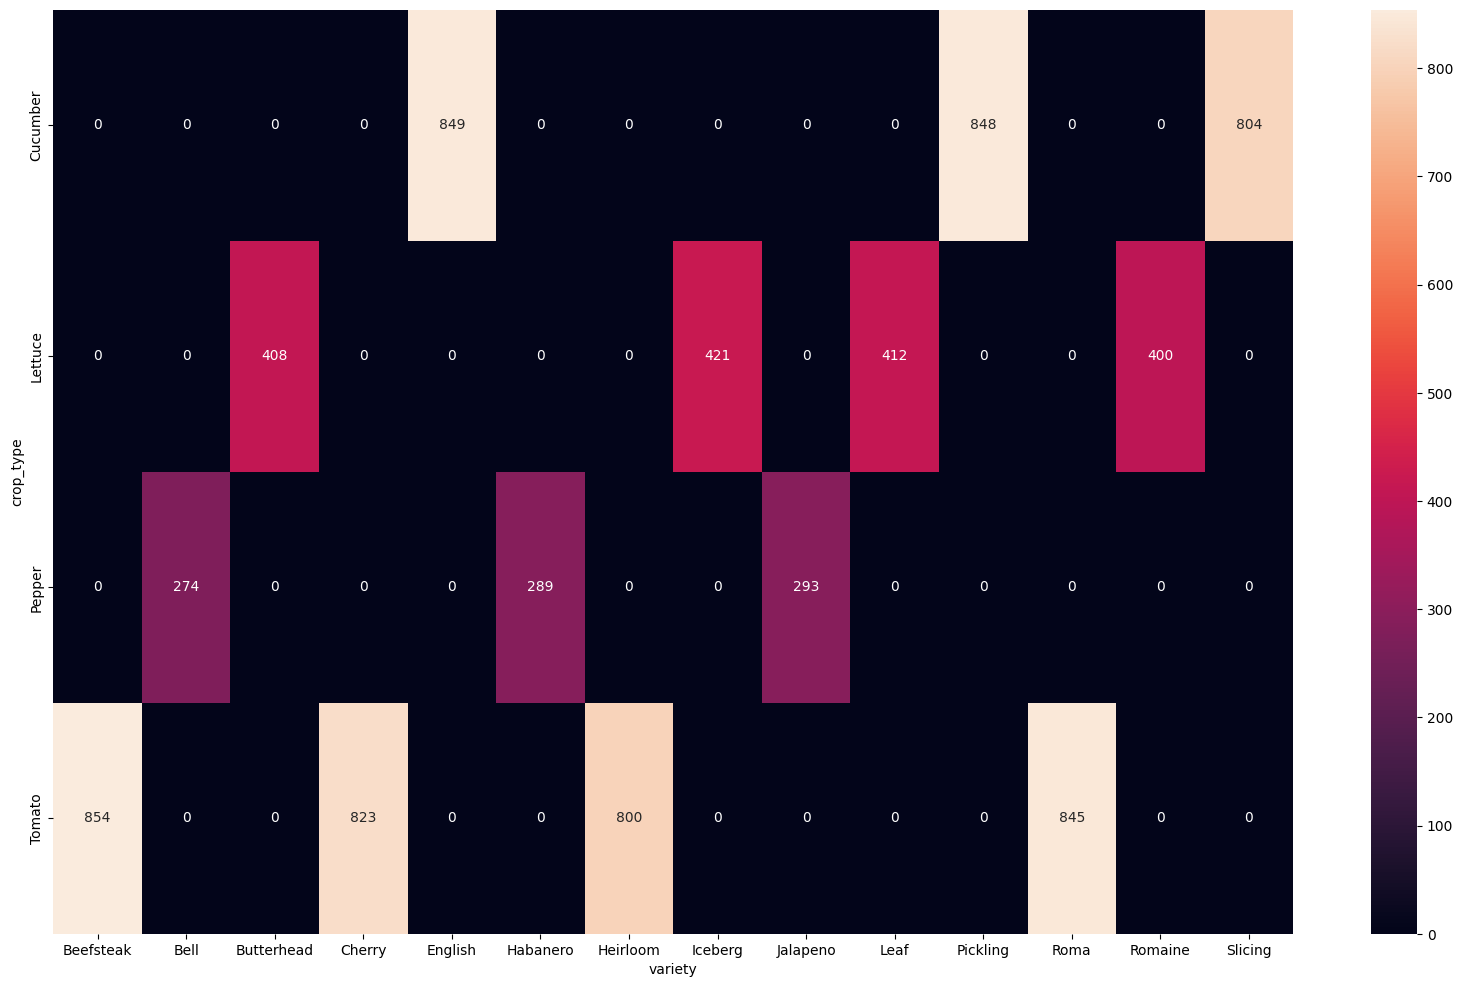

In [69]:
plt.figure(figsize=(20, 12))
ct = pd.crosstab(
    train_set['crop_type'],
    train_set['variety']
)

sns.heatmap(ct, annot=True, fmt='d')
plt.show()

## Multivariate EDA

In [70]:
train_set.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8320 entries, 561 to 7270
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        8320 non-null   object 
 1   crop_type            8320 non-null   object 
 2   variety              8320 non-null   object 
 3   days_to_maturity     8320 non-null   float64
 4   avg_temperature_C    7896 non-null   float64
 5   min_temperature_C    7896 non-null   float64
 6   max_temperature_C    7896 non-null   float64
 7   humidity_percent     7896 non-null   float64
 8   co2_ppm              7870 non-null   float64
 9   light_intensity_lux  7896 non-null   float64
 10  photoperiod_hours    8320 non-null   float64
 11  irrigation_mm        8320 non-null   float64
 12  fertilizer_N_kg_ha   7469 non-null   float64
 13  fertilizer_P_kg_ha   7469 non-null   float64
 14  fertilizer_K_kg_ha   7469 non-null   float64
 15  pest_severity        8221 non-null   floa

In [71]:
fig = px.scatter(train_set, x='days_to_maturity', y='avg_temperature_C', size='photoperiod_hours', color='crop_type')
fig.show()

In [72]:
""" 
- Karena korelasi days_to_maturity vs avg_temperature_C = 0.67, titik-titik cenderung membentuk pola diagonal ke kanan atas — tanaman yang butuh suhu lebih tinggi juga butuh waktu matang lebih lama
- Warna yang berkelompok menunjukkan setiap crop_type memiliki rentang suhu dan masa matang yang berbeda-beda (misalnya Lettuce matang cepat di suhu rendah, Pepper matang lama di suhu tinggi)
- Ukuran titik (photoperiod_hours) tidak menunjukkan pola khusus terhadap kedua sumbu tersebut karena korelasinya sangat lemah (~0.02)
"""

' \n- Karena korelasi days_to_maturity vs avg_temperature_C = 0.67, titik-titik cenderung membentuk pola diagonal ke kanan atas — tanaman yang butuh suhu lebih tinggi juga butuh waktu matang lebih lama\n- Warna yang berkelompok menunjukkan setiap crop_type memiliki rentang suhu dan masa matang yang berbeda-beda (misalnya Lettuce matang cepat di suhu rendah, Pepper matang lama di suhu tinggi)\n- Ukuran titik (photoperiod_hours) tidak menunjukkan pola khusus terhadap kedua sumbu tersebut karena korelasinya sangat lemah (~0.02)\n'

In [73]:
fig = px.scatter_3d(
    train_set,
    x='fertilizer_N_kg_ha',
    y='fertilizer_P_kg_ha',
    z='fertilizer_K_kg_ha',
    color='pest_severity'
)

fig.show()

In [74]:
""" 
- Titik-titik tersebar cukup merata di ruang 3D karena korelasi antar fertilizer hanya 0.45–0.59 (tidak terlalu tinggi)
- Warna pest_severity yang tersebar acak tanpa pola tertentu di seluruh ruang 3D — mengkonfirmasi bahwa korelasi pest_severity dengan ketiga fertilizer mendekati 0 (~0.01)
∴ Jumlah pupuk yang diberikan tidak mempengaruhi tingkat keparahan serangan hama
"""

' \n- Titik-titik tersebar cukup merata di ruang 3D karena korelasi antar fertilizer hanya 0.45–0.59 (tidak terlalu tinggi)\n- Warna pest_severity yang tersebar acak tanpa pola tertentu di seluruh ruang 3D — mengkonfirmasi bahwa korelasi pest_severity dengan ketiga fertilizer mendekati 0 (~0.01)\n∴ Jumlah pupuk yang diberikan tidak mempengaruhi tingkat keparahan serangan hama\n'

In [75]:
fig = px.scatter_3d(
    train_set,
    x='fertilizer_N_kg_ha',
    y='fertilizer_P_kg_ha',
    z='fertilizer_K_kg_ha',
    color='soil_pH'
)

fig.show()

In [76]:
""" 
- Sama seperti visualisasi sebelumnya, warna soil_pH juga tersebar acak tanpa pola tertentu
- Mengkonfirmasi bahwa korelasi soil_pH dengan ketiga fertilizer mendekati 0 (~0.006-0.012)
∴ Pemberian pupuk N, P, K tidak berkaitan dengan tingkat pH tanah di dataset ini
"""

' \n- Sama seperti visualisasi sebelumnya, warna soil_pH juga tersebar acak tanpa pola tertentu\n- Mengkonfirmasi bahwa korelasi soil_pH dengan ketiga fertilizer mendekati 0 (~0.006-0.012)\n∴ Pemberian pupuk N, P, K tidak berkaitan dengan tingkat pH tanah di dataset ini\n'

# Data Cleaning

## Handle Duplicate Data

In [77]:
train_set.duplicated().sum()

127

In [78]:
train_set = train_set.drop_duplicates()

In [79]:
train_set.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
561,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,11.9,7.7,167.0,92.0,175.0,1.6,5.9,12.42
1162,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,15.2,4.6,228.0,98.0,208.0,4.0,6.2,20.27
9573,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,11.5,3.8,124.0,37.0,146.0,0.5,6.2,11.51
9045,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,10.6,6.9,168.0,83.0,221.0,2.6,7.1,13.24
3209,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,31260.0,14.3,8.5,NaN,NaN,NaN,2.9,5.8,9.56


## Handle Missing Values

In [80]:
train_set.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
561,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,11.9,7.7,167.0,92.0,175.0,1.6,5.9,12.42
1162,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,15.2,4.6,228.0,98.0,208.0,4.0,6.2,20.27
9573,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,11.5,3.8,124.0,37.0,146.0,0.5,6.2,11.51
9045,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,10.6,6.9,168.0,83.0,221.0,2.6,7.1,13.24
3209,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,31260.0,14.3,8.5,NaN,NaN,NaN,2.9,5.8,9.56


In [81]:
missing_values = train_set.isnull().sum()
percentage_missing = round((missing_values / len(train_set)) * 100, 3)

missing_data_info = pd.DataFrame({
    'missing_value': missing_values,
    'percentage_missing': percentage_missing
})

missing_data_info

,missing_value,percentage_missing
greenhouse_id,0,0.000
crop_type,0,0.000
variety,0,0.000
days_to_maturity,0,0.000
avg_temperature_C,414,5.053
min_temperature_C,414,5.053
max_temperature_C,414,5.053
humidity_percent,414,5.053
co2_ppm,440,5.370
light_intensity_lux,414,5.053


In [82]:
from scipy.stats import skew

for col in num_data:
    print(col, skew(train_set[col].dropna()))

""" 
| Skewness        | Interpretasi      |
| --------------- | ----------------- |
| -0.5 sampai 0.5 | cukup simetris    |
| 0.5 sampai 1    | moderately skewed |
| > 1             | highly skewed     |

"""

days_to_maturity -0.19366759229317101
avg_temperature_C -0.7274757946782957
min_temperature_C -0.6984667758357636
max_temperature_C -0.6714284652941064
humidity_percent -0.03607302521126921
co2_ppm -0.024043685434641186
light_intensity_lux -0.000931988010109537
photoperiod_hours 0.2593542133178215
irrigation_mm 0.1097503546719141
fertilizer_N_kg_ha 0.11309255825423611
fertilizer_P_kg_ha 0.2716082266137349
fertilizer_K_kg_ha 0.037687020536078586
pest_severity 0.6324577792710302
soil_pH 0.016881207446116115
yield_kg_per_m2 0.39415908331156263


' \n| Skewness        | Interpretasi      |\n| --------------- | ----------------- |\n| -0.5 sampai 0.5 | cukup simetris    |\n| 0.5 sampai 1    | moderately skewed |\n| > 1             | highly skewed     |\n\n'

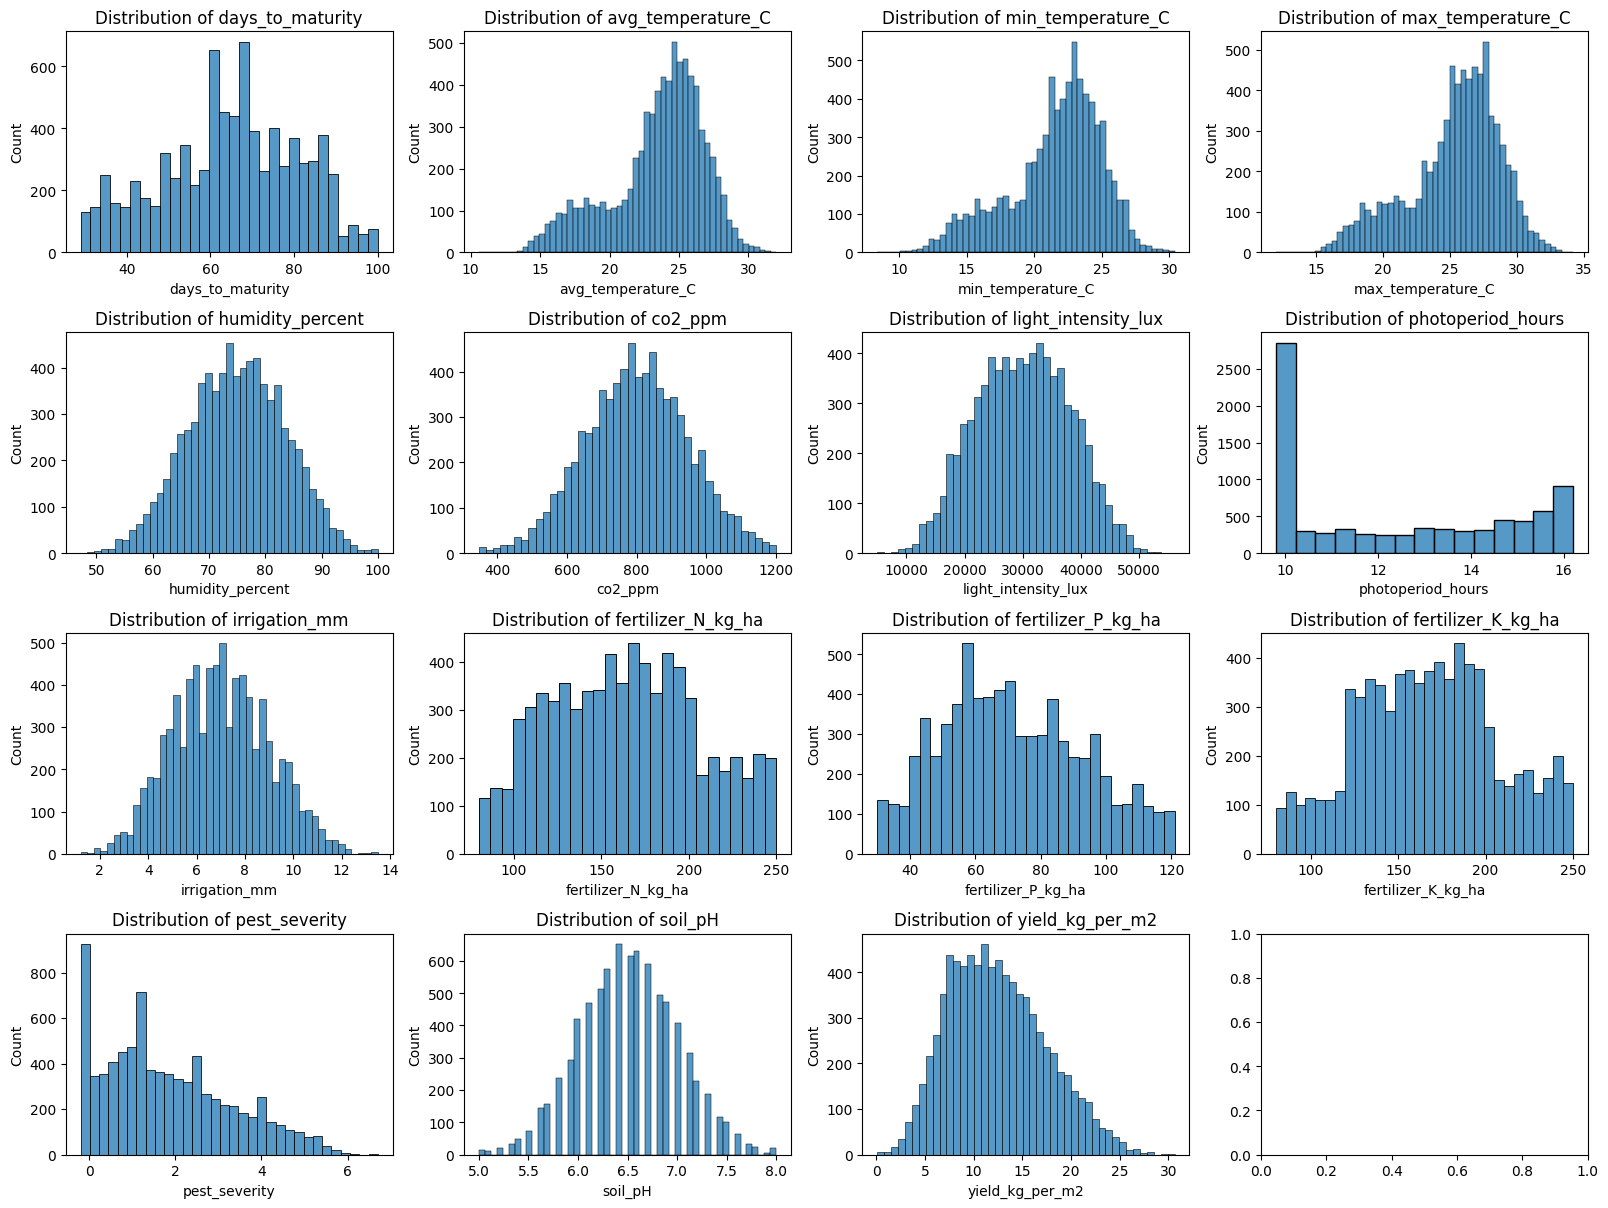

' \nHistogram 16 fitur numerik dari train_set asli (belum dimodifikasi). Dibaca bersama hasil skewness di EC 430 sebelumnya:\n| Kolom               | Skewness | Kategori                |\n| ------------------- | -------- | ----------------------- |\n| avg_temperature_C   | -0.73    | Moderately left-skewed  |\n| min_temperature_C   | -0.70    | Moderately left-skewed  |\n| max_temperature_C   | -0.67    | Moderately left-skewed  |\n| pest_severity       | +0.63    | Moderately right-skewed |\n| greenhouse_id       | < ±0.5   | Cukup simetris          |\n| humidity_percent    | < ±0.5   | Cukup simetris          |\n| co2_ppm             | < ±0.5   | Cukup simetris          |\n| light_intensity_lux | < ±0.5   | Cukup simetris          |\n| soil_pH             | < ±0.5   | Cukup simetris          |\n| fertilizer_N_kg_ha  | < ±0.5   | Cukup simetris          |\n| fertilizer_P_kg_ha  | < ±0.5   | Cukup simetris          |\n| fertilizer_K_kg_ha  | < ±0.5   | Cukup simetris          |\n'

In [83]:
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(16, 12))
axs = axs.flatten()

for i, column in enumerate(num_data):
    sns.histplot(train_set[column], ax=axs[i])
    axs[i].set_title(f'Distribution of {column}')

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
plt.show()


""" 
Histogram 16 fitur numerik dari train_set asli (belum dimodifikasi). Dibaca bersama hasil skewness di EC 430 sebelumnya:
| Kolom               | Skewness | Kategori                |
| ------------------- | -------- | ----------------------- |
| avg_temperature_C   | -0.73    | Moderately left-skewed  |
| min_temperature_C   | -0.70    | Moderately left-skewed  |
| max_temperature_C   | -0.67    | Moderately left-skewed  |
| pest_severity       | +0.63    | Moderately right-skewed |
| greenhouse_id       | < ±0.5   | Cukup simetris          |
| humidity_percent    | < ±0.5   | Cukup simetris          |
| co2_ppm             | < ±0.5   | Cukup simetris          |
| light_intensity_lux | < ±0.5   | Cukup simetris          |
| soil_pH             | < ±0.5   | Cukup simetris          |
| fertilizer_N_kg_ha  | < ±0.5   | Cukup simetris          |
| fertilizer_P_kg_ha  | < ±0.5   | Cukup simetris          |
| fertilizer_K_kg_ha  | < ±0.5   | Cukup simetris          |
"""

In [84]:
""" 
Bisa disimpulkan dari hasil statistik bahwa kolom yang terdeteksi missing values memiliki KEMUNGKINAN seperti berikut:
- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm -> MCAR
- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR or MNAR
- pest_severity, soil_pH -> MCAR

Tetapi jika dilihat dari visualisasi missing value, kolom yang terdeteksi missing value memiliki KEMUNGKINAN seperti berikut:
- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux -> MAR
- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR
- co2_ppm -> MCAR / MAR
- pest_severity, soil_pH -> MCAR (sesuai dari hasil uji statistik)

Strategi Penanganan Missing Value
Secara teori:
1. MCAR
Beberapa metode yang dapat digunakan:
    - Listwise deletion (drop missing rows)
    - Mean imputation
    - Median imputation
    - Arbitrary value imputation
2. MAR
Beberapa metode yang dapat digunakan:
    - Mean imputation
    - Median imputation
    - Mean/Median + Missing Indicator
    - Model-based imputation (KNN, MICE, dll.)

Pemilihan Metode
Karena:
- Persentase missing value relatif rendah (sekitar ≤ 10%)
- Jumlah data tidak terlalu besar
- Menghapus baris akan mengurangi jumlah observasi
- Sebagian besar fitur numerik memiliki distribusi yang relatif simetris
- Missingness kemungkinan mengandung informasi tambahan

Maka metode utama yang dipilih adalah:
    Median Imputation + Missing Indicator

Alasannya:
- Median lebih robust terhadap outlier.
- Dapat digunakan baik pada distribusi normal maupun tidak normal.
- Missing Indicator memungkinkan model memanfaatkan informasi bahwa suatu nilai sebelumnya hilang.
- Tidak mengurangi jumlah data seperti listwise deletion.

Eksperimen yang Direkomendasikan
- Mean imputation
- Median imputation
- Mean imputation + missing indicator
"""

' \nBisa disimpulkan dari hasil statistik bahwa kolom yang terdeteksi missing values memiliki KEMUNGKINAN seperti berikut:\n- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux, co2_ppm -> MCAR\n- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR or MNAR\n- pest_severity, soil_pH -> MCAR\n\nTetapi jika dilihat dari visualisasi missing value, kolom yang terdeteksi missing value memiliki KEMUNGKINAN seperti berikut:\n- avg_temperature_C, min_temperature_C, max_temperature_C, humidity_percent, light_intensity_lux -> MAR\n- fertilizer_N_kg_ha, fertilizer_P_kg_ha, fertilizer_K_kg_ha -> MAR\n- co2_ppm -> MCAR / MAR\n- pest_severity, soil_pH -> MCAR (sesuai dari hasil uji statistik)\n\nStrategi Penanganan Missing Value\nSecara teori:\n1. MCAR\nBeberapa metode yang dapat digunakan:\n    - Listwise deletion (drop missing rows)\n    - Mean imputation\n    - Median imputation\n    - Arbitrary value imputation\n2. MAR\nBeberapa metode yan

In [85]:
""" 
Melakukan eksplorasi lebih dalam agar dapat melihat dan membandingkan hasil dari setiap metode yang digunakan sebelum dipilih dan masuk ke dalam pipeline
"""

' \nMelakukan eksplorasi lebih dalam agar dapat melihat dan membandingkan hasil dari setiap metode yang digunakan sebelum dipilih dan masuk ke dalam pipeline\n'

In [86]:
data_exp = train_set.copy()

In [87]:
data_exp.describe()

,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
count,8193.000000,7779.000000,7779.000000,7779.000000,7779.000000,7753.000000,7779.000000,8193.000000,8193.000000,7355.000000,7355.000000,7355.000000,8094.000000,7958.000000,8193.000000
mean,64.710607,23.454711,21.559712,25.340815,74.929130,800.319360,30051.478339,12.457110,7.006591,163.755404,71.497213,166.934874,1.833086,6.505202,12.409148
std,16.366174,3.390432,3.467815,3.443970,8.572613,148.113236,8076.118222,2.311478,1.983780,42.191382,21.602261,39.650468,1.452429,0.496736,4.976525
min,29.000000,10.600000,8.400000,12.000000,47.200000,348.000000,5000.000000,9.800000,1.200000,80.000000,30.000000,80.000000,-0.200000,5.000000,0.100000
25%,53.000000,21.800000,19.800000,23.500000,68.900000,700.000000,24053.500000,10.000000,5.600000,130.000000,55.000000,137.000000,0.600000,6.200000,8.550000
50%,65.000000,24.100000,22.200000,26.000000,75.000000,800.000000,30114.000000,12.100000,7.000000,163.000000,69.000000,167.000000,1.600000,6.500000,11.970000
75%,77.000000,25.800000,24.000000,27.700000,81.100000,902.000000,36091.000000,14.800000,8.400000,194.000000,87.000000,194.000000,2.800000,6.800000,15.750000
max,100.000000,32.000000,30.400000,34.200000,100.000000,1200.000000,56075.000000,16.200000,13.500000,250.000000,121.000000,250.000000,6.700000,8.000000,30.640000


In [88]:
for var in ['avg_temperature_C', 'min_temperature_C', 'max_temperature_C', 'humidity_percent', 'light_intensity_lux', 'fertilizer_N_kg_ha', 'fertilizer_P_kg_ha', 'fertilizer_K_kg_ha', 'co2_ppm', 'pest_severity', 'soil_pH']:
    data_exp[var + '_missing'] = np.where(data_exp[var].isnull(), 1, 0)

In [89]:
cols_to_exclude = ['avg_temperature_C_missing', 'min_temperature_C_missing', 'max_temperature_C_missing', 'humidity_percent_missing', 'light_intensity_lux_missing', 'fertilizer_N_kg_ha_missing', 'fertilizer_P_kg_ha_missing', 'fertilizer_K_kg_ha_missing', 'co2_ppm_missing', 'pest_severity_missing', 'soil_pH_missing']

num_data_exp = data_exp.select_dtypes(include=['number']).columns.drop(cols_to_exclude)
cat_data_exp = data_exp.select_dtypes(include=['object']).columns

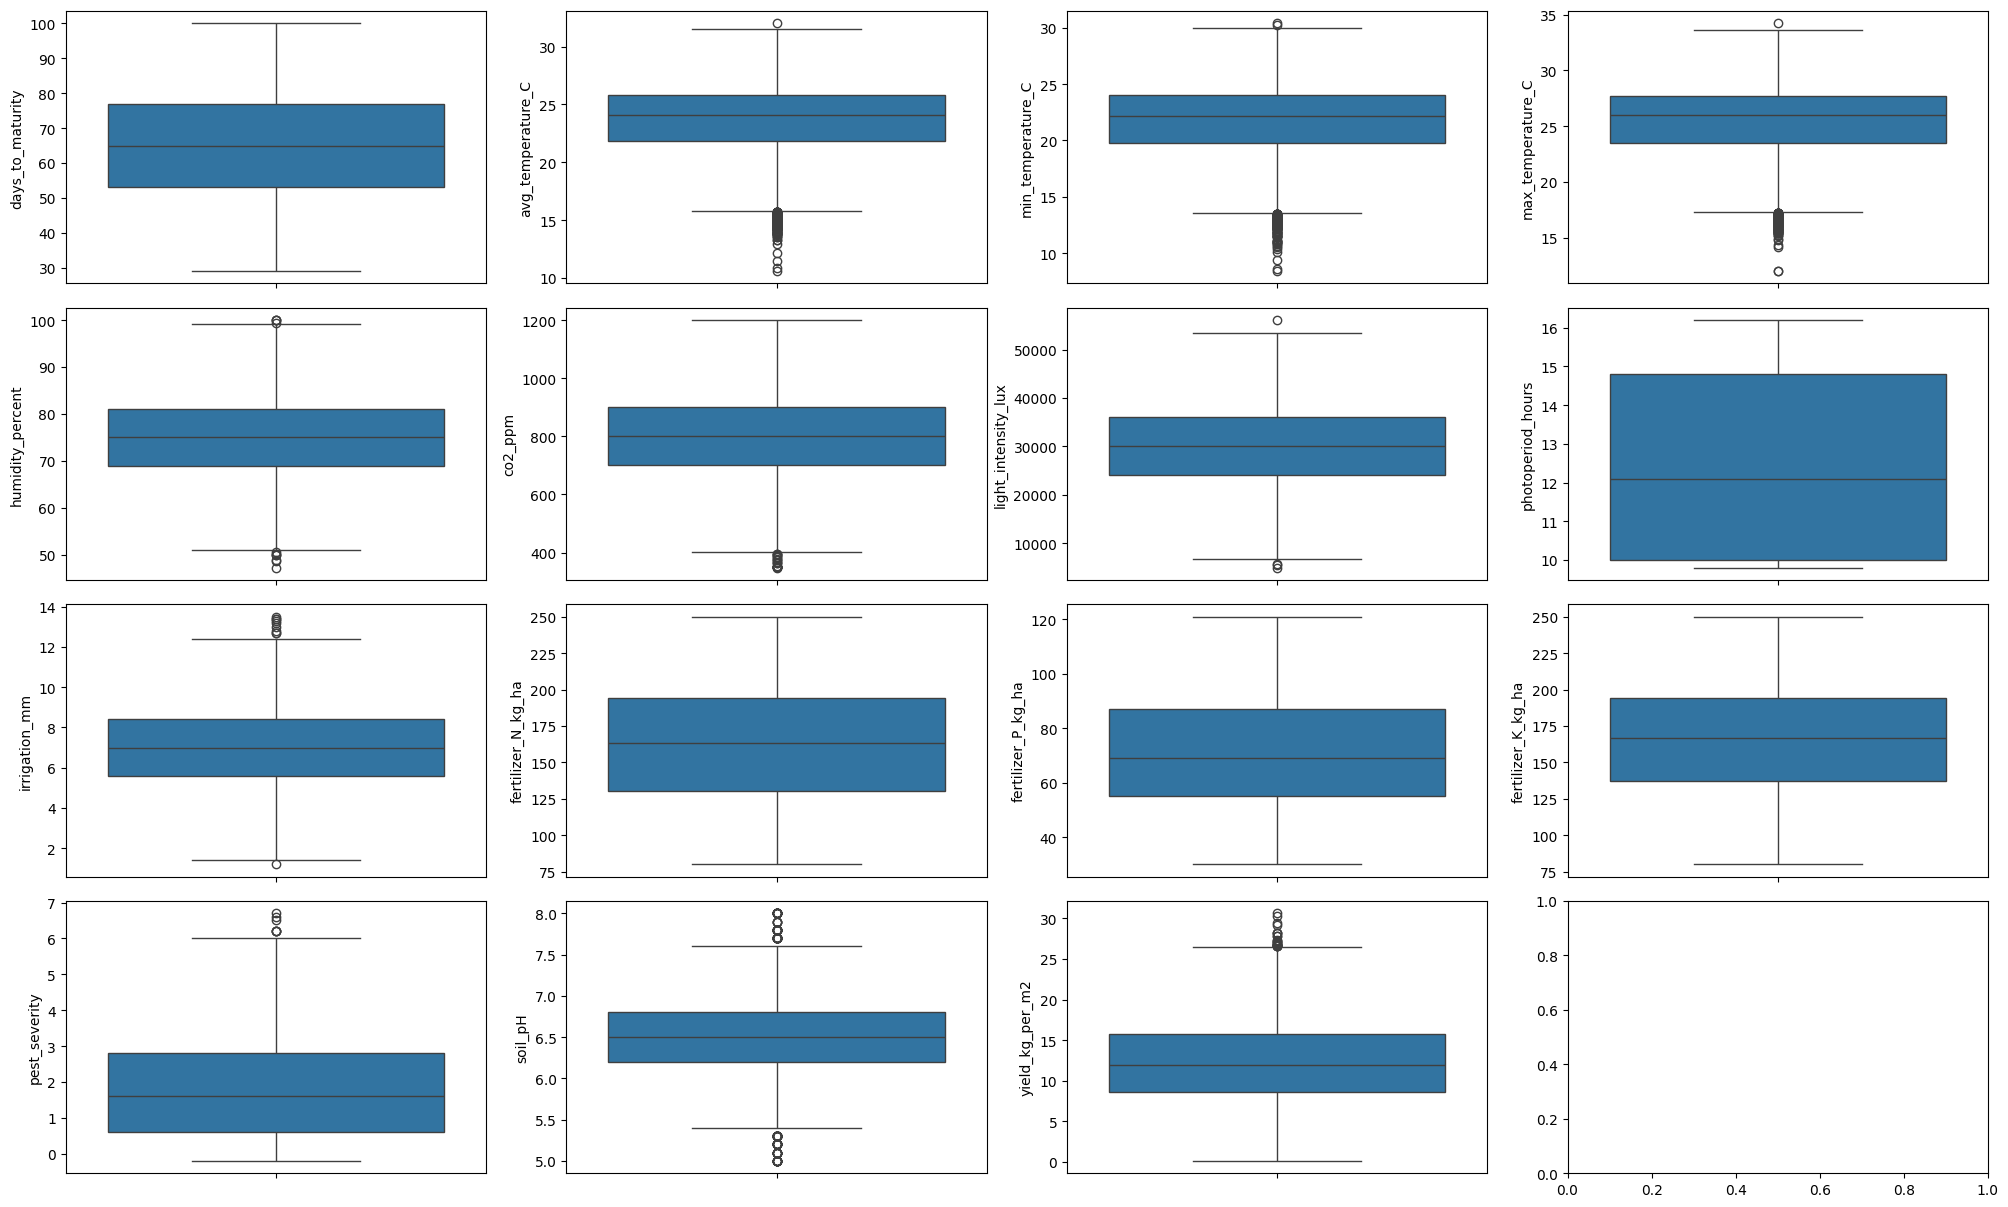

' \nBoxplot IQR *1.5 untuk data_exp (copy dari train_set, belum diimputasi). Dua hal penting yang terjadi sebelum cell ini:\n- dibuat kolom _missing binary (missing indicator) untuk 11 kolom yang punya missing values\n- num_data_exp didefinisikan dengan mengecualikan kolom-kolom indicator dan kolom tanggal turunan, sehingga boxplot hanya menampilkan fitur numerik asli\nIni adalah snapshot outlier sebelum imputasi — jadi jika ada outlier di sini, itu memang outlier asli dari data, bukan artefak imputasi.\n'

In [90]:
def vis_outliers(data):
    fig, axs = plt.subplots(ncols=4, nrows=4, figsize=(20,12))
    axs = axs.flatten()

    for i, column in enumerate(data):
        sns.boxplot(y=data[column], data=data, ax=axs[i], whis=1.5)

    plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
    plt.show()

vis_outliers(data_exp[num_data_exp])

""" 
Boxplot IQR *1.5 untuk data_exp (copy dari train_set, belum diimputasi). Dua hal penting yang terjadi sebelum cell ini:
- dibuat kolom _missing binary (missing indicator) untuk 11 kolom yang punya missing values
- num_data_exp didefinisikan dengan mengecualikan kolom-kolom indicator dan kolom tanggal turunan, sehingga boxplot hanya menampilkan fitur numerik asli
Ini adalah snapshot outlier sebelum imputasi — jadi jika ada outlier di sini, itu memang outlier asli dari data, bukan artefak imputasi.
"""

In [91]:
data_exp['avg_temperature_C'] = data_exp['avg_temperature_C'].fillna(data_exp['avg_temperature_C'].median())
data_exp['min_temperature_C'] = data_exp['min_temperature_C'].fillna(data_exp['min_temperature_C'].median())
data_exp['max_temperature_C'] = data_exp['max_temperature_C'].fillna(data_exp['max_temperature_C'].median())
data_exp['humidity_percent'] = data_exp['humidity_percent'].fillna(data_exp['humidity_percent'].median())
data_exp['light_intensity_lux'] = data_exp['light_intensity_lux'].fillna(data_exp['light_intensity_lux'].median())
data_exp['fertilizer_N_kg_ha'] = data_exp['fertilizer_N_kg_ha'].fillna(data_exp['fertilizer_N_kg_ha'].median())
data_exp['fertilizer_P_kg_ha'] = data_exp['fertilizer_P_kg_ha'].fillna(data_exp['fertilizer_P_kg_ha'].median())
data_exp['fertilizer_K_kg_ha'] = data_exp['fertilizer_K_kg_ha'].fillna(data_exp['fertilizer_K_kg_ha'].median())
data_exp['co2_ppm'] = data_exp['co2_ppm'].fillna(data_exp['co2_ppm'].median())
data_exp['pest_severity'] = data_exp['pest_severity'].fillna(data_exp['pest_severity'].median())
data_exp['soil_pH'] = data_exp['soil_pH'].fillna(data_exp['soil_pH'].median())


""" 
Mengapa median lebih tepat di sini:
- avg/min/max_temperature_C memiliki skewness ~-0.7 → median tidak tertarik ke ekor kiri seperti mean
- pest_severity skewness +0.63 → median lebih representatif dari nilai tengah sebenarnya
- Kolom-kolom simetris (skewness < ±0.5) → mean ≈ median, jadi tidak ada perbedaan signifikan
Strategi lengkap yang dipakai: Median Imputation + Missing Indicator — nilai diisi median, tapi kolom _missing sudah dibuat agar model tetap bisa "tahu" baris mana yang asalnya kosong.
"""

' \nMengapa median lebih tepat di sini:\n- avg/min/max_temperature_C memiliki skewness ~-0.7 → median tidak tertarik ke ekor kiri seperti mean\n- pest_severity skewness +0.63 → median lebih representatif dari nilai tengah sebenarnya\n- Kolom-kolom simetris (skewness < ±0.5) → mean ≈ median, jadi tidak ada perbedaan signifikan\nStrategi lengkap yang dipakai: Median Imputation + Missing Indicator — nilai diisi median, tapi kolom _missing sudah dibuat agar model tetap bisa "tahu" baris mana yang asalnya kosong.\n'

In [92]:
data_exp.describe()

,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,avg_temperature_C_missing,min_temperature_C_missing,max_temperature_C_missing,humidity_percent_missing,light_intensity_lux_missing,fertilizer_N_kg_ha_missing,fertilizer_P_kg_ha_missing,fertilizer_K_kg_ha_missing,co2_ppm_missing,pest_severity_missing,soil_pH_missing
count,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000
mean,64.710607,23.487318,21.592066,25.374124,74.932711,800.302209,30054.637617,12.457110,7.006591,163.678140,71.241792,166.941535,1.830270,6.505053,12.409148,0.050531,0.050531,0.050531,0.050531,0.050531,0.102282,0.102282,0.102282,0.053704,0.012083,0.028683
std,16.366174,3.306673,3.381962,3.358923,8.353202,144.080708,7869.412720,2.311478,1.983780,39.975851,20.481544,37.567753,1.443851,0.489560,4.976525,0.219051,0.219051,0.219051,0.219051,0.219051,0.303038,0.303038,0.303038,0.225447,0.109265,0.166924
min,29.000000,10.600000,8.400000,12.000000,47.200000,348.000000,5000.000000,9.800000,1.200000,80.000000,30.000000,80.000000,-0.200000,5.000000,0.100000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,53.000000,22.000000,20.000000,23.700000,69.300000,705.000000,24311.000000,10.000000,5.600000,133.000000,56.000000,141.000000,0.700000,6.200000,8.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,65.000000,24.100000,22.200000,26.000000,75.000000,800.000000,30114.000000,12.100000,7.000000,163.000000,69.000000,167.000000,1.600000,6.500000,11.970000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,77.000000,25.700000,23.900000,27.600000,80.700000,896.000000,35732.000000,14.800000,8.400000,191.000000,85.000000,191.000000,2.800000,6.800000,15.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,100.000000,32.000000,30.400000,34.200000,100.000000,1200.000000,56075.000000,16.200000,13.500000,250.000000,121.000000,250.000000,6.700000,8.000000,30.640000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


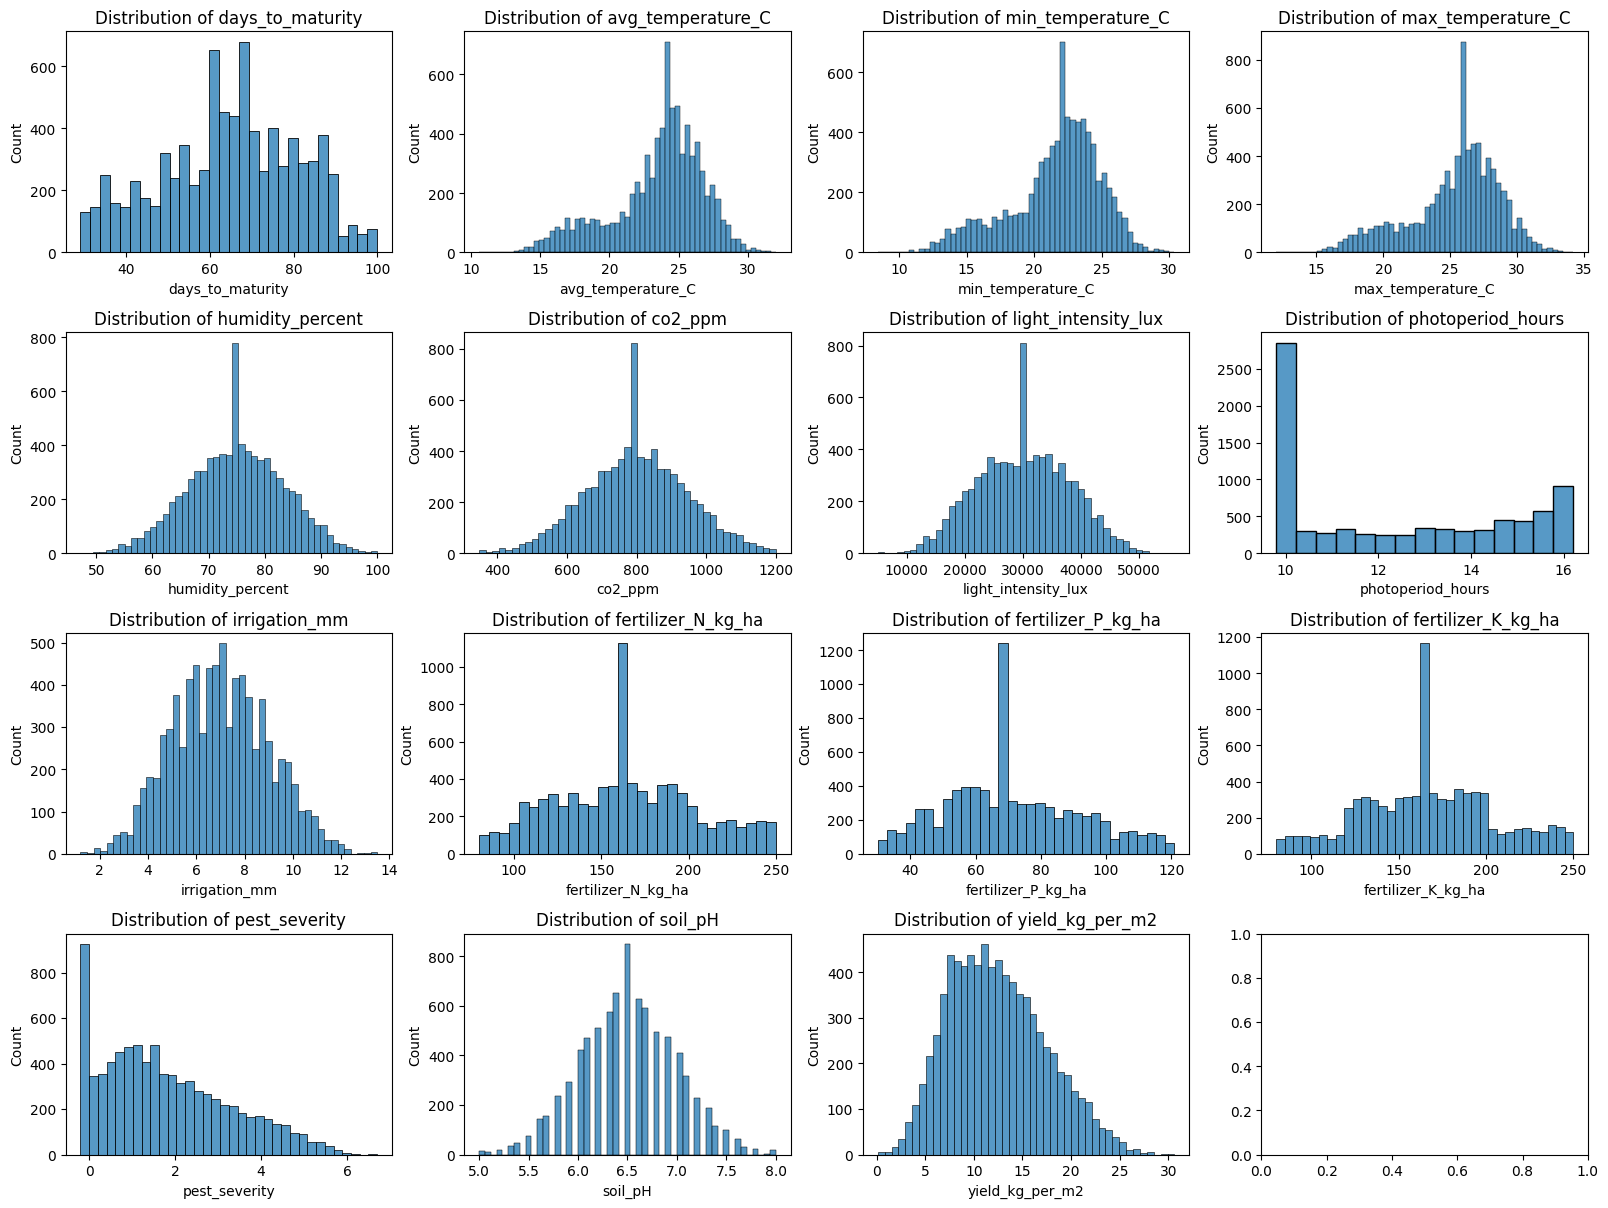

' \nHistogram yang sama, tapi sekarang menggunakan data_exp yang sudah penuh (tidak ada NaN). Yang diharapkan terlihat:\n- Distribusi tidak berubah drastis — karena missing ≤ 10%, pengisian median hanya menambahkan nilai di sekitar pusat distribusi, tidak menggeser bentuknya secara signifikan\n- Kemungkinan muncul spike kecil di titik median pada beberapa kolom yang skewed (seperti avg_temperature_C) — ini adalah tanda khas median imputation, tapi efeknya minimal jika persentase missing kecil\n'

In [93]:
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(16, 12))
axs = axs.flatten()

for i, column in enumerate(num_data_exp):
    sns.histplot(data_exp[column], ax=axs[i])
    axs[i].set_title(f'Distribution of {column}')

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
plt.show()

""" 
Histogram yang sama, tapi sekarang menggunakan data_exp yang sudah penuh (tidak ada NaN). Yang diharapkan terlihat:
- Distribusi tidak berubah drastis — karena missing ≤ 10%, pengisian median hanya menambahkan nilai di sekitar pusat distribusi, tidak menggeser bentuknya secara signifikan
- Kemungkinan muncul spike kecil di titik median pada beberapa kolom yang skewed (seperti avg_temperature_C) — ini adalah tanda khas median imputation, tapi efeknya minimal jika persentase missing kecil
"""

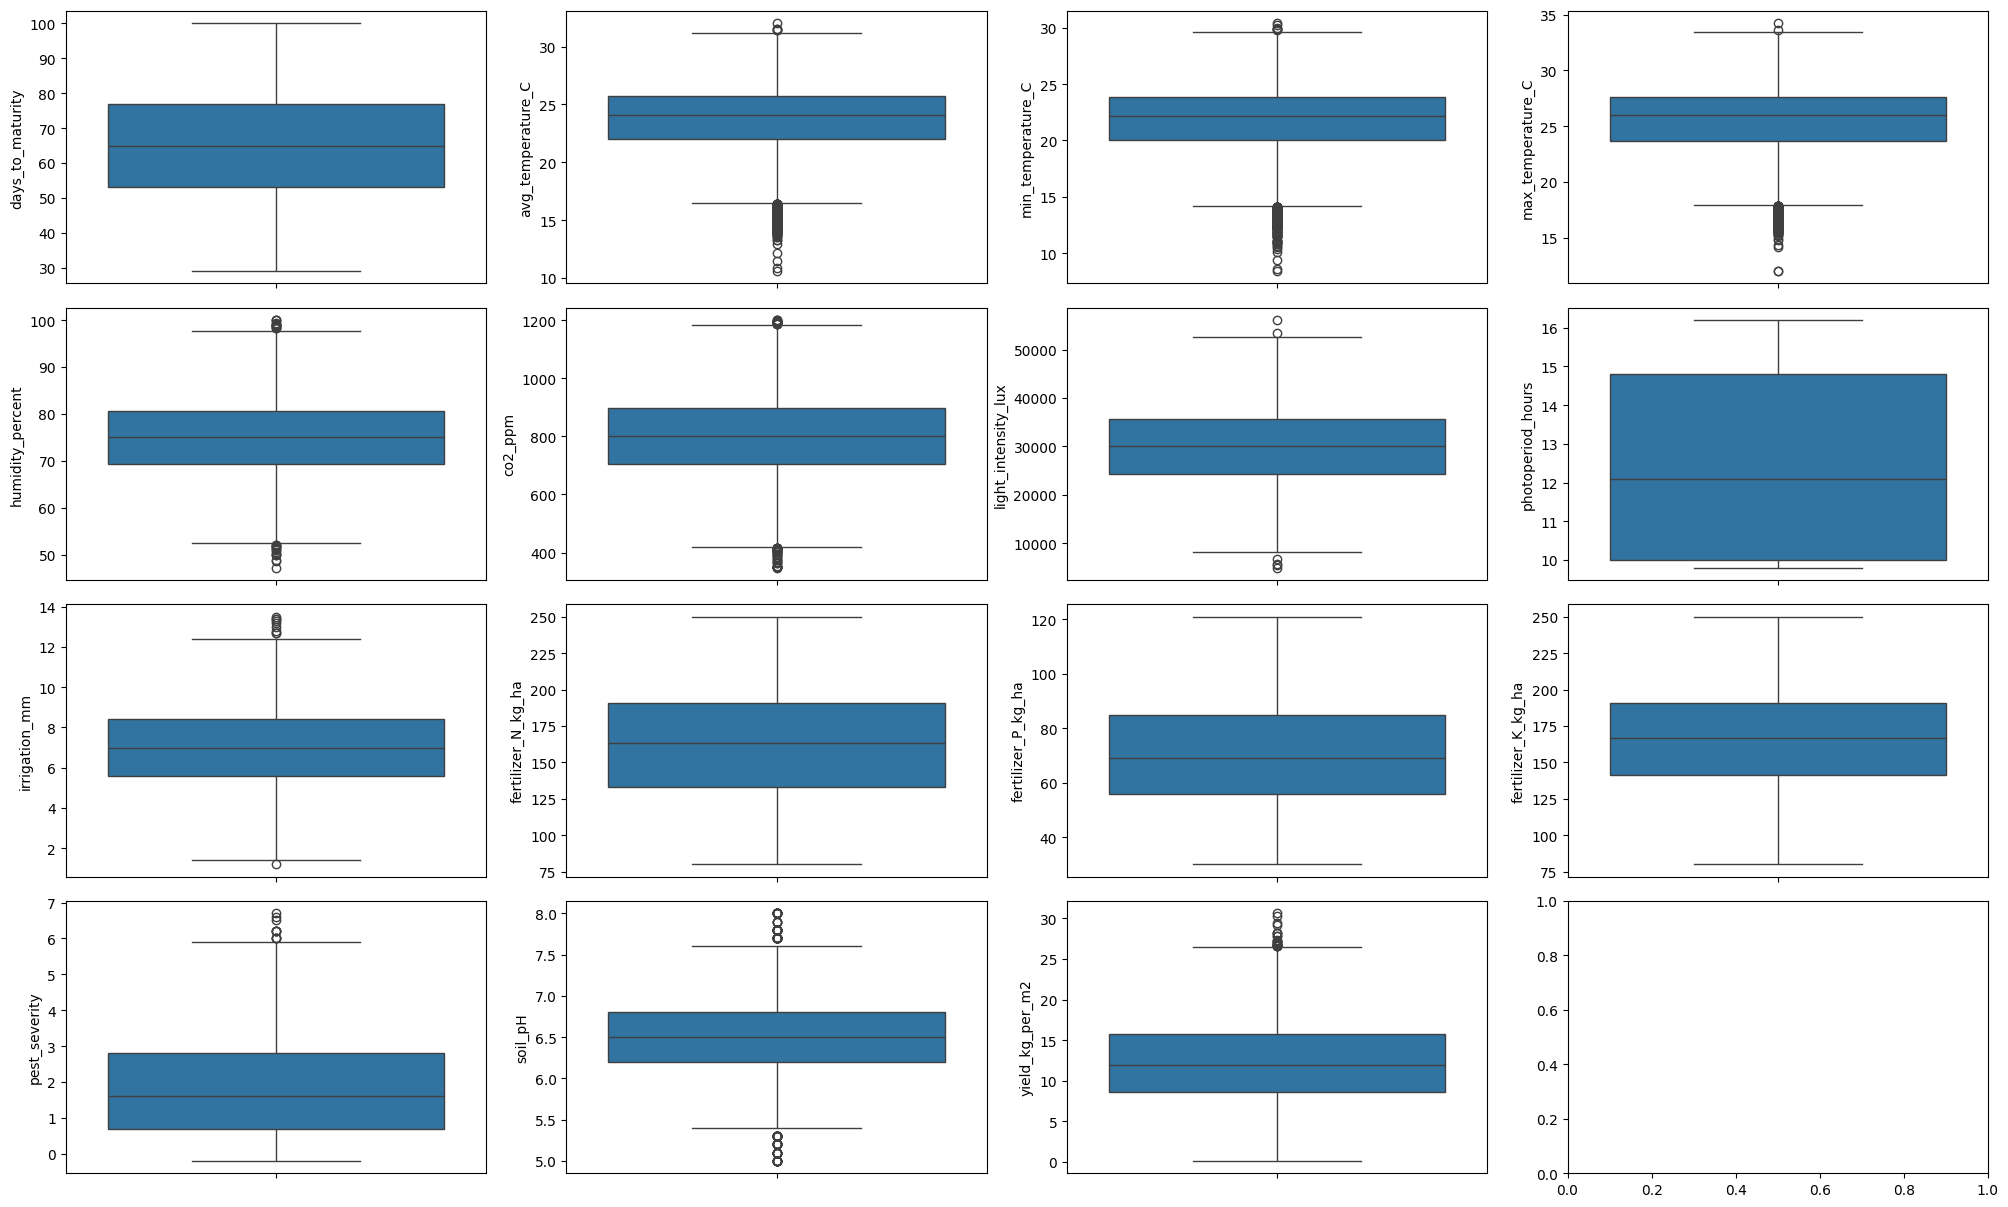

' \nBoxplot yang sama, setelah imputasi. Karena median diisi di tengah distribusi, maka:\n- Outlier lama tetap ada — median imputation tidak menyentuh nilai yang sudah terisi, jadi outlier asli tidak hilang\n- Tidak ada outlier baru — nilai yang diisi (median) selalu berada di dalam IQR, jadi tidak mungkin menjadi outlier baru\n- Jika boxplot EC 437 dan EC 441 terlihat hampir identik, itu tanda bahwa imputasi berjalan dengan baik dan tidak mencemari distribusi\n'

In [94]:
vis_outliers(data_exp[num_data_exp])

""" 
Boxplot yang sama, setelah imputasi. Karena median diisi di tengah distribusi, maka:
- Outlier lama tetap ada — median imputation tidak menyentuh nilai yang sudah terisi, jadi outlier asli tidak hilang
- Tidak ada outlier baru — nilai yang diisi (median) selalu berada di dalam IQR, jadi tidak mungkin menjadi outlier baru
- Jika boxplot EC 437 dan EC 441 terlihat hampir identik, itu tanda bahwa imputasi berjalan dengan baik dan tidak mencemari distribusi
"""

## Handle Outlier

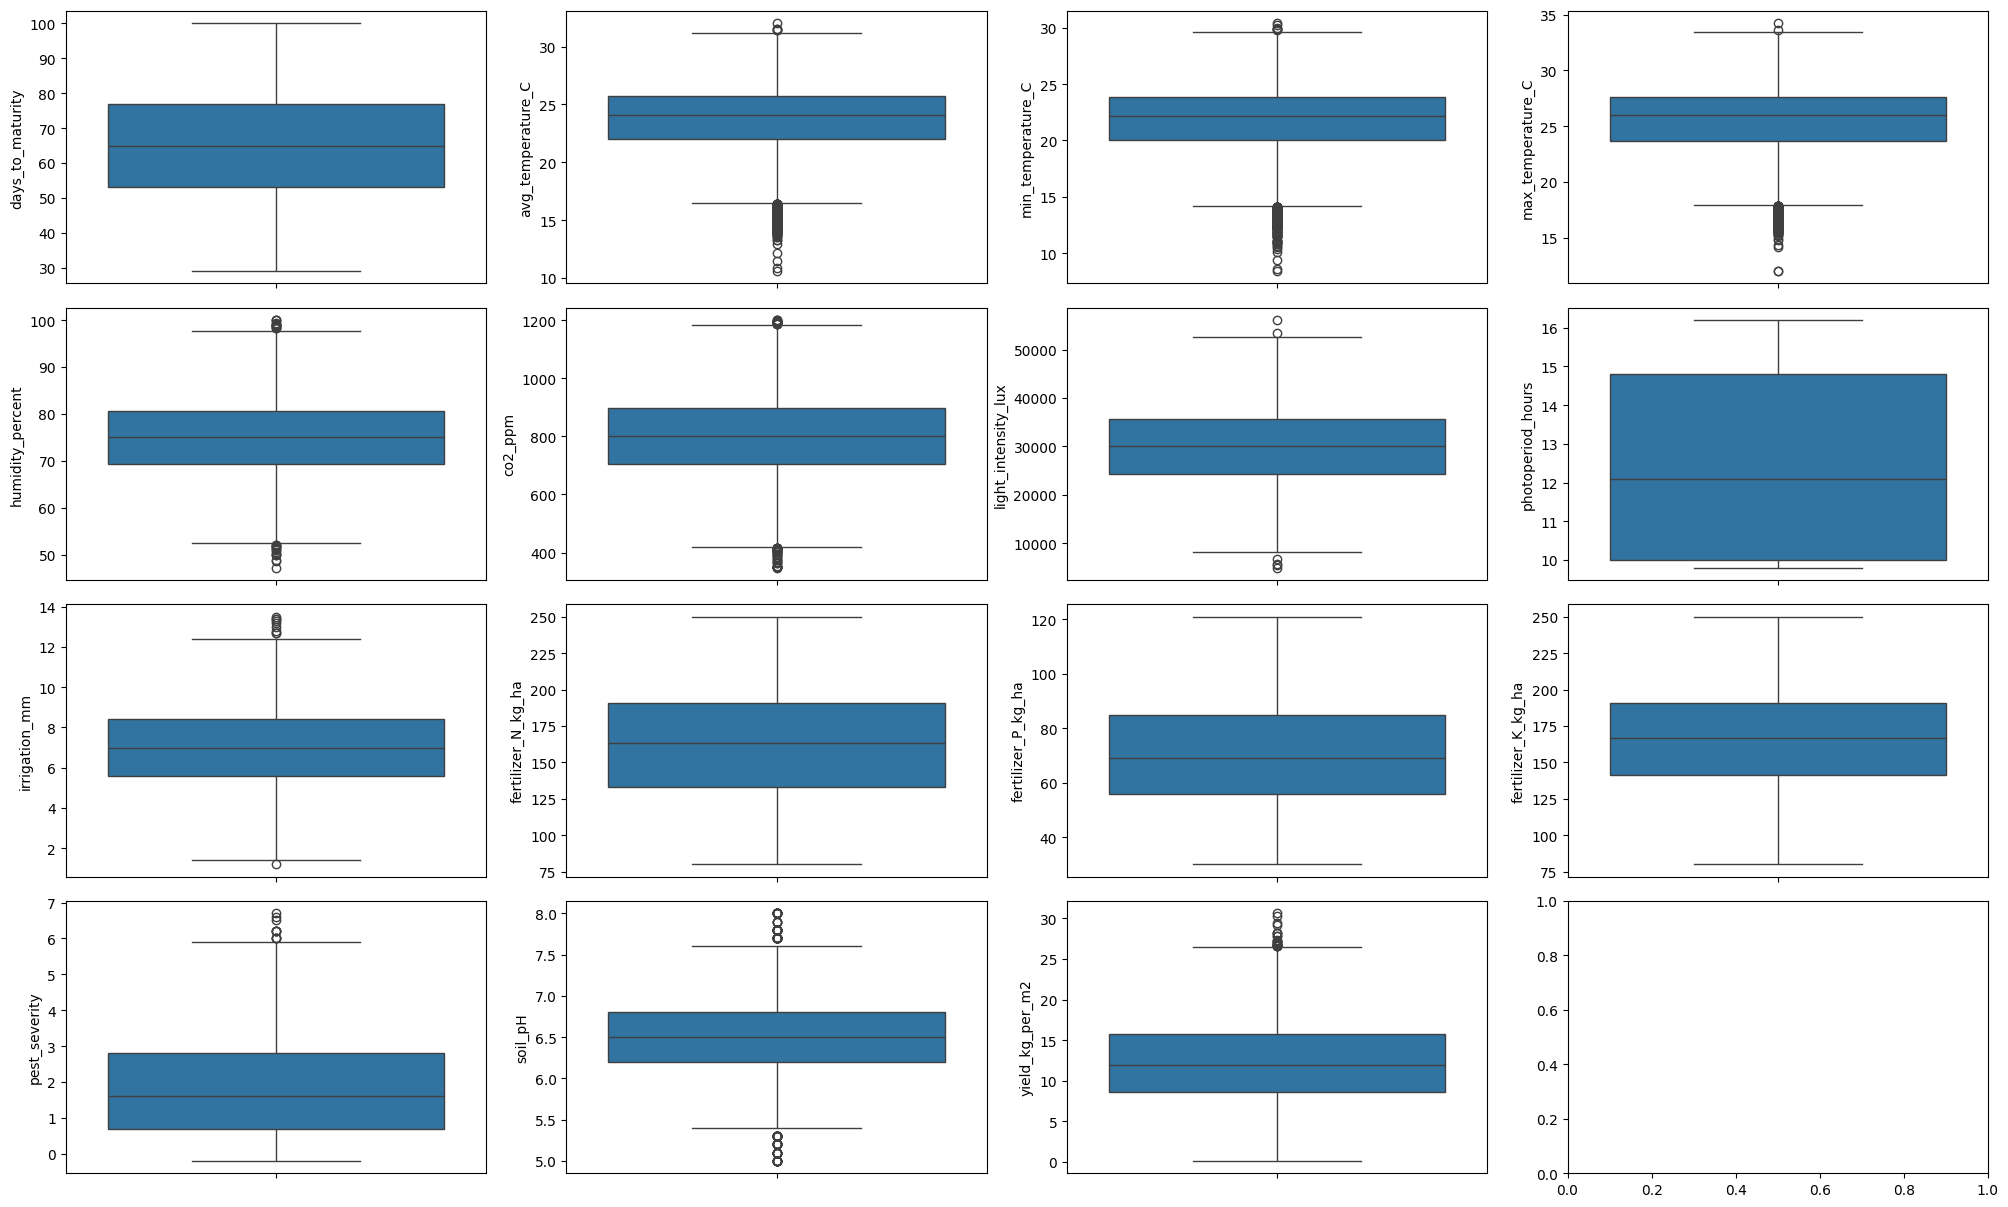

In [95]:
vis_outliers(data_exp[num_data_exp])

In [96]:
data_exp.describe()

,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,avg_temperature_C_missing,min_temperature_C_missing,max_temperature_C_missing,humidity_percent_missing,light_intensity_lux_missing,fertilizer_N_kg_ha_missing,fertilizer_P_kg_ha_missing,fertilizer_K_kg_ha_missing,co2_ppm_missing,pest_severity_missing,soil_pH_missing
count,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000,8193.000000
mean,64.710607,23.487318,21.592066,25.374124,74.932711,800.302209,30054.637617,12.457110,7.006591,163.678140,71.241792,166.941535,1.830270,6.505053,12.409148,0.050531,0.050531,0.050531,0.050531,0.050531,0.102282,0.102282,0.102282,0.053704,0.012083,0.028683
std,16.366174,3.306673,3.381962,3.358923,8.353202,144.080708,7869.412720,2.311478,1.983780,39.975851,20.481544,37.567753,1.443851,0.489560,4.976525,0.219051,0.219051,0.219051,0.219051,0.219051,0.303038,0.303038,0.303038,0.225447,0.109265,0.166924
min,29.000000,10.600000,8.400000,12.000000,47.200000,348.000000,5000.000000,9.800000,1.200000,80.000000,30.000000,80.000000,-0.200000,5.000000,0.100000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,53.000000,22.000000,20.000000,23.700000,69.300000,705.000000,24311.000000,10.000000,5.600000,133.000000,56.000000,141.000000,0.700000,6.200000,8.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,65.000000,24.100000,22.200000,26.000000,75.000000,800.000000,30114.000000,12.100000,7.000000,163.000000,69.000000,167.000000,1.600000,6.500000,11.970000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,77.000000,25.700000,23.900000,27.600000,80.700000,896.000000,35732.000000,14.800000,8.400000,191.000000,85.000000,191.000000,2.800000,6.800000,15.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,100.000000,32.000000,30.400000,34.200000,100.000000,1200.000000,56075.000000,16.200000,13.500000,250.000000,121.000000,250.000000,6.700000,8.000000,30.640000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [97]:
data_exp.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8193 entries, 561 to 7270
Data columns (total 29 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   greenhouse_id                8193 non-null   object 
 1   crop_type                    8193 non-null   object 
 2   variety                      8193 non-null   object 
 3   days_to_maturity             8193 non-null   float64
 4   avg_temperature_C            8193 non-null   float64
 5   min_temperature_C            8193 non-null   float64
 6   max_temperature_C            8193 non-null   float64
 7   humidity_percent             8193 non-null   float64
 8   co2_ppm                      8193 non-null   float64
 9   light_intensity_lux          8193 non-null   float64
 10  photoperiod_hours            8193 non-null   float64
 11  irrigation_mm                8193 non-null   float64
 12  fertilizer_N_kg_ha           8193 non-null   float64
 13  fertilizer_P_kg_ha   

In [98]:
def cap_outliers(df, columns):
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR 
        upper = Q3 + 1.5 * IQR 
        df[col] = df[col].clip(lower=lower, upper=upper)
    return df

cols_to_cap = [
    'avg_temperature_C', 'min_temperature_C', 'max_temperature_C',
    'humidity_percent', 'co2_ppm', 'light_intensity_lux',
    'irrigation_mm', 'pest_severity', 'soil_pH', 'yield_kg_per_m2'
]

data_exp = cap_outliers(data_exp, cols_to_cap)

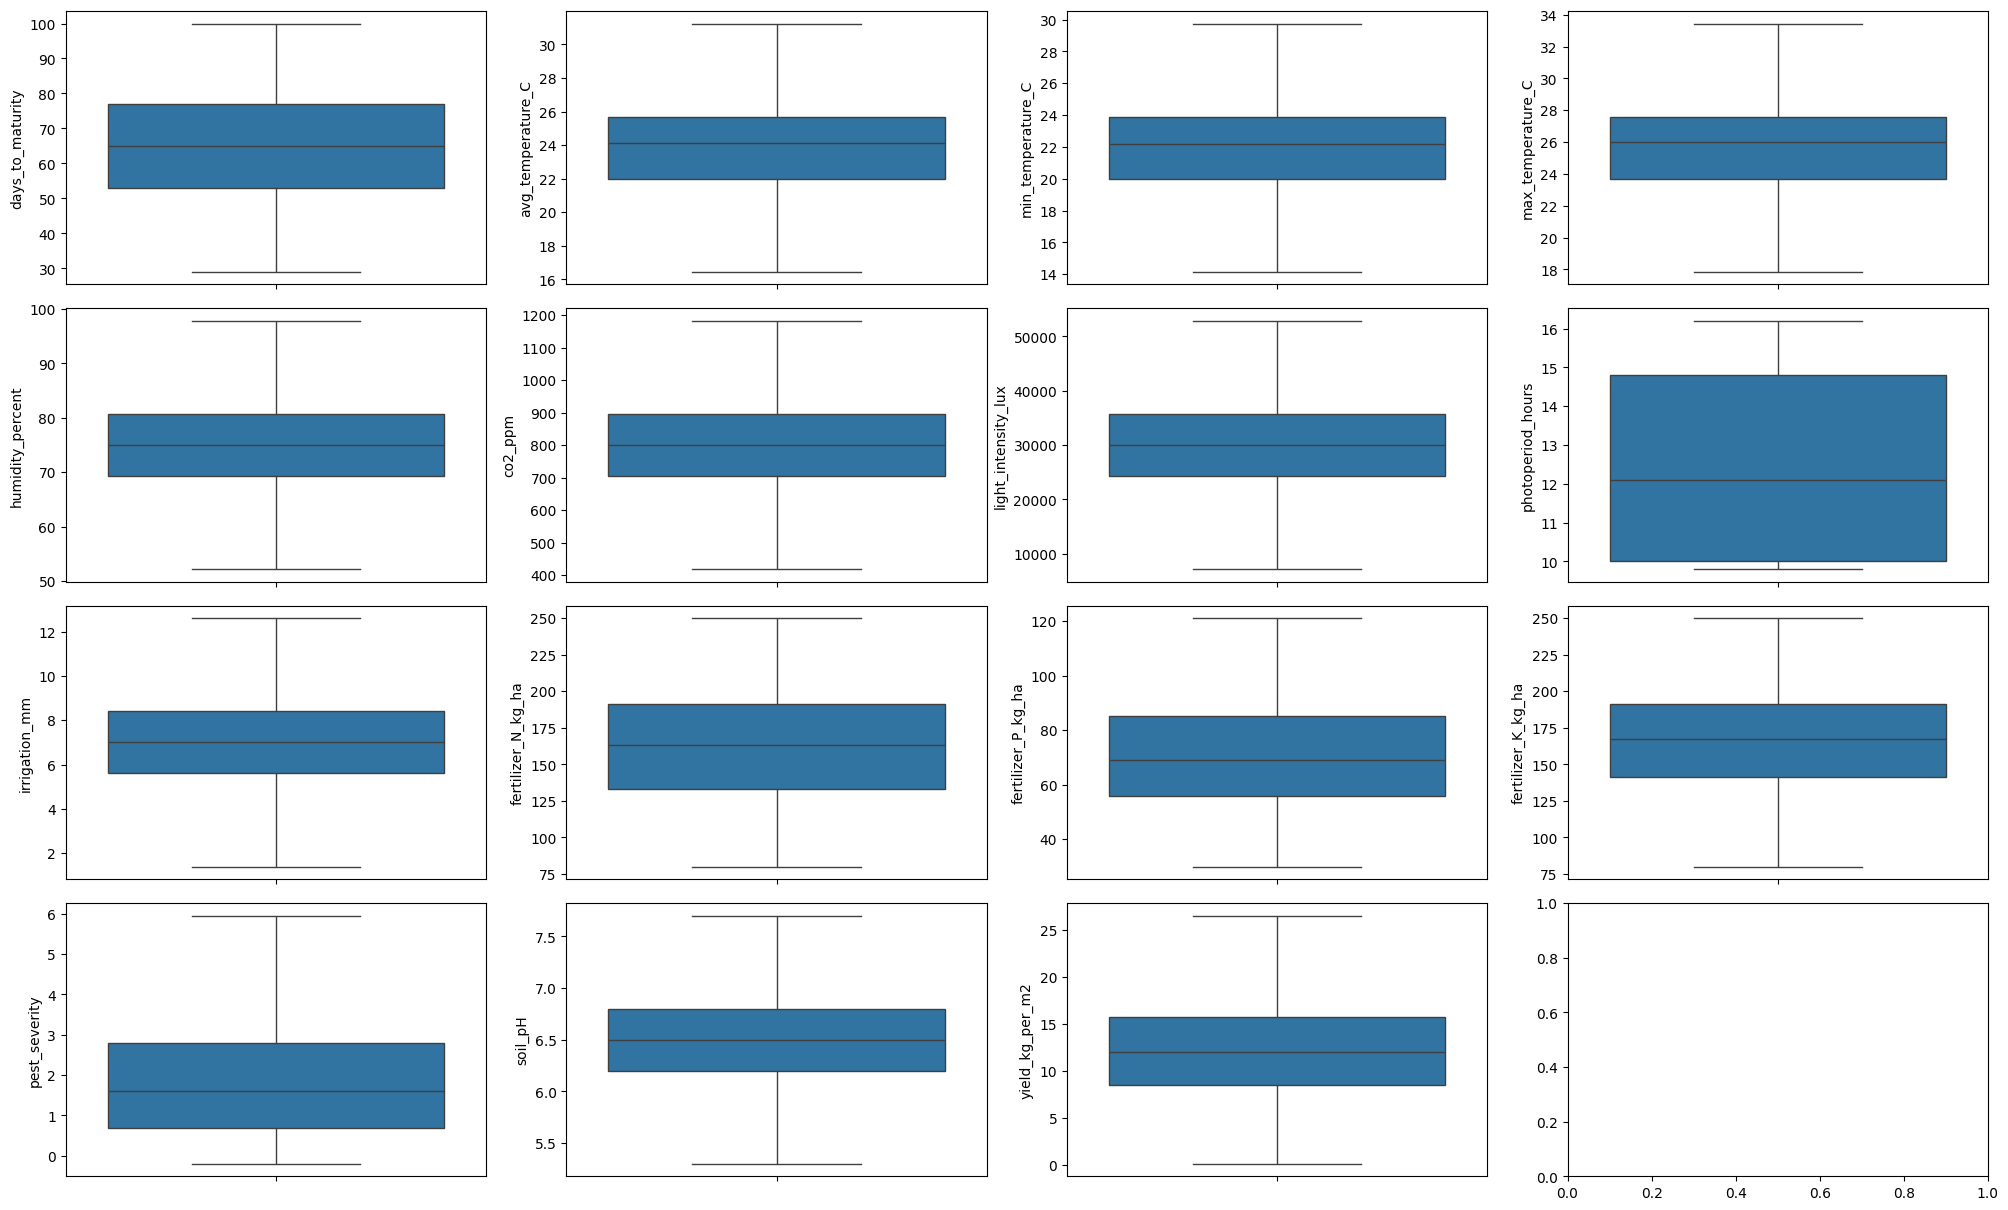

In [99]:
vis_outliers(data_exp[num_data_exp])

In [100]:
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        X = pd.DataFrame(X) if not hasattr(X, 'loc') else X
        self.bounds_ = {}
        for col in X.columns:
            Q1 = X[col].quantile(0.25)
            Q3 = X[col].quantile(0.75)
            IQR = Q3 - Q1
            self.bounds_[col] = (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
        return self

    def transform(self, X):
        is_df = hasattr(X, 'loc')
        X = pd.DataFrame(X) if not is_df else X.copy()
        for col, (lower, upper) in self.bounds_.items():
            X[col] = X[col].clip(lower=lower, upper=upper)
        return X.values if not is_df else X

# Feature Engineering

## Feature Scalling

In [101]:
indicator_cols = [
    col for col in data_exp.columns if col.endswith('_missing')
]

indicator_df = data_exp[indicator_cols]

In [102]:
encoder = OneHotEncoder(handle_unknown='ignore',
                        sparse_output=False)

cat_encoded = encoder.fit_transform(
    data_exp[cat_data_exp]
)

cat_encoder = pd.DataFrame(
    cat_encoded,
    columns=encoder.get_feature_names_out(cat_data_exp),
    index=data_exp.index
)

In [103]:
scaler = StandardScaler()

num_scaled = scaler.fit_transform(data_exp[num_data_exp])

num_scaled = pd.DataFrame(
    num_scaled,
    columns=num_data_exp,
    index=data_exp.index
)

In [104]:
data_exp_processed = pd.concat(
    [cat_encoder, 
     num_scaled, 
     indicator_df], axis=1
)

data_exp_processed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8193 entries, 561 to 7270
Data columns (total 49 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   greenhouse_id_1.0            8193 non-null   float64
 1   greenhouse_id_2.0            8193 non-null   float64
 2   greenhouse_id_3.0            8193 non-null   float64
 3   greenhouse_id_4.0            8193 non-null   float64
 4   greenhouse_id_5.0            8193 non-null   float64
 5   crop_type_Cucumber           8193 non-null   float64
 6   crop_type_Lettuce            8193 non-null   float64
 7   crop_type_Pepper             8193 non-null   float64
 8   crop_type_Tomato             8193 non-null   float64
 9   variety_Beefsteak            8193 non-null   float64
 10  variety_Bell                 8193 non-null   float64
 11  variety_Butterhead           8193 non-null   float64
 12  variety_Cherry               8193 non-null   float64
 13  variety_English      

## Feature Selection

In [105]:
X = data_exp_processed.drop(columns='yield_kg_per_m2')
y = data_exp_processed['yield_kg_per_m2']

In [106]:
# Mutual Info Regressor

mi_scores = mutual_info_regression(
    X, y, random_state=42
)

mi = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

print(mi)

crop_type_Tomato               0.317386
days_to_maturity               0.274402
fertilizer_N_kg_ha             0.248186
fertilizer_K_kg_ha             0.210190
crop_type_Lettuce              0.185704
avg_temperature_C              0.158330
max_temperature_C              0.146416
min_temperature_C              0.137000
fertilizer_P_kg_ha             0.126805
irrigation_mm                  0.104168
crop_type_Cucumber             0.082938
variety_Beefsteak              0.061968
variety_Heirloom               0.056902
crop_type_Pepper               0.051434
variety_Cherry                 0.049489
variety_Romaine                0.048136
humidity_percent               0.043368
variety_Roma                   0.043260
variety_Iceberg                0.041575
variety_Butterhead             0.039918
variety_Leaf                   0.036505
light_intensity_lux            0.034314
variety_Slicing                0.031096
pest_severity                  0.027319
variety_Pickling               0.025604


In [107]:
""" 
Mengukur ketergantungan non-linear antara fitur dan target — tidak mengasumsikan hubungan linear, bisa menangkap pola kompleks apapun.
| Tier       | Fitur                                                                                                              | MI Score  |
| ---------- | ------------------------------------------------------------------------------------------------------------------ | --------- |
| Tinggi     | crop_type_Tomato, days_to_maturity, fertilizer_N_kg_ha, fertilizer_K_kg_ha                                         | 0.21-0.32 |
| Menengah   | crop_type_Lettuce, avg_temperature_C, max/min_temperature_C, fertilizer_P_kg_ha, irrigation_mm, crop_type_Cucumber | 0.08-0.19 |
| Rendah     | variety_*, humidity_percent, light_intensity_lux, pest_severity, photoperiod_hours, soil_pH, greenhouse_id         | 0.01-0.06 |
| Nyaris nol | semua _missing, co2_ppm                                                                                            | < 0.008   |

Yang menarik: MI sangat berbeda dari RF/Permutation — days_to_maturity, fertilizer_N/K_kg_ha, dan crop_type_Lettuce jauh lebih tinggi skornya. light_intensity_lux justru rendah di MI (0.034) padahal tinggi di RF/Permutation. Ini karena MI menangkap hubungan non-linear yang mungkin tidak ditangkap secara parsial oleh tree-based methods.
"""

' \nMengukur ketergantungan non-linear antara fitur dan target — tidak mengasumsikan hubungan linear, bisa menangkap pola kompleks apapun.\n| Tier       | Fitur                                                                                                              | MI Score  |\n| ---------- | ------------------------------------------------------------------------------------------------------------------ | --------- |\n| Tinggi     | crop_type_Tomato, days_to_maturity, fertilizer_N_kg_ha, fertilizer_K_kg_ha                                         | 0.21-0.32 |\n| Menengah   | crop_type_Lettuce, avg_temperature_C, max/min_temperature_C, fertilizer_P_kg_ha, irrigation_mm, crop_type_Cucumber | 0.08-0.19 |\n| Rendah     | variety_*, humidity_percent, light_intensity_lux, pest_severity, photoperiod_hours, soil_pH, greenhouse_id         | 0.01-0.06 |\n| Nyaris nol | semua _missing, co2_ppm                                                                                            | < 0

In [108]:
# Random Forest Regressor

rf = RandomForestRegressor(
    random_state=42,
    n_estimators=100
)

rf.fit(X, y)

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

crop_type_Tomato               0.486359
irrigation_mm                  0.198198
crop_type_Cucumber             0.080193
light_intensity_lux            0.051129
pest_severity                  0.029114
fertilizer_N_kg_ha             0.020772
days_to_maturity               0.015675
co2_ppm                        0.013981
humidity_percent               0.013438
fertilizer_K_kg_ha             0.011749
photoperiod_hours              0.011698
fertilizer_P_kg_ha             0.011426
max_temperature_C              0.010511
min_temperature_C              0.010466
soil_pH                        0.009999
avg_temperature_C              0.009081
greenhouse_id_2.0              0.001573
greenhouse_id_4.0              0.001510
greenhouse_id_3.0              0.001439
greenhouse_id_5.0              0.001377
greenhouse_id_1.0              0.001358
crop_type_Lettuce              0.000818
variety_Heirloom               0.000606
variety_Roma                   0.000579
variety_Cherry                 0.000549


In [109]:
""" 
| Tier          | Fitur                                                                                                                  | Importance  |
| ------------- | ---------------------------------------------------------------------------------------------------------------------- | ----------- |
| Dominan       | crop_type_Tomato                                                                                                       | 0.486       |
| Tinggi        | irrigation_mm                                                                                                          | 0.198       |
| Menengah      | crop_type_Cucumber                                                                                                     | 0.080       |
| Menengah      | light_intensity_lux                                                                                                    | 0.051       |
| Rendah-sedang | pest_severity, fertilizer_N_kg_ha, days_to_maturity, co2_ppm, humidity_percent, fertilizer_K/P, temperature_*, soil_pH | 0.009-0.029 |
| Noise         | semua variety_*, semua _missing, crop_type_Pepper/Lettuce, greenhouse_id                                               | < 0.001     |

Interpretasi: crop_type_Tomato mendominasi hampir 50% importance — artinya apakah tanaman itu Tomat atau bukan adalah faktor terbesar penentu yield. irrigation_mm di posisi kedua dengan jarak jauh (0.198). Semua kolom _missing dan variety_* nyaris tidak berkontribusi.
"""

' \n| Tier          | Fitur                                                                                                                  | Importance  |\n| ------------- | ---------------------------------------------------------------------------------------------------------------------- | ----------- |\n| Dominan       | crop_type_Tomato                                                                                                       | 0.486       |\n| Tinggi        | irrigation_mm                                                                                                          | 0.198       |\n| Menengah      | crop_type_Cucumber                                                                                                     | 0.080       |\n| Menengah      | light_intensity_lux                                                                                                    | 0.051       |\n| Rendah-sedang | pest_severity, fertilizer_N_kg_ha, days_to_maturity, c

In [110]:
# Permutation Importances

result = permutation_importance(
    rf,
    X,
    y,
    n_repeats=10,
    random_state=42
)

perm = pd.Series(
    result.importances_mean,
    index=X.columns
).sort_values(ascending=False)

print(perm)

crop_type_Tomato               1.307168
irrigation_mm                  0.501189
crop_type_Cucumber             0.277598
light_intensity_lux            0.141483
pest_severity                  0.078295
days_to_maturity               0.056478
fertilizer_N_kg_ha             0.050866
photoperiod_hours              0.018944
humidity_percent               0.016215
co2_ppm                        0.015804
fertilizer_P_kg_ha             0.015451
fertilizer_K_kg_ha             0.014774
max_temperature_C              0.014491
min_temperature_C              0.014206
avg_temperature_C              0.013965
soil_pH                        0.011098
crop_type_Lettuce              0.003236
greenhouse_id_2.0              0.001777
greenhouse_id_4.0              0.001594
greenhouse_id_3.0              0.001557
greenhouse_id_1.0              0.001479
greenhouse_id_5.0              0.001353
crop_type_Pepper               0.000844
variety_Roma                   0.000510
variety_Cherry                 0.000478


In [111]:
""" 
Mengukur seberapa besar penurunan performa model jika nilai sebuah fitur diacak. Lebih reliable dari RF importance karena tidak bias terhadap fitur dengan banyak nilai unik. Hasilnya:
| Tier          | Fitur                                                                                                                                     | Perm. Importance |
| ------------- | ----------------------------------------------------------------------------------------------------------------------------------------- | ---------------- |
| Dominan       | crop_type_Tomato                                                                                                                          | 1.326            |
| Tinggi        | irrigation_mm                                                                                                                             | 0.502            |
| Menengah      | crop_type_Cucumber                                                                                                                        | 0.287            |
| Menengah      | light_intensity_lux                                                                                                                       | 0.142            |
| Rendah-sedang | pest_severity, days_to_maturity, fertilizer_N_kg_ha, photoperiod_hours, humidity_percent, co2_ppm, fertilizer_P/K, temperature_*, soil_pH | 0.011–0.079      |
| Noise         | variety_*, semua _missing, greenhouse_id                                                                                                  | < 0.001          |

Interpretasi: Ranking top-4 identik dengan RF importance — ini sinyal kuat bahwa crop_type_Tomato, irrigation_mm, crop_type_Cucumber, light_intensity_lux memang benar-benar fitur yang penting. Ada sedikit pergeseran di tier rendah-sedang: days_to_maturity naik peringkat dan fertilizer_N_kg_ha lebih menonjol dibanding di RF importance.
"""

' \nMengukur seberapa besar penurunan performa model jika nilai sebuah fitur diacak. Lebih reliable dari RF importance karena tidak bias terhadap fitur dengan banyak nilai unik. Hasilnya:\n| Tier          | Fitur                                                                                                                                     | Perm. Importance |\n| ------------- | ----------------------------------------------------------------------------------------------------------------------------------------- | ---------------- |\n| Dominan       | crop_type_Tomato                                                                                                                          | 1.326            |\n| Tinggi        | irrigation_mm                                                                                                                             | 0.502            |\n| Menengah      | crop_type_Cucumber                                                               

In [112]:
# Correlation Filter 

corr_matrix = X.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [
    col
    for col in upper.columns
    if any(upper[col] > 0.8)
]

print(to_drop)

['min_temperature_C', 'max_temperature_C', 'min_temperature_C_missing', 'max_temperature_C_missing', 'humidity_percent_missing', 'light_intensity_lux_missing', 'fertilizer_P_kg_ha_missing', 'fertilizer_K_kg_ha_missing', 'co2_ppm_missing']


In [113]:
""" 
Mendeteksi fitur yang berkorelasi tinggi (> 0.8) satu sama lain, lalu merekomendasikan yang didrop untuk menghindari multikolineritas. Hasilnya — fitur yang direkomendasikan drop:
min_temperature_C           → sangat korelasi dengan avg_temperature_C & max_temperature_C
max_temperature_C           → sangat korelasi dengan avg_temperature_C & min_temperature_C
min_temperature_C_missing   → korelasi sempurna dengan _missing lainnya (pola missing sama)
max_temperature_C_missing   → sama
humidity_percent_missing    → sama
light_intensity_lux_missing → sama
fertilizer_P_kg_ha_missing  → korelasi dengan fertilizer_N/K_missing (missing bersamaan)
fertilizer_K_kg_ha_missing  → sama
co2_ppm_missing             → sama

min/max_temperature_C berkorelasi > 0.8 dengan avg_temperature_C — masuk akal secara domain karena avg = (min + max) / 2. Cukup pertahankan satu saja (avg_temperature_C)
Kolom-kolom _missing yang terdrop berkorelasi sempurna satu sama lain karena pola missing-nya memang identik (jika satu kolom missing, kolom lain di grup yang sama juga missing secara bersamaan — sesuai temuan dari EDA heatmap missingno)
"""

' \nMendeteksi fitur yang berkorelasi tinggi (> 0.8) satu sama lain, lalu merekomendasikan yang didrop untuk menghindari multikolineritas. Hasilnya — fitur yang direkomendasikan drop:\nmin_temperature_C           → sangat korelasi dengan avg_temperature_C & max_temperature_C\nmax_temperature_C           → sangat korelasi dengan avg_temperature_C & min_temperature_C\nmin_temperature_C_missing   → korelasi sempurna dengan _missing lainnya (pola missing sama)\nmax_temperature_C_missing   → sama\nhumidity_percent_missing    → sama\nlight_intensity_lux_missing → sama\nfertilizer_P_kg_ha_missing  → korelasi dengan fertilizer_N/K_missing (missing bersamaan)\nfertilizer_K_kg_ha_missing  → sama\nco2_ppm_missing             → sama\n\nmin/max_temperature_C berkorelasi > 0.8 dengan avg_temperature_C — masuk akal secara domain karena avg = (min + max) / 2. Cukup pertahankan satu saja (avg_temperature_C)\nKolom-kolom _missing yang terdrop berkorelasi sempurna satu sama lain karena pola missing-nya m

In [114]:
""" 
Pilihan yang direkomendasikan: SelectFromModel dengan Random Forest
Alasan:
- Bisa masuk pipeline sebagai step ('feature_selection', selector) langsung
- Konsisten dengan hasil Permutation Importance yang sudah dijalankan
- threshold='median' otomatis memotong separuh fitur yang importance-nya di bawah median

Alternatif: SelectKBest dengan mutual_info_regression
Alasan: Cocok jika ingin menangkap hubungan non-linear, dan MI sudah terbukti memberi ranking berbeda yang lebih stabil terhadap fitur numerik kontinu.
"""

" \nPilihan yang direkomendasikan: SelectFromModel dengan Random Forest\nAlasan:\n- Bisa masuk pipeline sebagai step ('feature_selection', selector) langsung\n- Konsisten dengan hasil Permutation Importance yang sudah dijalankan\n- threshold='median' otomatis memotong separuh fitur yang importance-nya di bawah median\n\nAlternatif: SelectKBest dengan mutual_info_regression\nAlasan: Cocok jika ingin menangkap hubungan non-linear, dan MI sudah terbukti memberi ranking berbeda yang lebih stabil terhadap fitur numerik kontinu.\n"

# Transformation Pipeline

In [115]:
""" 
Missing values:
Simple imputer dengan median + missing indicator 

Outlier:
Model tidak akan pernah memprediksi yield_kg_per_m2 di atas 26.52 kg/m² (karena training data sudah di-cap di sana) — ini batasnya
Jika nanti ada data baru di test set yang memiliki nilai di luar batas capping, preprocessing pipeline harus menerapkan batas capping yang sama (bukan dihitung ulang dari test set)
Jadi saat membuat transformation pipeline nanti, batas lower dan upper tiap kolom perlu disimpan dari train set dan di-apply ke test set — bukan di-fit ulang.
"""

' \nMissing values:\nSimple imputer dengan median + missing indicator \n\nOutlier:\nModel tidak akan pernah memprediksi yield_kg_per_m2 di atas 26.52 kg/m² (karena training data sudah di-cap di sana) — ini batasnya\nJika nanti ada data baru di test set yang memiliki nilai di luar batas capping, preprocessing pipeline harus menerapkan batas capping yang sama (bukan dihitung ulang dari test set)\nJadi saat membuat transformation pipeline nanti, batas lower dan upper tiap kolom perlu disimpan dari train set dan di-apply ke test set — bukan di-fit ulang.\n'

In [117]:
X = train_set.drop('yield_kg_per_m2', axis=1)
y = train_set['yield_kg_per_m2']

num_data_X = X.select_dtypes(include=['number']).columns 
cat_data_X = X.select_dtypes(include=['object']).columns 

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

num_pipeline = Pipeline([
    ('capping_outlier', OutlierCapper()),
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_data_X),
    ('cat', cat_pipeline, cat_data_X)
])



def pipeline(var_column_transform, model, X_train, X_test, y_train, y_test):
    pipeline_ml = Pipeline([
        ('preprocessing', var_column_transform),
        ('feature_selection', SelectFromModel(RandomForestRegressor(n_estimators=100, random_state=42))),
        ('model', model())
    ])

    pipeline_ml.fit(X_train, y_train)

    y_pred_train = pipeline_ml.predict(X_train)
    y_pred_test = pipeline_ml.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    r2 = r2_score(y_test, y_pred_test)

    print('Train R2:', r2_score(y_train, y_pred_train))
    print('Test R2:', r2_score(y_test, y_pred_test))
    print('Gap Train & Test', r2_score(y_train, y_pred_train) - r2_score(y_test, y_pred_test))
    print(f'MAE: {mae:.4f}')
    print(f'RMSE: {rmse:.4f}')
    print(f'R2: {r2:.4f}')

    return pipeline_ml

In [118]:
pipeline(preprocessor, RandomForestRegressor, X_train, X_test, y_train, y_test)

Train R2: 0.971238612777033
Test R2: 0.7919174599376049
Gap Train & Test 0.17932115283942818
MAE: 1.7914
RMSE: 2.2522
R2: 0.7919


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('capping_outlier',
                                                                   OutlierCapper()),
                                                                  ('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['days_to_maturity', 'avg_temperature_C', 'min_temperature_C',
       'max_temperature_C', 'humidity_percent', 'co2_ppm',
       'light_intensity_...
       'fertilizer_N_kg_ha', 'fertilizer_P_kg_ha', 'fertilizer_K_kg_ha',
       'pest_severity', 'soil_pH'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['greenhouse_id', 'crop_type', 'variety'], dtype='object'))])),
                ('feature_selection',
                 SelectFromModel(estimator=RandomForestRegressor(random_state=42))),
                ('model', RandomForestRegressor())])

In [119]:
pipeline(preprocessor, DecisionTreeRegressor, X_train, X_test, y_train, y_test)

Train R2: 1.0
Test R2: 0.6150471745261463
Gap Train & Test 0.3849528254738537
MAE: 2.4363
RMSE: 3.0633
R2: 0.6150


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('capping_outlier',
                                                                   OutlierCapper()),
                                                                  ('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['days_to_maturity', 'avg_temperature_C', 'min_temperature_C',
       'max_temperature_C', 'humidity_percent', 'co2_ppm',
       'light_intensity_...
       'fertilizer_N_kg_ha', 'fertilizer_P_kg_ha', 'fertilizer_K_kg_ha',
       'pest_severity', 'soil_pH'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['greenhouse_id', 'crop_type', 'variety'], dtype='object'))])),
                ('feature_selection',
                 SelectFromModel(estimator=RandomForestRegressor(random_state=42))),
                ('model', DecisionTreeRegressor())])

In [ ]:
""" 
| Model         | Train R² | Test R² | Gap (Train - Test) |  MAE | RMSE |
| ------------- | -------: | ------: | -----------------: | ---: | ---: |
| Random Forest |    0.971 |   0.792 |              0.179 | 1.79 | 2.25 |
| Decision Tree |    1.000 |   0.615 |              0.385 | 2.44 | 3.06 |

- Decision Tree mengalami overfitting parah — Train R² = 1.0 artinya model hafal semua data training, tapi saat dihadapkan data baru Test R² hanya 0.615. Gap 0.385 sangat besar.
- Random Forest jauh lebih baik — Train R² 0.971 vs Test R² 0.792. Gap 0.179 masih ada tapi wajar untuk baseline. Model sudah bisa menjelaskan 79% variasi yield pada data baru.
"""

# Cross Validation

In [120]:
def create_pipeline(preprocessor):
    pipeline_ml = Pipeline([
        ('preprocessing', preprocessor),
        ('feature_selection', SelectFromModel(RandomForestRegressor(n_estimators=100, random_state=42))),
        ('model', RandomForestRegressor(random_state=42))
    ])

    return pipeline_ml

In [121]:
pipeline_rf = create_pipeline(preprocessor)

scores = cross_val_score(
    pipeline_rf,
    X_train, 
    y_train,
    scoring='neg_root_mean_squared_error',
    cv=5
)

rmse_scores = -scores

print('RMSE tiap fold:', rmse_scores)
print('RMSE CV:', rmse_scores.mean())

RMSE tiap fold: [2.39991743 2.5288694  2.24601958 2.2240975  2.3757997 ]
RMSE CV: 2.3549407213097733


In [123]:
scores = cross_validate(
    pipeline_rf,
    X_train, 
    y_train,
    scoring= {
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2'
    },
    cv=5
)

print('MAE CV: ', -scores['test_mae'].mean())
print('RMSE CV: ', -scores['test_rmse'].mean())
print('R2 CV: ', scores['test_r2'].mean())

MAE CV:  1.8750447722700578
RMSE CV:  2.3549407213097733
R2 CV:  0.7765153861002128


In [ ]:
""" 
RMSE tiap fold: [2.40, 2.53, 2.25, 2.22, 2.38]
RMSE CV: 2.355 | MAE CV: 1.875 | R² CV: 0.777

RMSE antar fold hanya selisih ±0.15 — model stabil dan konsisten, tidak bergantung pada satu pembagian data tertentu. R² CV 0.777 sedikit lebih rendah dari Test R² 0.792, ini wajar dan justru tanda yang sehat karena berarti skor test set tidak terlalu optimis.
"""

# Hyperparameter Tuning

In [125]:
param_grid = {
    'model__n_estimators': [50, 100, 150, 200, 250, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [0.3, 0.5, 0.7]
}

random_search = RandomizedSearchCV(
   pipeline_rf,
   param_distributions=param_grid,
   n_iter=50,
   cv=5,
   scoring='neg_mean_squared_error',
   random_state=42,
   n_jobs=-1 
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('capping_outlier',
                                                                                                OutlierCapper()),
                                                                                               ('imputer',
                                                                                                SimpleImputer(add_indicator=True,
                                                                                                              strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               Index(['days_to_maturity', 'avg_temperature_C', 'min_temperature_C',
       'max_temperature_C', 'humidity_pe...
                                              SelectFromModel(estimator=RandomForestRegressor(random_state=42))),
                                             ('model',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'model__max_depth': [5, 10, 15, 20,
                                                             None],
                                        'model__max_features': [0.3, 0.5, 0.7],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [50, 100, 150,
                                                                200, 250,
                                                                500]},
                   random_state=42, scoring='neg_mean_squared_error')

In [126]:
best_cv_model = random_search.best_estimator_
best_cv_rmse = np.sqrt(-random_search.best_score_)
print('RMSE HT:', best_cv_rmse)
print('Best Params:', random_search.best_params_)

RMSE HT: 2.2590007531644782
Best Params: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 10}


In [127]:
y_pred_train_ht = best_cv_model.predict(X_train)
y_pred_test_ht = best_cv_model.predict(X_test)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train_ht))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_ht))
train_r2 = r2_score(y_train, y_pred_train_ht)
test_r2 = r2_score(y_test, y_pred_test_ht)

print('Train R2 HT', train_r2)
print('Test R2 HT:', test_r2)
print('Gap R2 HT:', train_r2 - test_r2)
print('Train RMSE HT:', train_rmse)
print('Test RMSE HT:',test_rmse)

Train R2 HT 0.8781460822114213
Test R2 HT: 0.8058153474891434
Gap R2 HT: 0.07233073472227791
Train RMSE HT: 1.741423746974352
Test RMSE HT: 2.175677957313279


In [ ]:
""" 
| Metrik     | Baseline | Setelah Tuning | Perubahan |
| ---------- | -------: | -------------: | --------: |
| Train R²   |    0.971 |          0.878 |   ↓ 0.093 |
| Test R²    |    0.792 |          0.806 |   ↑ 0.014 |
| Gap R²     |    0.179 |          0.072 |   ↓ 0.107 |
| Train RMSE |        - |          1.741 |         - |
| Test RMSE  |    2.252 |          2.176 |   ↓ 0.076 |
Tuning berhasil melakukan dua hal sekaligus:
- Overfitting berkurang drastis — gap turun dari 0.179 → 0.072 (60% lebih kecil)
- Performa test sedikit meningkat — RMSE turun 2.252 → 2.176, R² naik 0.792 → 0.806
Best params: n_estimators=200, max_depth=10, min_samples_split=10, max_features=0.5 — max_depth=10 adalah kunci utama yang membatasi kedalaman pohon sehingga model tidak overfitting.
"""

# Evaluate on Test Set

In [132]:
X_final_test = test_set.drop('yield_kg_per_m2', axis=1)
y_final_test = test_set['yield_kg_per_m2']

y_pred_final = best_cv_model.predict(X_final_test)
final_rmse = np.sqrt(mean_squared_error(y_final_test, y_pred_final))
final_r2 = r2_score(y_final_test, y_pred_final)
print('Final Test RMSE:', final_rmse)
print('Final Test R2:', final_r2)

Final Test RMSE: 2.144804239064189
Final Test R2: 0.8074245809336402


In [ ]:
""" 
Final Test RMSE: 2.145
Ini adalah evaluasi paling jujur karena menggunakan data yang benar-benar tidak pernah dilihat model sebelumnya (bukan bagian dari train split maupun CV). 
RMSE 2.145 bahkan sedikit lebih baik dari Test RMSE internal (2.176), artinya model generalisasi dengan baik dan tidak ada kebocoran data.
"""

In [ ]:
""" 
| Tahap                         | Test RMSE | Test R² | Catatan                                                                  |
| ----------------------------- | --------: | ------: | ------------------------------------------------------------------------ |
| Baseline Random Forest        |     2.252 |   0.792 | Overfitting cukup terlihat (gap R² = 0.179)                              |
| Cross Validation (5-Fold)     |     2.355 |   0.777 | Performa stabil di berbagai fold, estimasi generalisasi lebih realistis  |
| Setelah Hyperparameter Tuning |     2.176 |   0.806 | Overfitting berkurang signifikan (gap R² = 0.072) dan performa meningkat |
| Final Test Set                |     2.145 |   0.807 | Hasil terbaik pada data yang benar-benar belum pernah dilihat model      |

Model akhir layak digunakan — rata-rata prediksi meleset sekitar 2.1 kg/m² dari yield sebenarnya, dengan model menjelaskan ~80% variasi yield. Overfitting sudah terkontrol dengan baik.
"""

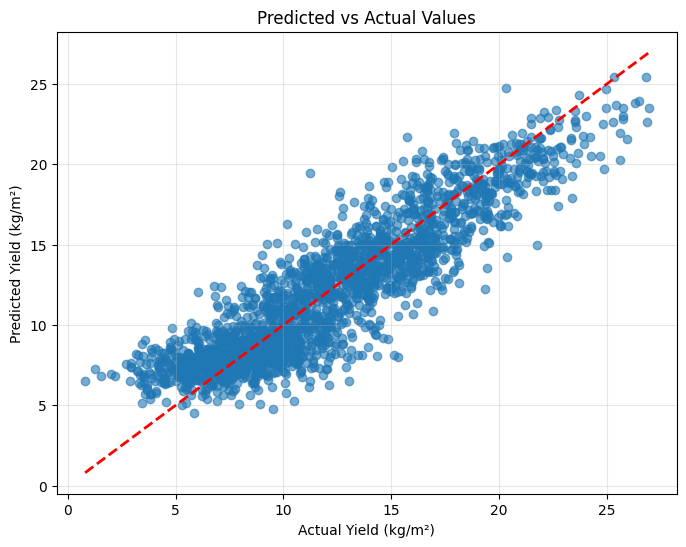

In [ ]:
# Predicted vs Actual Plot

plt.figure(figsize=(8,6))

plt.scatter(
    y_final_test,
    y_pred_final,
    alpha=0.6
)

# Garis prediksi sempurna
plt.plot(
    [y_final_test.min(), y_final_test.max()],
    [y_final_test.min(), y_final_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel('Actual Yield (kg/m²)')
plt.ylabel('Predicted Yield (kg/m²)')
plt.title('Predicted vs Actual Values')
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
""" 
Secara keseluruhan: model bekerja dengan baik.

Yang terlihat positif
- Pola diagonal jelas — titik-titik mengikuti garis merah putus-putus (garis ideal prediksi sempurna) dari kiri bawah ke kanan atas. Ini tanda model sudah menangkap tren dengan benar.
- Distribusi merata — titik tersebar cukup simetris di kedua sisi garis, tidak ada bias sistematis ke atas atau ke bawah.
- Konsisten di semua range — model bekerja cukup baik baik untuk yield rendah (~1-5) maupun yield tinggi (~20-27).

Yang perlu diperhatikan
- Spread melebar di nilai tinggi — di area yield aktual 15-27, titik-titik mulai lebih menyebar menjauhi garis dibanding area rendah. Ini berarti model kurang presisi untuk tanaman dengan yield tinggi.
- Beberapa outlier jauh dari garis — ada beberapa titik yang cukup jauh dari garis diagonal, terutama di kisaran yield 10-20. Ini yang berkontribusi pada RMSE 2.14.
- Slight underestimation di nilai sangat tinggi — di area yield aktual 23-27, beberapa titik berada di bawah garis merah, artinya model cenderung meremehkan yield yang sangat tinggi.

Kesimpulan
Plot ini konsisten dengan R² = 0.806 — model sudah cukup akurat untuk keperluan umum, tapi masih ada ruang untuk meningkatkan presisi di range yield tinggi. Ini wajar untuk Random Forest karena tree-based model memang cenderung kurang baik mengekstrapolasi ke nilai ekstrem.
"""

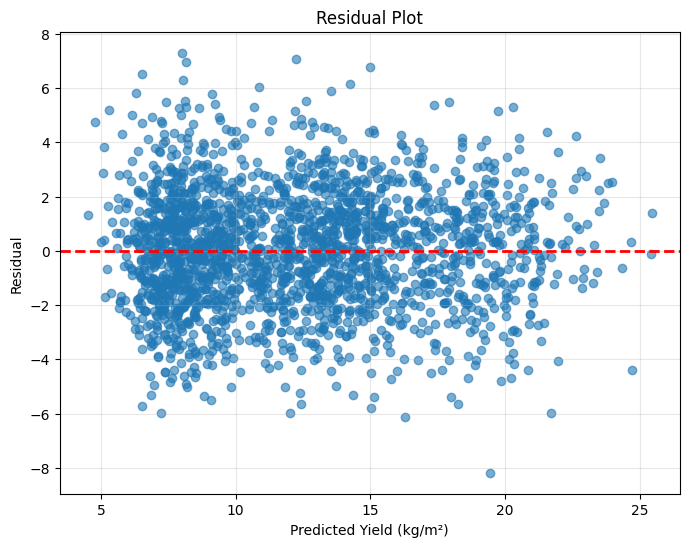

In [ ]:
# Residual Plot 

residuals = y_final_test - y_pred_final

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_final,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel('Predicted Yield (kg/m²)')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
""" 
Yang perlu diperhatikan
1. Heteroscedasticity (spread tidak merata)
Di predicted yield rendah (~5-10), titik sangat rapat dan padat. Di predicted yield tinggi (~15-25), titik mulai menyebar lebih jauh dari garis nol. Ini disebut heteroscedasticity — model lebih tidak konsisten saat memprediksi yield tinggi, sesuai dengan yang terlihat di Predicted vs Actual sebelumnya.

2. Beberapa outlier ekstrem
Ada beberapa titik dengan residual sangat besar:
- Residual +7 di sekitar predicted 13-14
- Residual -8 di sekitar predicted 15
- Ini adalah kasus yang sangat meleset dan perlu ditelusuri — kemungkinan dari crop_type atau kondisi tertentu yang sulit diprediksi model.
3. Sedikit asimetri
Outlier negatif (underprediction) tampak lebih ekstrem (-8) dibanding outlier positif (+7) — model sesekali terlalu meremehkan yield pada kasus tertentu.

Kesimpulan
Residual plot ini normal untuk Random Forest — tidak ada pola melengkung (non-linearity) yang mengkhawatirkan. Masalah utama adalah heteroscedasticity di yield tinggi dan beberapa outlier ekstrem. Untuk memperbaiki ini bisa dicoba:
- Investigasi outlier ekstrem — dari crop_type apa?
- Coba transformasi target seperti log(yield) untuk menstabilkan variance
"""

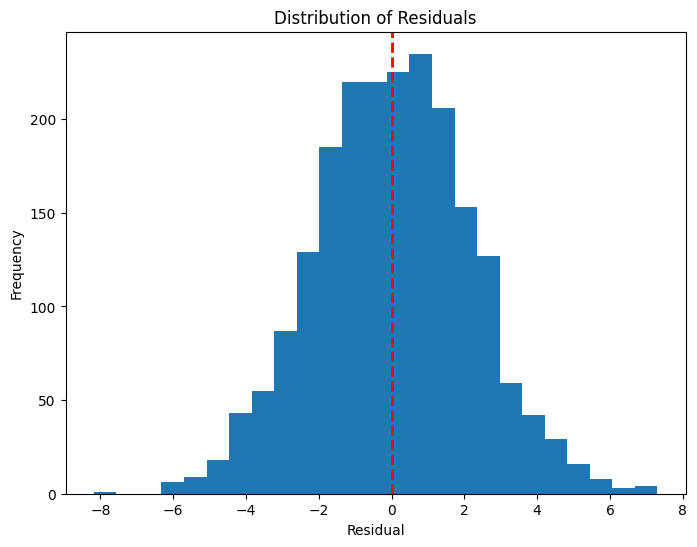

In [ ]:
# Distribution of Residuals

plt.figure(figsize=(8,6))

plt.hist(
    residuals,
    bins=25
)

plt.axvline(
    x=0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')

plt.show()

In [ ]:
""" 
Secara keseluruhan: distribusi residual sangat bagus.

Yang terlihat positif
- Bentuk mendekati normal (bell-shaped) — distribusi membentuk kurva lonceng yang simetris, ini adalah tanda ideal bahwa model tidak punya bias sistematis.
- Puncak tepat di sekitar 0 — garis merah putus-putus (nol) berada di puncak distribusi, artinya error model rata-rata mendekati nol — prediksi tidak secara konsisten terlalu tinggi atau terlalu rendah.
- Simetris kiri-kanan — sisi kiri (underprediction) dan sisi kanan (overprediction) hampir seimbang.

Yang perlu diperhatikan
- Ekor agak tebal di kedua sisi — ada frekuensi kecil di residual -8 dan +7, ini adalah outlier ekstrem yang juga terlihat di residual plot sebelumnya. Jumlahnya sangat sedikit tapi perlu diwaspadai.
- Sedikit right-skewed — puncak distribusi sedikit ke kiri dari 0 (sekitar -0.2 hingga 0), artinya model sedikit cenderung overprediction secara keseluruhan, tapi efeknya sangat kecil.

Kesimpulan
Distribusi residual ini adalah salah satu tanda terbaik bahwa model sudah bekerja dengan benar. Dikombinasikan dengan tiga visualisasi yang sudah dilihat:
"""

In [ ]:
""" 
| Visualisasi               | Kesimpulan                                                     |
| ------------------------- | -------------------------------------------------------------- |
| Predicted vs Actual       | Pola diagonal baik, sedikit spread di yield tinggi             |
| Residual Plot             | Heteroscedasticity ringan di yield tinggi, ada outlier ekstrem |
| Distribution of Residuals | Hampir normal, simetris, pusat di nol ✓                        |
Model ini layak dan sehat untuk digunakan.
"""